# Analyse experiment 4 with original environment

## Action visulization with selection rate

Found 61 episode(s) total.
Plotting 13 episode(s) (every 5th): episodes [1, 6, 11, 16, 21, 26, 31, 36, 41, 46, 51, 56, 61]
Saved → episodes_xz.png / .pdf


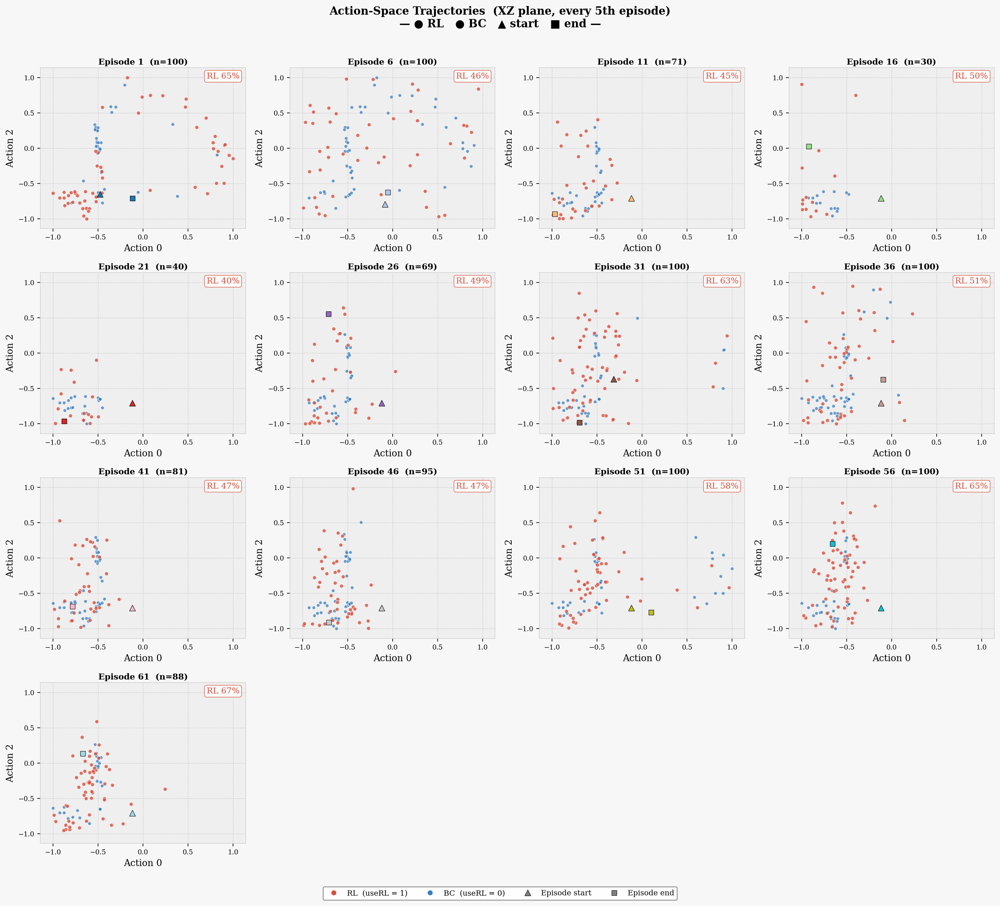

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from matplotlib.colorbar import ColorbarBase
import ast

# ── Load data ──────────────────────────────────────────────────────────────
df = pd.read_csv("demos/memories/2.200.csv")

for col in ["actions.0", "actions.1", "actions.2"]:
    if col in df.columns and df[col].dtype == object:
        df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

df["actions.0"]    = df["actions.0"].astype(float)
df["actions.2"]    = df["actions.2"].astype(float)
df["useRL.0"]      = df["useRL.0"].astype(int)
df["truncated.0"]  = df["truncated.0"].astype(int)
df["terminated.0"] = df["terminated.0"].astype(int)


# ── Split into episodes ────────────────────────────────────────────────────
# Episode ends when BOTH truncated.0 == 1 AND terminated.0 == 1
episode_end  = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
episode_ids  = episode_end.shift(1, fill_value=0).cumsum()
all_episodes = [grp for _, grp in df.groupby(episode_ids)]
n_ep_total   = len(all_episodes)
print(f"Found {n_ep_total} episode(s) total.")

# ── Select every 5th episode (0-indexed: 0, 5, 10, …) ─────────────────────
sel_indices  = list(range(0, n_ep_total, 5))
episodes     = [(orig_idx, all_episodes[orig_idx]) for orig_idx in sel_indices]
n_ep         = len(episodes)
print(f"Plotting {n_ep} episode(s) (every 5th): episodes {[i+1 for i,_ in episodes]}")

# ── Global style ───────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family":     "serif",
    "font.serif":      ["Palatino", "Georgia", "Times New Roman", "DejaVu Serif"],
    "axes.labelsize":  11,
    "axes.titlesize":  10,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "figure.dpi":      180,
    "savefig.dpi":     300,
    "savefig.bbox":    "tight",
})

BLUE = "#3A7EBF"   # BC  (useRL = 0)
RED  = "#D94F3D"   # RL  (useRL = 1)
ep_cmap = cm.get_cmap("tab20", max(n_ep, 1))

COLS = min(4, n_ep)
ROWS = int(np.ceil(n_ep / COLS))

# Shared axis limits
all_x = df["actions.0"].values
all_z = df["actions.2"].values
x_pad = (all_x.max() - all_x.min()) * 0.07 or 0.1
z_pad = (all_z.max() - all_z.min()) * 0.07 or 0.1
xlim  = (all_x.min() - x_pad, all_x.max() + x_pad)
zlim  = (all_z.min() - z_pad, all_z.max() + z_pad)

# ═══════════════════════════════════════════════════════════════════════════
# FIGURE 1 — Trajectory plot (RL vs BC)
# ═══════════════════════════════════════════════════════════════════════════
fig1, axes1 = plt.subplots(
    ROWS, COLS,
    figsize=(4.2 * COLS, 3.6 * ROWS),
    squeeze=False,
)
fig1.patch.set_facecolor("#F7F7F7")
fig1.suptitle(
    "Action-Space Trajectories  (XZ plane, every 5th episode)\n"
    "— ● RL   ● BC   ▲ start   ■ end —",
    fontsize=13, fontweight="bold", y=1.01,
)

for plot_idx, (orig_idx, ep_df) in enumerate(episodes):
    row, col = divmod(plot_idx, COLS)
    ax = axes1[row][col]

    x_ep  = ep_df["actions.0"].values
    z_ep  = ep_df["actions.2"].values
    rl_ep = ep_df["useRL.0"].values
    ep_color = ep_cmap(plot_idx)

    mask_rl = rl_ep == 1
    mask_bc = rl_ep == 0

    if mask_bc.any():
        ax.scatter(x_ep[mask_bc], z_ep[mask_bc],
                   c=BLUE, s=16, alpha=0.75,
                   edgecolors="white", linewidths=0.5, zorder=3)
    if mask_rl.any():
        ax.scatter(x_ep[mask_rl], z_ep[mask_rl],
                   c=RED, s=20, alpha=0.80,
                   edgecolors="white", linewidths=0.5, zorder=4)

    ax.plot(x_ep[0],  z_ep[0],  marker="^", ms=7,
            color=ep_color, markeredgecolor="k",
            markeredgewidth=0.5, zorder=5, clip_on=False)
    ax.plot(x_ep[-1], z_ep[-1], marker="s", ms=6,
            color=ep_color, markeredgecolor="k",
            markeredgewidth=0.5, zorder=5, clip_on=False)

    frac_rl = mask_rl.mean()
    ax.text(0.97, 0.97, f"RL {frac_rl:.0%}",
            transform=ax.transAxes, fontsize=10,
            ha="right", va="top", color=RED,
            bbox=dict(boxstyle="round,pad=0.25", fc="white",
                      ec=RED, alpha=0.85, lw=0.7))

    ax.set_xlim(xlim); ax.set_ylim(zlim)
    ax.set_facecolor("#EFEFEF")
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.6)
    for spine in ax.spines.values():
        spine.set_color("#CCCCCC")
    ax.set_title(f"Episode {orig_idx + 1}  (n={len(ep_df)})",
                 fontweight="bold", pad=4)
    ax.set_xlabel("Action 0")
    ax.set_ylabel("Action 2")

for idx in range(n_ep, ROWS * COLS):
    row, col = divmod(idx, COLS)
    axes1[row][col].set_visible(False)

legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=RED,
           markersize=7, label="RL  (useRL = 1)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=BLUE,
           markersize=7, label="BC  (useRL = 0)"),
    Line2D([0], [0], marker="^", color="gray", markersize=7,
           markeredgecolor="k", markeredgewidth=0.5,
           linestyle="none", label="Episode start"),
    Line2D([0], [0], marker="s", color="gray", markersize=6,
           markeredgecolor="k", markeredgewidth=0.5,
           linestyle="none", label="Episode end"),
]
fig1.legend(handles=legend_elements, loc="lower center",
            ncol=4, fontsize=9, framealpha=0.9,
            edgecolor="gray", bbox_to_anchor=(0.5, -0.03))

plt.tight_layout()
fig1.savefig("demos/memories/episodes_xz.png", facecolor=fig1.get_facecolor())
fig1.savefig("demos/memories/episodes_xz.pdf", facecolor=fig1.get_facecolor())
print("Saved → episodes_xz.png / .pdf")



## Q + IBRL

  Replay (BC only): 143 total → plotting indices [0, 2]
  Checkpoint 4.01: 68 total → plotting indices [0, 2]
  Checkpoint 4.11: 10 total → plotting indices [0, 2]
  Checkpoint 4.21: 52 total → plotting indices [0, 2]

Saved → demos/memories/trajectories_3d.png / .pdf


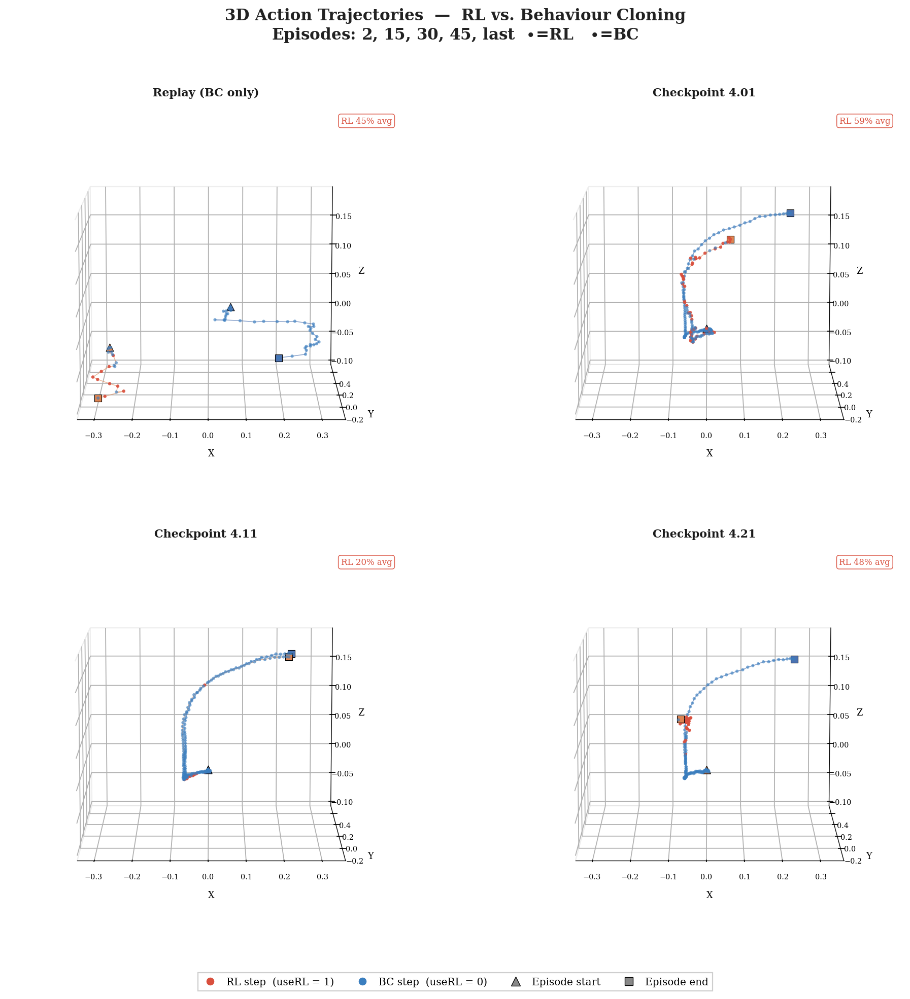

In [1]:
"""
3D Trajectory Visualiser
========================
- Episodes 2, 15, 30, 45 and the last episode
- All labels rendered in 2D screen-space (no 3D text = no overlap)
- X–Z as the primary face  (elev=10, azim=-90)
- Transparent background
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from mpl_toolkits.mplot3d import Axes3D          # noqa: F401
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings("ignore")

# ── Paths ──────────────────────────────────────────────────────────────────
FILES = {
    # "Replay (BC only)": "./demos/memories/replay_.csv",  # "./demos/Peginhole/10demos.csv"
    "Replay (BC only)": "./demos/memories/peginhole_osrl0.csv",


    "Checkpoint 4.01":  "./demos/memories/2.202.csv",
    "Checkpoint 4.11":  "./demos/memories/exp1_1.0.csv",  #1.200
    "Checkpoint 4.21":  "./demos/memories/2.303_AWR.csv",  #1.203
}

# ── Colour palette ─────────────────────────────────────────────────────────
C_RL   = "#D94F3D"
C_BC   = "#3A7EBF"
C_GRID = "#DEDEDE"

EP_PALETTE = [
    "#4C72B0", "#DD8452", "#55A868", "#C44E52",
    "#8172B3", "#937860", "#DA8BC3", "#8C8C8C",
    "#CCB974", "#64B5CD",
]

# TARGET_EPISODES = [0,2, 15, 30, 45]
TARGET_EPISODES = [0,2]

# ── Global style ───────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["Palatino Linotype", "Palatino", "Georgia",
                         "Times New Roman", "DejaVu Serif"],
    "axes.labelsize":   9,
    "axes.titlesize":   10,
    "xtick.labelsize":  7,
    "ytick.labelsize":  7,
    "figure.dpi":       160,
    "savefig.dpi":      300,
    "savefig.bbox":     "tight",
    "axes.linewidth":   0.6,
})


# ── Helpers ────────────────────────────────────────────────────────────────

def load_and_split(path: str):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["useRL.0"]      = df["useRL.0"].astype(int)
    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    episodes = [grp.reset_index(drop=True) for _, grp in df.groupby(ep_ids)]
    return episodes


def select_episodes(episodes):
    n = len(episodes)
    indices = TARGET_EPISODES 
    seen = set()
    selected = []
    for i in indices:
        i = min(i, n - 1)
        if i not in seen:
            seen.add(i)
            selected.append((i, episodes[i]))
    return selected


def trajectory_xyz(ep_df):
    x = ep_df["observations.0"].values.astype(float)
    y = ep_df["observations.1"].values.astype(float)
    z = ep_df["observations.2"].values.astype(float)
    return x, y, z


def rl_mask(ep_df):
    return ep_df["useRL.0"].values.astype(bool)


# ── Load data ──────────────────────────────────────────────────────────────
data = {}
for label, path in FILES.items():
    try:
        eps = load_and_split(path)
        selected = select_episodes(eps)
        data[label] = selected
        plotted_ids = [i for i, _ in selected]
        print(f"  {label}: {len(eps)} total → plotting indices {plotted_ids}")
    except FileNotFoundError:
        print(f"  [WARN] File not found, skipping: {path}")

if not data:
    raise RuntimeError("No data files found — check paths.")

# ── Global axis limits ─────────────────────────────────────────────────────
all_x, all_y, all_z = [], [], []
for label, selected in data.items():
    for _, ep_df in selected:
        x, y, z = trajectory_xyz(ep_df)
        all_x.extend(x); all_y.extend(y); all_z.extend(z)

def padded(vals, frac=0.06):
    lo, hi = np.min(vals), np.max(vals)
    p = (hi - lo) * frac or 0.1
    return lo - p, hi + p

xlim = padded(all_x)
ylim = padded(all_y)
zlim = padded(all_z)


# ── Figure layout ──────────────────────────────────────────────────────────
n_panels = len(data)
COLS = 2
ROWS = int(np.ceil(n_panels / COLS))

fig = plt.figure(figsize=(6.5 * COLS, 5.8 * ROWS), facecolor="none")
fig.suptitle(
    "3D Action Trajectories  —  RL vs. Behaviour Cloning\n"
    r"Episodes: 2, 15, 30, 45, last  $\bullet$=RL   $\bullet$=BC",
    fontsize=14, fontweight="bold", y=1.01, color="#222222",
)

for panel_idx, (label, selected) in enumerate(data.items()):
    ax = fig.add_subplot(ROWS, COLS, panel_idx + 1, projection="3d")

    # ── Transparent panes ──────────────────────────────────────────────────
    for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
        pane.fill = False
        pane.set_edgecolor(C_GRID)
    ax.set_facecolor("none")
    ax.grid(True, linestyle=":", linewidth=0.4, alpha=0.7)
    ax.tick_params(axis="both", which="major", labelsize=6.5, pad=1)

    # ── Plot each selected episode ─────────────────────────────────────────
    ep_legend_handles = [0,1,5, 10, 20]   # collect handles for the per-panel legend

    for ep_num, (orig_idx, ep_df) in enumerate(selected):
        x, y, z = trajectory_xyz(ep_df)
        rl       = rl_mask(ep_df)
        rl_rate  = rl.mean()

        # ── SPECIAL CASE: replay episode (episode 0) ───────────────────────────
        is_replay = (orig_idx == 0)

        if is_replay:
            rl_rate = 0.0
            rl = np.zeros_like(rl, dtype=bool)  # force NO RL usage
        else:
            rl_rate = rl.mean()

        ep_color   = EP_PALETTE[ep_num % len(EP_PALETTE)]
        alpha_line = max(0.18, 0.65 - ep_num * 0.08)

        # Trajectory line
        ax.plot(x, y, z,
                color=ep_color, linewidth=0.7, alpha=alpha_line, zorder=1)

        # BC dots
        if (~rl).any():
            ax.scatter(x[~rl], y[~rl], z[~rl],
                       c=C_BC, s=8, alpha=0.65,
                       edgecolors="none", zorder=2, depthshade=True)
            
        # ── RL dots (ONLY if not replay) ───────────────────────────────────────
        if (not is_replay) and rl.any():
            ax.scatter(x[rl], y[rl], z[rl],
                    c=C_RL, s=8, alpha=0.65,
                    edgecolors="none", zorder=2, depthshade=True)


        # RL dots
        if rl.any():
            ax.scatter(x[rl], y[rl], z[rl],
                       c=C_RL, s=8, alpha=0.75,
                       edgecolors="none", zorder=3, depthshade=True)

        # Start marker (triangle)
        ax.scatter([x[0]], [y[0]], [z[0]],
                   marker="^", s=45, c=[ep_color],
                   edgecolors="k", linewidths=0.5, zorder=5, depthshade=False)

        # End marker (square) — NO 3D text near it any more
        ax.scatter([x[-1]], [y[-1]], [z[-1]],
                   marker="s", s=35, c=[ep_color],
                   edgecolors="k", linewidths=0.5, zorder=5, depthshade=False)

        # ── Legend label ───────────────────────────────────────────────────────
        if is_replay:
            label_text = f"replay     RL 0%"
        else:
            label_text = f"ep {orig_idx:<3}  RL {rl_rate:.0%}"

        # ── Build a legend handle for this episode (drawn in 2D later) ────
        # Line swatch coloured to match the trajectory
        handle = Line2D(
            [0], [0],
            color=ep_color, linewidth=4,
            solid_capstyle="round",
            label=f"ep {orig_idx: <3}  RL {rl_rate:.0%}",
        )
        ep_legend_handles.append(handle)

    # # ── Per-panel episode legend (2D, fixed screen position) ──────────────
    # # Anchored to lower-left; bbox_to_anchor keeps it inside the axes frame.
    # ep_legend = ax.legend(
    #     handles=ep_legend_handles,
    #     loc="lower left",
    #     bbox_to_anchor=(0.01, 0.01),    # just inside the lower-left corner
    #     fontsize=6.8,
    #     framealpha=0.82,
    #     edgecolor="#BBBBBB",
    #     fancybox=False,
    #     handlelength=1.2,
    #     handletextpad=0.5,
    #     labelspacing=0.35,
    #     borderpad=0.55,
    #     title="episode · RL rate",
    #     title_fontsize=6.2,
    # )
    # # Style the legend title
    # ep_legend.get_title().set_color("#555555")
    # ep_legend.get_title().set_fontstyle("italic")
    # ax.add_artist(ep_legend)   # keep it when we add the second legend below

    # ── Mean RL badge (top-right, 2D) ─────────────────────────────────────
    rl_fracs  = [rl_mask(ep_df).mean() for _, ep_df in selected]
    frac_mean = np.mean(rl_fracs) if rl_fracs else 0
    ax.text2D(0.97, 0.97, f"RL {frac_mean:.0%} avg",
              transform=ax.transAxes, fontsize=7.5,
              ha="right", va="top", color=C_RL,
              bbox=dict(boxstyle="round,pad=0.3", fc="white",
                        ec=C_RL, alpha=0.88, lw=0.7))

    # ── Axis limits & labels ───────────────────────────────────────────────
    ax.set_xlim(xlim); ax.set_ylim(ylim); ax.set_zlim(zlim)
    ax.set_xlabel("X", labelpad=3, fontsize=8)
    ax.set_ylabel("Y", labelpad=3, fontsize=8)
    ax.set_zlabel("Z", labelpad=3, fontsize=8)
    ax.set_title(label, fontweight="bold", pad=8, fontsize=10, color="#1A1A1A")

    # ── View angle: X–Z as primary face ───────────────────────────────────
    ax.view_init(elev=10, azim=-90)

# ── Hide unused slots ──────────────────────────────────────────────────────
for idx in range(n_panels, ROWS * COLS):
    fig.add_subplot(ROWS, COLS, idx + 1).set_visible(False)

# ── Shared bottom legend (marker types only) ───────────────────────────────
shared_legend = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=C_RL,
           markersize=8, label="RL step  (useRL = 1)"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=C_BC,
           markersize=8, label="BC step  (useRL = 0)"),
    Line2D([0], [0], marker="^", color="#888888", markersize=8,
           markeredgecolor="k", markeredgewidth=0.6,
           linestyle="none", label="Episode start"),
    Line2D([0], [0], marker="s", color="#888888", markersize=7,
           markeredgecolor="k", markeredgewidth=0.6,
           linestyle="none", label="Episode end"),
]
fig.legend(
    handles=shared_legend,
    loc="lower center", ncol=4,
    fontsize=9, framealpha=0.95,
    edgecolor="#CCCCCC", fancybox=False,
    bbox_to_anchor=(0.5, -0.04),
    handlelength=1.6,
)

plt.tight_layout(pad=1.5, h_pad=2.5, w_pad=1.5)
fig.savefig("demos/memories/trajectories_3d.png", transparent=True, bbox_inches="tight")
fig.savefig("demos/memories/trajectories_3d.pdf", transparent=True, bbox_inches="tight")
print("\nSaved → demos/memories/trajectories_3d.png / .pdf")
plt.show()

## plot rewards, rl select rate and Q-value estimates


Rendering dataset: Checkpoint 4.21

Saved:
  demos/trajectory_labeled_ends_3d0.png
  demos/trajectory_labeled_ends_3d0.pdf


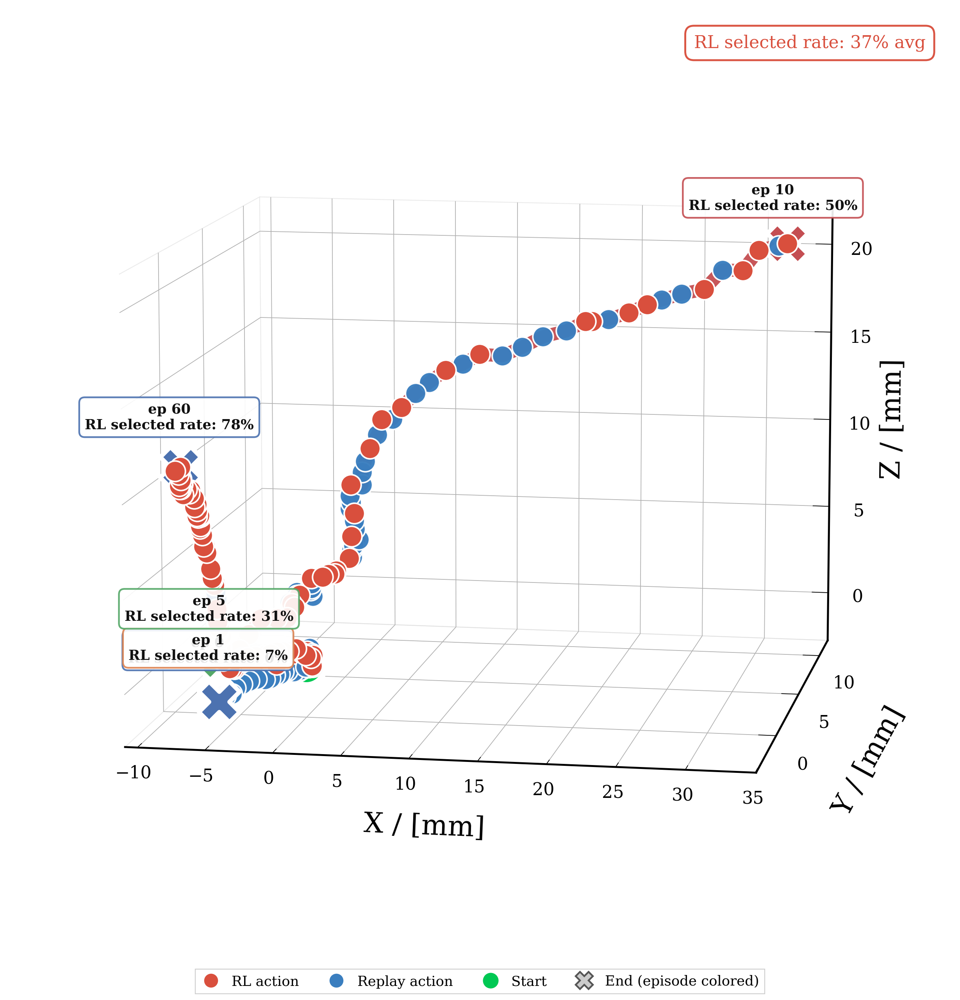

In [ ]:
"""
3D Trajectory Visualiser (Clean Optimised Version - End Labeled)
===============================================================
- Single final dataset only
- Reduced axis tick label sizes
- Very large visible start/end markers
- End markers use episode color to differentiate episodes
- End markers labeled directly with "RL selected rate"
- Thick trajectory lines
- Large readable scatter points
- Transparent background
- X–Z primary face
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D          # noqa: F401
from matplotlib.lines import Line2D
import warnings

warnings.filterwarnings("ignore")

# ───────────────────────────────────────────────────────────────────────────
# Paths
# ───────────────────────────────────────────────────────────────────────────
FILES = {
    # "Replay (BC only)": "./demos/memories/replay_.csv",
    # "Replay (BC only)": "./demos/memories/peginhole_osrl0.csv",
    # "Checkpoint 4.01":  "./demos/memories/0.2.csv",
    # "Checkpoint 4.21": "./demos/memories/replay_.csv",
    # "Checkpoint 4.21":  "./demos/memories/2.71.csv",
    # "Checkpoint 4.21*":  "./demos/memories/2.101_maxq.csv",
    # "Checkpoint 4.21":  "./demos/memories/0.001.csv", 
    # "Checkpoint 4.21":  "./demos/memories/peginhole_osrl0.csv",
    # "Checkpoint 4.21*":  "./demos/memories/plugin_osrl2.csv",
    # "Checkpoint 4.21*":  "./demos/memories/plugin_IBRL1.csv",
    # ── Paths ──────────────────────────────────────────────────────────────────
    # "Replay (BC only)": "./demos/memories/replay_.csv",  # "./demos/Peginhole/10demos.csv"
    # "Replay (BC only)": "./demos/memories/peginhole_osrl0.csv",


    # "Checkpoint 4.21":  "./demos/memories/2.201.csv",
    # "Checkpoint 4.21":  "./demos/memories/1.200.csv",  #1.200
    # "Checkpoint 4.21":  "./demos/memories/2.303_AWR.csv",  #1.203
    "Checkpoint 4.21":  "./demos/memories/2.400.csv",  #1.203

}

# ───────────────────────────────────────────────────────────────────────────
# Colours
# ───────────────────────────────────────────────────────────────────────────
C_RL      = "#D94F3D" 
C_BC      = "#3A7EBF" 
C_GRID    = "#D9D9D9" 
C_TEXT    = "#111111"
C_START   = "#00C853" 

EP_PALETTE = [
    "#4C72B0", 
    "#DD8452", 
    "#55A868", 
    "#C44E52", 
]

# ───────────────────────────────────────────────────────────────────────────
# Config
# ───────────────────────────────────────────────────────────────────────────
TARGET_EPISODES = [0, 1, 5, 10, 110, 120, 130]  # 1,  5, 10
# TARGET_EPISODES = []  # 1,  5, 10

# Trajectory appearance
LINE_WIDTH   = 15
POINT_SIZE   = 560 

# Start / End markers
START_SIZE   = 1800 
END_SIZE     = 2200 

# Axis text sizing
TICK_SIZE    = 20    
LABEL_SIZE   = 32    
TITLE_SIZE   = 38    
LEGEND_SIZE  = 20    

# ───────────────────────────────────────────────────────────────────────────
# Matplotlib style
# ───────────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Palatino Linotype",
        "Palatino",
        "Georgia",
        "Times New Roman",
        "DejaVu Serif"
    ],
    "axes.linewidth": 2.2,
    "figure.dpi": 160,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# ───────────────────────────────────────────────────────────────────────────
# Helpers
# ───────────────────────────────────────────────────────────────────────────
def load_and_split(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["useRL.0"]      = df["useRL.0"].astype(int)

    ep_end = (
        (df["truncated.0"] == 1) |
        (df["terminated.0"] == 1)
    ).astype(int)

    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [grp.reset_index(drop=True) for _, grp in df.groupby(ep_ids)]


def select_episodes(episodes):
    n = len(episodes)
    indices = TARGET_EPISODES + [n - 2]
    selected = []
    seen = set()
    for i in indices:
        i = min(i, n - 2) 
        if i not in seen:
            seen.add(i)
            selected.append((i, episodes[i]))
    return selected


def trajectory_xyz(ep_df):
    x = ep_df["observations.0"].values.astype(float)*100
    y = ep_df["observations.1"].values.astype(float)*100
    z = ep_df["observations.2"].values.astype(float)*100
    return x, y, z


def rl_mask(ep_df):
    return ep_df["useRL.0"].values.astype(bool)


def padded(vals, frac=0.08):
    lo, hi = np.min(vals), np.max(vals)
    p = (hi - lo) * frac or 0.1 
    return lo - p, hi + p


# ───────────────────────────────────────────────────────────────────────────
# MAIN execution: Load final dataset only
# ───────────────────────────────────────────────────────────────────────────
last_label, last_path = list(FILES.items())[0]
episodes = load_and_split(last_path)
selected = select_episodes(episodes)

print(f"\nRendering dataset: {last_label}")

all_x, all_y, all_z = [], [], []
for _, ep_df in selected:
    x, y, z = trajectory_xyz(ep_df)
    all_x.extend(x)
    all_y.extend(y)
    all_z.extend(z)

xlim = padded(all_x)
ylim = padded(all_y)
zlim =  padded(all_z)

# ───────────────────────────────────────────────────────────────────────────
# Figure Initialization
# ───────────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 16), facecolor="none")
ax = fig.add_subplot(111, projection="3d")

for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
    pane.fill = False 
    pane.set_edgecolor(C_GRID)

ax.set_facecolor("none")
ax.grid(True, linestyle=":", linewidth=1.1, alpha=0.65)

ax.tick_params(axis="both", which="major", labelsize=TICK_SIZE, pad=8)

# ───────────────────────────────────────────────────────────────────────────
# Plot Episodes
# ───────────────────────────────────────────────────────────────────────────
legend_handles = [0]

for ep_num, (orig_idx, ep_df) in enumerate(selected):
    x, y, z = trajectory_xyz(ep_df)
    rl = rl_mask(ep_df)

    is_replay = (orig_idx == 0)
    if is_replay:
        # x, y, z = trajectory_xyz(ep_df)
        rl_rate = 0.0
        rl = np.zeros_like(rl, dtype=bool) 
    else:
        # rl_rate = 0.0
        # rl = np.zeros_like(rl, dtype=bool) 
        rl_rate = rl.mean()

    ep_color = EP_PALETTE[ep_num % len(EP_PALETTE)]

    # 1. Trajectory line
    ax.plot(x, y, z, color=ep_color, linewidth=LINE_WIDTH, alpha=0.95, solid_capstyle="round", zorder=1)

    # 2. BC points
    if (~rl).any():
        ax.scatter(x[~rl], y[~rl], z[~rl], c=C_BC, s=POINT_SIZE, alpha=0.97, edgecolors="white", linewidths=1.8, depthshade=False, zorder=3)

    # 3. RL points
    if (not is_replay) and rl.any():
        ax.scatter(x[rl], y[rl], z[rl], c=C_RL, s=POINT_SIZE, alpha=1.0, edgecolors="white", linewidths=1.8, depthshade=False, zorder=4)

    # 4. HUGE START MARKER
    ax.scatter([x[0]], [y[0]], [z[0]], marker="o", s=START_SIZE, c=C_START, edgecolors="white", linewidths=6, depthshade=False, zorder=20)

    # 5. HUGE END MARKER (colored by episode)
    ax.scatter([x[-1]], [y[-1]], [z[-1]], marker="X", s=END_SIZE, c=ep_color, edgecolors="white", linewidths=5, depthshade=False, zorder=21)

    # 6. Direct Endpoint Annotation: Labeled directly on each episode end
    label_text = f"ep {orig_idx}\nRL selected rate: {rl_rate:.0%}"
    # label_text = f"Demonstration replay"
    ax.text(
        x[-1]-1.5, y[-1]+1, z[-1] + 1.5,  # Slightly offset upwards on the Z-axis to clear the oversized marker
        label_text,
        color=C_TEXT,
        fontsize=16,
        fontweight="bold",
        ha="center",
        va="bottom",
        zorder=30,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=ep_color, lw=2, alpha=0.9)
    )

    # Legend Handle updates text formatting to match requirement
    handle = Line2D(
        [0], [0],
        color=ep_color,
        linewidth=8,
        solid_capstyle="round",
        label=f"ep {orig_idx:<3}   RL selected rate: {rl_rate:.0%}",
    )
    legend_handles.append(handle)

# # ───────────────────────────────────────────────────────────────────────────
# # Episode Legend (lower left)
# # ───────────────────────────────────────────────────────────────────────────
# ep_legend = ax.legend(
#     handles=legend_handles,
#     loc="lower left",
#     bbox_to_anchor=(0.02, 0.03),
#     fontsize=LEGEND_SIZE,
#     framealpha=0.96,
#     edgecolor="#BBBBBB",
#     fancybox=False,
#     handlelength=2.2,
#     handletextpad=1.0,
#     borderpad=1.0,
#     labelspacing=0.8,
#     title="episode · details",
#     title_fontsize=LEGEND_SIZE,
# )
# ep_legend.get_title().set_fontstyle("italic")
# ax.add_artist(ep_legend) 

# ───────────────────────────────────────────────────────────────────────────
# RL Selected Rate Badge (top right updates)
# ───────────────────────────────────────────────────────────────────────────
rl_fracs = [rl_mask(ep_df).mean() for _, ep_df in selected]
frac_mean = np.mean(rl_fracs)

ax.text2D(
    0.97, 0.97,
    f"RL selected rate: {frac_mean:.0%} avg",
    transform=ax.transAxes,
    fontsize=20,
    ha="right", va="top",
    color=C_RL,
    bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=C_RL, lw=2.2, alpha=0.96)
)

# ───────────────────────────────────────────────────────────────────────────
# Axes Configuration & Formatting
# ───────────────────────────────────────────────────────────────────────────
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_zlim(zlim)

TICKS_EVERY_MM = 5
ax.xaxis.set_major_locator(MultipleLocator(TICKS_EVERY_MM))
ax.yaxis.set_major_locator(MultipleLocator(TICKS_EVERY_MM))
ax.zaxis.set_major_locator(MultipleLocator(TICKS_EVERY_MM))

# ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
# ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
# ax.zaxis.set_major_formatter(FormatStrFormatter('%.2f'))

ax.tick_params(axis="x", labelsize=TICK_SIZE, pad=8)
ax.tick_params(axis="y", labelsize=TICK_SIZE, pad=16) 
ax.tick_params(axis="z", labelsize=TICK_SIZE, pad=18) 

ax.set_xlabel("X / [mm]", fontsize=LABEL_SIZE, labelpad=40)
ax.set_ylabel("Y / [mm]", fontsize=LABEL_SIZE, labelpad=50)
ax.set_zlabel("Z / [mm]", fontsize=LABEL_SIZE, labelpad=35)

ax.xaxis._axinfo["tick"]["inward_factor"] = 0.0
ax.yaxis._axinfo["tick"]["inward_factor"] = 0.0
ax.zaxis._axinfo["tick"]["inward_factor"] = 0.0

ax.xaxis._axinfo["tick"]["outward_factor"] = 0.35
ax.yaxis._axinfo["tick"]["outward_factor"] = 0.35
ax.zaxis._axinfo["tick"]["outward_factor"] = 0.35

# Camera View (set for X-Z primary face)
# ax.view_init(elev=0, azim=10)
ax.view_init(elev=10, azim=-80)

# ───────────────────────────────────────────────────────────────────────────
# Shared Global Legend
# ───────────────────────────────────────────────────────────────────────────
shared_legend = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=C_RL, markeredgecolor="white", markeredgewidth=2, markersize=18, label="RL action"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=C_BC, markeredgecolor="white", markeredgewidth=2, markersize=18, label="Replay action"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=C_START, markeredgecolor="white", markeredgewidth=2, markersize=20, label="Start"),
    Line2D([0], [0], marker="X", color="w", markerfacecolor="#CCCCCC", markeredgecolor="#555555", markeredgewidth=2, markersize=20, label="End (episode colored)")
]

fig.legend(
    handles=shared_legend,
    loc="lower center",
    ncol=4,
    fontsize=16,
    framealpha=0.96,
    edgecolor="#CCCCCC",
    fancybox=False,
    bbox_to_anchor=(0.5, -0.02), 
    handlelength=1.4,
)

plt.tight_layout(pad=3.0)

SAVE_DIR = "demos/"
fn_stem = "trajectory_labeled_ends_3d0"

fig.savefig(f"{SAVE_DIR}{fn_stem}.png", transparent=True)
fig.savefig(f"{SAVE_DIR}{fn_stem}.pdf", transparent=True)

print(f"\nSaved:\n  {SAVE_DIR}{fn_stem}.png\n  {SAVE_DIR}{fn_stem}.pdf")
plt.show()


Rendering dataset: Checkpoint 4.21

Saved:
  demos/trajectory_labeled_ends_3d1.png
  demos/trajectory_labeled_ends_3d1.pdf


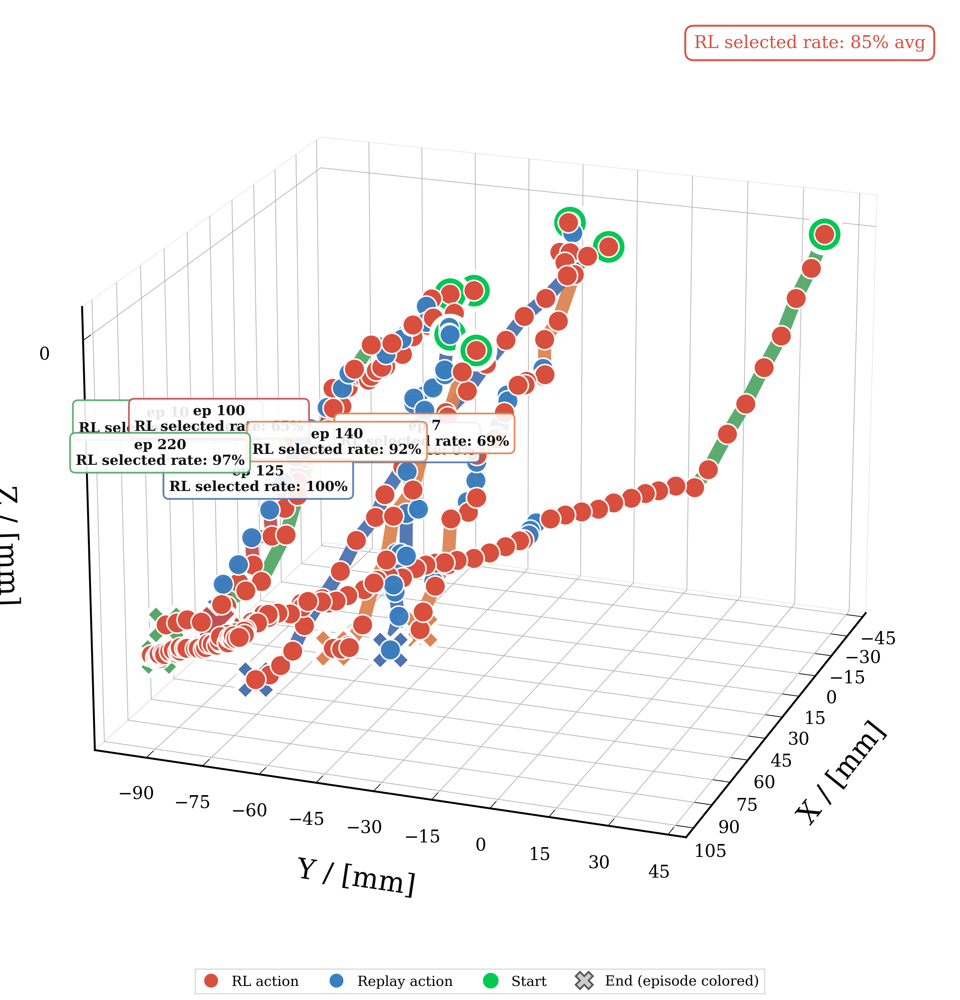

In [67]:
"""
3D Trajectory Visualiser (Clean Optimised Version - End Labeled)
===============================================================
- Single final dataset only
- Reduced axis tick label sizes
- Very large visible start/end markers
- End markers use episode color to differentiate episodes
- End markers labeled directly with "RL selected rate"
- Thick trajectory lines
- Large readable scatter points
- Transparent background
- X–Z primary face
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D          # noqa: F401
from matplotlib.lines import Line2D
import warnings

warnings.filterwarnings("ignore")

# ───────────────────────────────────────────────────────────────────────────
# Paths
# ───────────────────────────────────────────────────────────────────────────
FILES = {
    # "Replay (BC only)": "./demos/memories/replay_.csv",
    # "Replay (BC only)": "./demos/memories/peginhole_osrl0.csv",
    # "Checkpoint 4.01":  "./demos/memories/0.2.csv",
    # "Checkpoint 4.21": "./demos/memories/replay_.csv",
    # "Checkpoint 4.21":  "./demos/memories/2.71.csv",
    # "Checkpoint 4.21*":  "./demos/memories/nn2.20_utd1.csv",
    # "Checkpoint 4.21":  "./demos/memories/2.203.csv", 
    # "Checkpoint 4.21":  "./demos/memories/peginhole_osrl0.csv",
    "Checkpoint 4.21":  "./demos/memories/peginhole_ibrl1.csv",
    # "Checkpoint 4.21*":  "./demos/memories/plugin_osrl2.csv",
    # "Checkpoint 4.21*":  "./demos/memories/plugin_IBRL1.csv",
}

# ───────────────────────────────────────────────────────────────────────────
# Colours
# ───────────────────────────────────────────────────────────────────────────
C_RL      = "#D94F3D" 
C_BC      = "#3A7EBF" 
C_GRID    = "#D9D9D9" 
C_TEXT    = "#111111"
C_START   = "#00C853" 

EP_PALETTE = [
    "#4C72B0", 
    "#DD8452", 
    "#55A868", 
    "#C44E52", 
]

# ───────────────────────────────────────────────────────────────────────────
# Config
# ───────────────────────────────────────────────────────────────────────────
TARGET_EPISODES = [6, 7, 10, 100, 125, 140]  # 1,  5, 10
# TARGET_EPISODES = [0, 1, 3, 5, 7, 10]  # 1,  5, 10

# Trajectory appearance
LINE_WIDTH   = 15
POINT_SIZE   = 560 

# Start / End markers
START_SIZE   = 1800 
END_SIZE     = 2200 

# Axis text sizing
TICK_SIZE    = 20    
LABEL_SIZE   = 32    
TITLE_SIZE   = 38    
LEGEND_SIZE  = 20    

# ───────────────────────────────────────────────────────────────────────────
# Matplotlib style
# ───────────────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Palatino Linotype",
        "Palatino",
        "Georgia",
        "Times New Roman",
        "DejaVu Serif"
    ],
    "axes.linewidth": 2.2,
    "figure.dpi": 160,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# ───────────────────────────────────────────────────────────────────────────
# Helpers
# ───────────────────────────────────────────────────────────────────────────
def load_and_split(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["useRL.0"]      = df["useRL.0"].astype(int)

    ep_end = (
        (df["truncated.0"] == 1) |
        (df["terminated.0"] == 1)
    ).astype(int)

    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [grp.reset_index(drop=True) for _, grp in df.groupby(ep_ids)]


def select_episodes(episodes):
    n = len(episodes)
    indices = TARGET_EPISODES + [n - 2]
    selected = []
    seen = set()
    for i in indices:
        i = min(i, n - 3) 
        if i not in seen:
            seen.add(i)
            selected.append((i, episodes[i]))
    return selected


def trajectory_xyz(ep_df):
    x = ep_df["observations.0"].values.astype(float)*100
    y = ep_df["observations.1"].values.astype(float)*100
    z = ep_df["observations.2"].values.astype(float)*100
    return x, y, z


def rl_mask(ep_df):
    return ep_df["useRL.0"].values.astype(bool)


def padded(vals, frac=0.08):
    lo, hi = np.min(vals), np.max(vals)
    p = (hi - lo) * frac or 0.1 
    return lo - p, hi + p


# ───────────────────────────────────────────────────────────────────────────
# MAIN execution: Load final dataset only
# ───────────────────────────────────────────────────────────────────────────
last_label, last_path = list(FILES.items())[0]
episodes = load_and_split(last_path)
selected = select_episodes(episodes)

print(f"\nRendering dataset: {last_label}")

all_x, all_y, all_z = [], [], []
for _, ep_df in selected:
    x, y, z = trajectory_xyz(ep_df)
    all_x.extend(x)
    all_y.extend(y)
    all_z.extend(z)

xlim = padded(all_x)
ylim = padded(all_y)
zlim =  padded(all_z)

# ───────────────────────────────────────────────────────────────────────────
# Figure Initialization
# ───────────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(18, 16), facecolor="none")
ax = fig.add_subplot(111, projection="3d")

for pane in [ax.xaxis.pane, ax.yaxis.pane, ax.zaxis.pane]:
    pane.fill = False 
    pane.set_edgecolor(C_GRID)

ax.set_facecolor("none")
ax.grid(True, linestyle=":", linewidth=1.1, alpha=0.65)

ax.tick_params(axis="both", which="major", labelsize=TICK_SIZE, pad=8)

# ───────────────────────────────────────────────────────────────────────────
# Plot Episodes
# ───────────────────────────────────────────────────────────────────────────
legend_handles = [0]

for ep_num, (orig_idx, ep_df) in enumerate(selected):
    x, y, z = trajectory_xyz(ep_df)
    rl = rl_mask(ep_df)

    is_replay = (orig_idx == 6)
    if is_replay:
        # x, y, z = trajectory_xyz(ep_df)
        orig_idx = 0
        rl_rate = 0.0
        rl = np.zeros_like(rl, dtype=bool) 
    else:
        # rl_rate = 0.0
        # rl = np.zeros_like(rl, dtype=bool) 
        rl_rate = rl.mean()

    ep_color = EP_PALETTE[ep_num % len(EP_PALETTE)]

    # 1. Trajectory line
    ax.plot(x, y, z, color=ep_color, linewidth=LINE_WIDTH, alpha=0.95, solid_capstyle="round", zorder=1)

    # 2. BC points
    if (~rl).any():
        ax.scatter(x[~rl], y[~rl], z[~rl], c=C_BC, s=POINT_SIZE, alpha=0.97, edgecolors="white", linewidths=1.8, depthshade=False, zorder=3)

    # 3. RL points
    if (not is_replay) and rl.any():
        ax.scatter(x[rl], y[rl], z[rl], c=C_RL, s=POINT_SIZE, alpha=1.0, edgecolors="white", linewidths=1.8, depthshade=False, zorder=4)

    # 4. HUGE START MARKER
    ax.scatter([x[0]], [y[0]], [z[0]], marker="o", s=START_SIZE, c=C_START, edgecolors="white", linewidths=6, depthshade=False, zorder=20)

    # 5. HUGE END MARKER (colored by episode)
    ax.scatter([x[-1]], [y[-1]], [z[-1]], marker="X", s=END_SIZE, c=ep_color, edgecolors="white", linewidths=5, depthshade=False, zorder=21)

    # 6. Direct Endpoint Annotation: Labeled directly on each episode end
    label_text = f"ep {orig_idx}\nRL selected rate: {rl_rate:.0%}"
    # label_text = f"Demonstration replay"
    ax.text(
        x[-1]- 1.5, y[-1]+1, z[-1] + 5.5,  # Slightly offset upwards on the Z-axis to clear the oversized marker
        label_text,
        color=C_TEXT,
        fontsize=16,
        fontweight="bold",
        ha="center",
        va="bottom",
        zorder=30,
        bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=ep_color, lw=2, alpha=0.9)
    )

    # Legend Handle updates text formatting to match requirement
    handle = Line2D(
        [0], [0],
        color=ep_color,
        linewidth=8,
        solid_capstyle="round",
        label=f"ep {orig_idx:<3}   RL selected rate: {rl_rate:.0%}",
    )
    legend_handles.append(handle)

# # ───────────────────────────────────────────────────────────────────────────
# # Episode Legend (lower left)
# # ───────────────────────────────────────────────────────────────────────────
# ep_legend = ax.legend(
#     handles=legend_handles,
#     loc="lower left",
#     bbox_to_anchor=(0.02, 0.03),
#     fontsize=LEGEND_SIZE,
#     framealpha=0.96,
#     edgecolor="#BBBBBB",
#     fancybox=False,
#     handlelength=2.2,
#     handletextpad=1.0,
#     borderpad=1.0,
#     labelspacing=0.8,
#     title="episode · details",
#     title_fontsize=LEGEND_SIZE,
# )
# ep_legend.get_title().set_fontstyle("italic")
# ax.add_artist(ep_legend) 

# ───────────────────────────────────────────────────────────────────────────
# RL Selected Rate Badge (top right updates)
# ───────────────────────────────────────────────────────────────────────────
rl_fracs = [rl_mask(ep_df).mean() for _, ep_df in selected]
frac_mean = np.mean(rl_fracs)

ax.text2D(
    0.97, 0.97,
    f"RL selected rate: {frac_mean:.0%} avg",
    transform=ax.transAxes,
    fontsize=20,
    ha="right", va="top",
    color=C_RL,
    bbox=dict(boxstyle="round,pad=0.5", fc="white", ec=C_RL, lw=2.2, alpha=0.96)
)

# ───────────────────────────────────────────────────────────────────────────
# Axes Configuration & Formatting
# ───────────────────────────────────────────────────────────────────────────
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

ax.set_xlim(xlim)
ax.set_ylim(ylim)
ax.set_zlim(zlim)

TICKS_EVERY_MM = 15
ax.xaxis.set_major_locator(MultipleLocator(TICKS_EVERY_MM))
ax.yaxis.set_major_locator(MultipleLocator(TICKS_EVERY_MM))
ax.zaxis.set_major_locator(MultipleLocator(TICKS_EVERY_MM))

# ax.xaxis.set_major_formatter(FormatStrFormatter('%.2f'))
# ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
# ax.zaxis.set_major_formatter(FormatStrFormatter('%.2f'))

ax.tick_params(axis="x", labelsize=TICK_SIZE, pad=8)
ax.tick_params(axis="y", labelsize=TICK_SIZE, pad=16) 
ax.tick_params(axis="z", labelsize=TICK_SIZE, pad=18) 

ax.set_xlabel("X / [mm]", fontsize=LABEL_SIZE, labelpad=40)
ax.set_ylabel("Y / [mm]", fontsize=LABEL_SIZE, labelpad=50)
ax.set_zlabel("Z / [mm]", fontsize=LABEL_SIZE, labelpad=35)

ax.xaxis._axinfo["tick"]["inward_factor"] = 0.0
ax.yaxis._axinfo["tick"]["inward_factor"] = 0.0
ax.zaxis._axinfo["tick"]["inward_factor"] = 0.0

ax.xaxis._axinfo["tick"]["outward_factor"] = 0.35
ax.yaxis._axinfo["tick"]["outward_factor"] = 0.35
ax.zaxis._axinfo["tick"]["outward_factor"] = 0.35

# Camera View (set for X-Z primary face)
ax.view_init(elev=20, azim=20)
# ax.view_init(elev=5, azim=-90)

# ───────────────────────────────────────────────────────────────────────────
# Shared Global Legend
# ───────────────────────────────────────────────────────────────────────────
shared_legend = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=C_RL, markeredgecolor="white", markeredgewidth=2, markersize=18, label="RL action"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=C_BC, markeredgecolor="white", markeredgewidth=2, markersize=18, label="Replay action"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=C_START, markeredgecolor="white", markeredgewidth=2, markersize=20, label="Start"),
    Line2D([0], [0], marker="X", color="w", markerfacecolor="#CCCCCC", markeredgecolor="#555555", markeredgewidth=2, markersize=20, label="End (episode colored)")
]

fig.legend(
    handles=shared_legend,
    loc="lower center",
    ncol=4,
    fontsize=16,
    framealpha=0.96,
    edgecolor="#CCCCCC",
    fancybox=False,
    bbox_to_anchor=(0.5, -0.02), 
    handlelength=1.4,
)

plt.tight_layout(pad=3.0)

SAVE_DIR = "demos/"
fn_stem = "trajectory_labeled_ends_3d1"

fig.savefig(f"{SAVE_DIR}{fn_stem}.png", transparent=True)
fig.savefig(f"{SAVE_DIR}{fn_stem}.pdf", transparent=True)

print(f"\nSaved:\n  {SAVE_DIR}{fn_stem}.png\n  {SAVE_DIR}{fn_stem}.pdf")
plt.show()

Dataset : Checkpoint 4.21
Episode : 71  (82 steps)

Saved:
  demos/timeseries.png
  demos/trajectory_3d.png


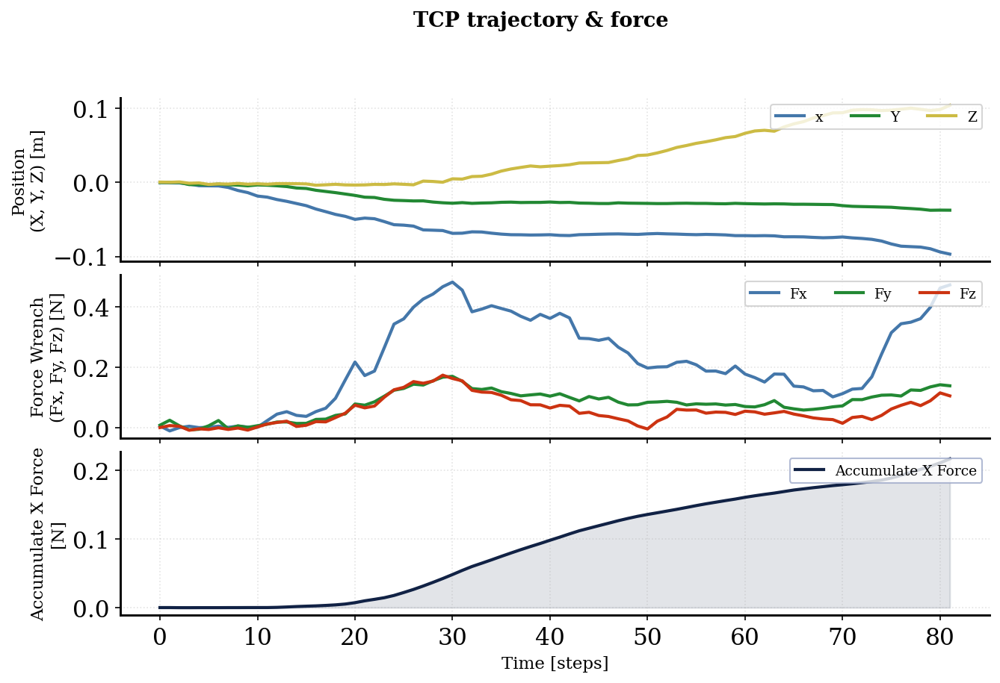

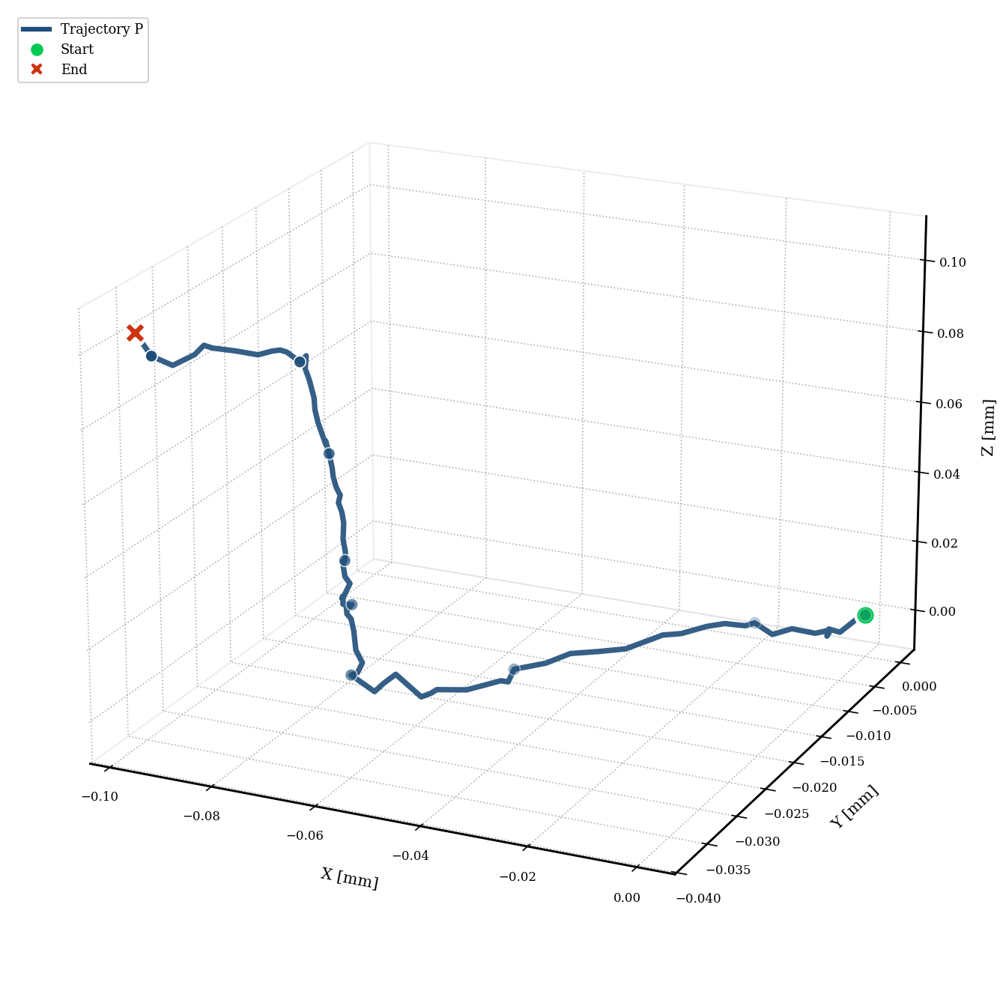

In [29]:
"""
Trajectory + Force Visualiser  — matches reference figure layout
================================================================
LEFT PANEL  (3 stacked subplots, shared x / time axis):
  A  Position  X, Y, Z  [m or mm]
  B  Force Wrench  Fx, Fy, Fz  [N]
  C  Net Force Magnitude |F|  [N]

RIGHT PANEL  (3-D trajectory):
  • Thick trajectory line
  • Quiver arrows at every Nth waypoint showing normalised force direction,
    scaled by magnitude
  • Numbered waypoint markers

Edit the CONFIGURATION section below to match your CSV columns.
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.mplot3d import Axes3D          # noqa: F401
import warnings

warnings.filterwarnings("ignore")

# ═══════════════════════════════════════════════════════════════════════════
# CONFIGURATION  ← edit here
# ═══════════════════════════════════════════════════════════════════════════
FILE_PATH = "./demos/memories/snap_2.4.csv"
LABEL     = "Checkpoint 4.21"

# Position columns  (observations that give X, Y, Z of the end-effector)
COL_X = "observations.0"
COL_Y = "observations.1"
COL_Z = "observations.2"

# Force columns  ← adjust to your actual CSV columns
# Common options:
#   observations.3 / .4 / .5  — forces packed in observation vector
#   force_x / force_y / force_z  — dedicated columns
COL_FX = "observations.6"
COL_FY = "observations.7"
COL_FZ = "observations.8"

# Accumulated force column (Panel C)
COL_ACC = "observations.12"
ACC_LABEL = "Accumulate X Force"

# Which episode index to plot (0-based after splitting)
EPISODE_IDX = 100          # change to the episode you want

# Quiver: draw a force arrow every N waypoints
QUIVER_EVERY = 5

# Quiver arrow scale (visual length = normalised_dir × scale_mm)
QUIVER_SCALE = 8.0

# Waypoint number labels: draw every Nth marker label (keeps plot readable)
LABEL_EVERY = 10

# ═══════════════════════════════════════════════════════════════════════════
# Colours
# ═══════════════════════════════════════════════════════════════════════════
C_X          = "#4477AA"
C_Y          = "#228833"
C_Z          = "#CCBB44"
C_FX         = "#4477AA"
C_FY         = "#228833"
C_FZ         = "#CC3311"
C_NET        = "#112245"
C_TRAJ       = "#1F4E79"
C_QUIVER     = "#E07B39"
C_CONTACT    = "#CC3311"
C_WAYPOINT   = "#1F4E79"

# ═══════════════════════════════════════════════════════════════════════════
# Style
# ═══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    "font.family"  : "serif",
    "font.serif"   : ["Palatino Linotype", "Palatino", "Georgia",
                      "Times New Roman", "DejaVu Serif"],
    "axes.linewidth"    : 1.4,
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
    "figure.dpi"        : 150,
    "savefig.dpi"       : 300,
    "savefig.bbox"      : "tight",
    "grid.alpha"        : 0.35,
    "grid.linestyle"    : ":",
})

# ═══════════════════════════════════════════════════════════════════════════
# Helpers
# ═══════════════════════════════════════════════════════════════════════════
def load_and_split(path: str) -> list[pd.DataFrame]:
    df = pd.read_csv(path)
    for col in ("truncated.0", "terminated.0", "useRL.0"):
        df[col] = df[col].astype(int)
    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [g.reset_index(drop=True) for _, g in df.groupby(ep_ids)]


def check_cols(df: pd.DataFrame, cols: list[str]) -> bool:
    missing = [c for c in cols if c not in df.columns]
    if missing:
        print(f"\n⚠  Missing columns: {missing}")
        print(f"   Available: {list(df.columns)}\n")
    return len(missing) == 0


def contact_steps(df: pd.DataFrame) -> list[int]:
    """Return step indices where contact starts (net force rises above threshold)."""
    if COL_FX not in df.columns:
        return []
    fx = df[COL_FX].values.astype(float)
    fy = df[COL_FY].values.astype(float)
    fz = df[COL_FZ].values.astype(float)
    net = np.sqrt(fx**2 + fy**2 + fz**2)
    thresh = 0.15 * net.max()
    in_contact = False
    events = []
    for i, v in enumerate(net):
        if v > thresh and not in_contact:
            events.append(i)
            in_contact = True
        elif v <= thresh:
            in_contact = False
    return events


# ═══════════════════════════════════════════════════════════════════════════
# Load data
# ═══════════════════════════════════════════════════════════════════════════
episodes = load_and_split(FILE_PATH)
n = len(episodes)
idx = min(EPISODE_IDX, n - 2)
ep   = episodes[idx]

print(f"Dataset : {LABEL}")
print(f"Episode : {idx}  ({len(ep)} steps)")

force_cols = [COL_FX, COL_FY, COL_FZ]
pos_cols   = [COL_X, COL_Y, COL_Z]
has_forces = check_cols(ep, force_cols)
has_pos    = check_cols(ep, pos_cols)

steps = np.arange(len(ep))

x  = ep[COL_X].values.astype(float) if has_pos else steps * 0
y  = ep[COL_Y].values.astype(float) if has_pos else steps * 0
z  = ep[COL_Z].values.astype(float) if has_pos else steps * 0

if has_forces:
    fx  = ep[COL_FX].values.astype(float)
    fy  = ep[COL_FY].values.astype(float)
    fz  = ep[COL_FZ].values.astype(float)
    net = np.sqrt(fx**2 + fy**2 + fz**2)
else:
    fx = fy = fz = net = np.zeros(len(ep))

has_acc = COL_ACC in ep.columns
if has_acc:
    acc = ep[COL_ACC].values.astype(float)
else:
    print(f"\n⚠  Column '{COL_ACC}' not found — Panel C will show net force instead.")
    acc = net

contacts = contact_steps(ep)

# ═══════════════════════════════════════════════════════════════════════════
# Figure 1 — Time-series subplots (position + force + accumulated force)
# ═══════════════════════════════════════════════════════════════════════════
fig_ts = plt.figure(figsize=(10, 6), facecolor="white")
gs = gridspec.GridSpec(3, 1, figure=fig_ts, hspace=0.08)

ax_pos = fig_ts.add_subplot(gs[0])
ax_f   = fig_ts.add_subplot(gs[1], sharex=ax_pos)
ax_net = fig_ts.add_subplot(gs[2], sharex=ax_pos)

# ═══════════════════════════════════════════════════════════════════════════
# Figure 2 — 3-D Trajectory + Force Quiver
# ═══════════════════════════════════════════════════════════════════════════
fig_3d = plt.figure(figsize=(10, 9), facecolor="white")
ax_3d  = fig_3d.add_subplot(111, projection="3d")

# # ── Shared contact event lines ─────────────────────────────────────────────
# for ax in (ax_pos, ax_f, ax_net):
#     for c in contacts:
#         ax.axvline(c, color=C_CONTACT, linewidth=1.2,
#                    linestyle="--", label="Contact Event" if ax is ax_pos else "")

# ═══════════════════════════════════════════════════════════════════════════
# Panel A — Position
# ═══════════════════════════════════════════════════════════════════════════
ax_pos.plot(steps, x, color=C_X, linewidth=2, label="x")
ax_pos.plot(steps, y, color=C_Y, linewidth=2, label="Y")
ax_pos.plot(steps, z, color=C_Z, linewidth=2, label="Z")

ax_pos.set_ylabel("Position\n(X, Y, Z) [m]", fontsize=11)
ax_pos.legend(loc="upper right", fontsize=9, ncol=4,
              framealpha=0.8, edgecolor="#CCCCCC")
ax_pos.grid(True)
ax_pos.text(-0.10, 1.04, " ", transform=ax_pos.transAxes,
            fontsize=14, fontweight="bold")
plt.setp(ax_pos.get_xticklabels(), visible=False)

# ═══════════════════════════════════════════════════════════════════════════
# Panel B — Force Wrench
# ═══════════════════════════════════════════════════════════════════════════
ax_f.plot(steps, fx, color=C_FX, linewidth=2, label="Fx")
ax_f.plot(steps, fy, color=C_FY, linewidth=2, label="Fy")
ax_f.plot(steps, fz, color=C_FZ, linewidth=2, label="Fz")
# ax_f.axhline(0, color="#AAAAAA", linewidth=0.8, linestyle="-")

ax_f.set_ylabel("Force Wrench\n(Fx, Fy, Fz) [N]", fontsize=11)
ax_f.legend(loc="upper right", fontsize=9, ncol=3,
            framealpha=0.8, edgecolor="#CCCCCC")
ax_f.grid(True)
ax_f.text(-0.10, 1.04, " ", transform=ax_f.transAxes,
          fontsize=14, fontweight="bold")
plt.setp(ax_f.get_xticklabels(), visible=False)

# ═══════════════════════════════════════════════════════════════════════════
# Panel C — Accumulate X Force
# ═══════════════════════════════════════════════════════════════════════════
ax_net.plot(steps, acc, color=C_NET, linewidth=2, label=ACC_LABEL)
ax_net.fill_between(steps, acc, 0, color=C_NET, alpha=0.12)

ax_net.set_xlabel("Time [steps]", fontsize=11)
ax_net.set_ylabel(f"{ACC_LABEL}\n[N]", fontsize=11)
ax_net.legend(loc="upper right", fontsize=9, framealpha=0.8, edgecolor="#9FAACA")
ax_net.grid(True)
ax_net.text(-0.10, 1.04, " ", transform=ax_net.transAxes,
            fontsize=14, fontweight="bold")


# ═══════════════════════════════════════════════════════════════════════════
# Right panel — 3-D Trajectory + Force Quiver
# ═══════════════════════════════════════════════════════════════════════════
for pane in [ax_3d.xaxis.pane, ax_3d.yaxis.pane, ax_3d.zaxis.pane]:
    pane.fill = False
    pane.set_edgecolor("#DDDDDD")
ax_3d.set_facecolor("white")
ax_3d.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)

# Trajectory line
ax_3d.plot(x, y, z, color=C_TRAJ, linewidth=3.5, alpha=0.9,
           solid_capstyle="round", label="Trajectory P", zorder=2)

# Numbered waypoint markers every LABEL_EVERY steps
marker_steps = np.arange(0, len(steps), LABEL_EVERY)
ax_3d.scatter(x[marker_steps], y[marker_steps], z[marker_steps],
              c=C_WAYPOINT, s=60, zorder=5, edgecolors="white", linewidths=0.8)
for ms in marker_steps:
    ax_3d.text(x[ms], y[ms], z[ms] + 0.5,
               str(ms), fontsize=7, ha="center", color=C_WAYPOINT, zorder=6)

# Start / End markers
ax_3d.scatter([x[0]],  [y[0]],  [z[0]],  marker="o", s=160,
              c="#00C853", edgecolors="white", linewidths=2, zorder=10)
ax_3d.scatter([x[-1]], [y[-1]], [z[-1]], marker="X", s=200,
              c=C_CONTACT, edgecolors="white", linewidths=2, zorder=10)

# Axes labels and view
ax_3d.set_xlabel("X [mm]", fontsize=10, labelpad=8)
ax_3d.set_ylabel("Y [mm]", fontsize=10, labelpad=10)
ax_3d.set_zlabel("Z [mm]", fontsize=10, labelpad=8)
ax_3d.tick_params(labelsize=8)
ax_3d.view_init(elev=20, azim=-65)

# Legend
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrow
traj_line   = Line2D([0],[0], color=C_TRAJ,   linewidth=3, label="Trajectory P")
start_dot   = Line2D([0],[0], marker="o", color="w", markerfacecolor="#00C853",
                     markersize=9, label="Start")
end_dot     = Line2D([0],[0], marker="X", color="w", markerfacecolor=C_CONTACT,
                     markersize=9, label="End")
ax_3d.legend(handles=[traj_line, start_dot, end_dot],
             loc="upper left", fontsize=8.5, framealpha=0.85,
             edgecolor="#CCCCCC", handlelength=2.0)

# ── Figure title ───────────────────────────────────────────────────────────
fig_ts.suptitle(
    f"TCP trajectory & force",
    fontsize=13, fontweight="bold", y=1.01
)

# Add bullet-point annotation box (top-right, matching reference style)
annot = (
    "• Robotic end-effector\n"
    "  3D path: plotted 3D\n"
    "  peg-in-hole.\n"
    "→ Trajectory P\n"
    "→ Force Quiver\n"
    "• At every 5th waypoint,\n"
    "  a single vector arrow\n"
    "  (Fx, Fy, Fz) in the\n"
    "  normalised net force\n"
    "  direction and total\n"
    "  magnitude (length)"
)
# ax_3d.text2D(
#     1.02, 0.98, annot,
#     transform=ax_3d.transAxes,
#     fontsize=7.5, va="top", ha="left",
#     color="#333333",
#     bbox=dict(boxstyle="round,pad=0.5", fc="white",
#               ec="#CCCCCC", lw=1, alpha=0.92),
# )

# ═══════════════════════════════════════════════════════════════════════════
# Save
# ═══════════════════════════════════════════════════════════════════════════
SAVE_DIR = "demos/"
fig_ts.savefig(f"{SAVE_DIR}timeseries.png", transparent=False, bbox_inches="tight")
fig_ts.savefig(f"{SAVE_DIR}timeseries.pdf", transparent=False, bbox_inches="tight")
fig_3d.savefig(f"{SAVE_DIR}trajectory_3d.png", transparent=False, bbox_inches="tight")
fig_3d.savefig(f"{SAVE_DIR}trajectory_3d.pdf", transparent=False, bbox_inches="tight")
print(f"\nSaved:\n  {SAVE_DIR}timeseries.png\n  {SAVE_DIR}trajectory_3d.png")

fig_ts.tight_layout()
fig_3d.tight_layout()
plt.show()

Dataset 1: SnapOpen | Episode: 50 (100 steps)
Dataset 2: OpenBox | Episode: 113 (93 steps)

Saved plots to:
  demos/trajectory_comparison_3d.png


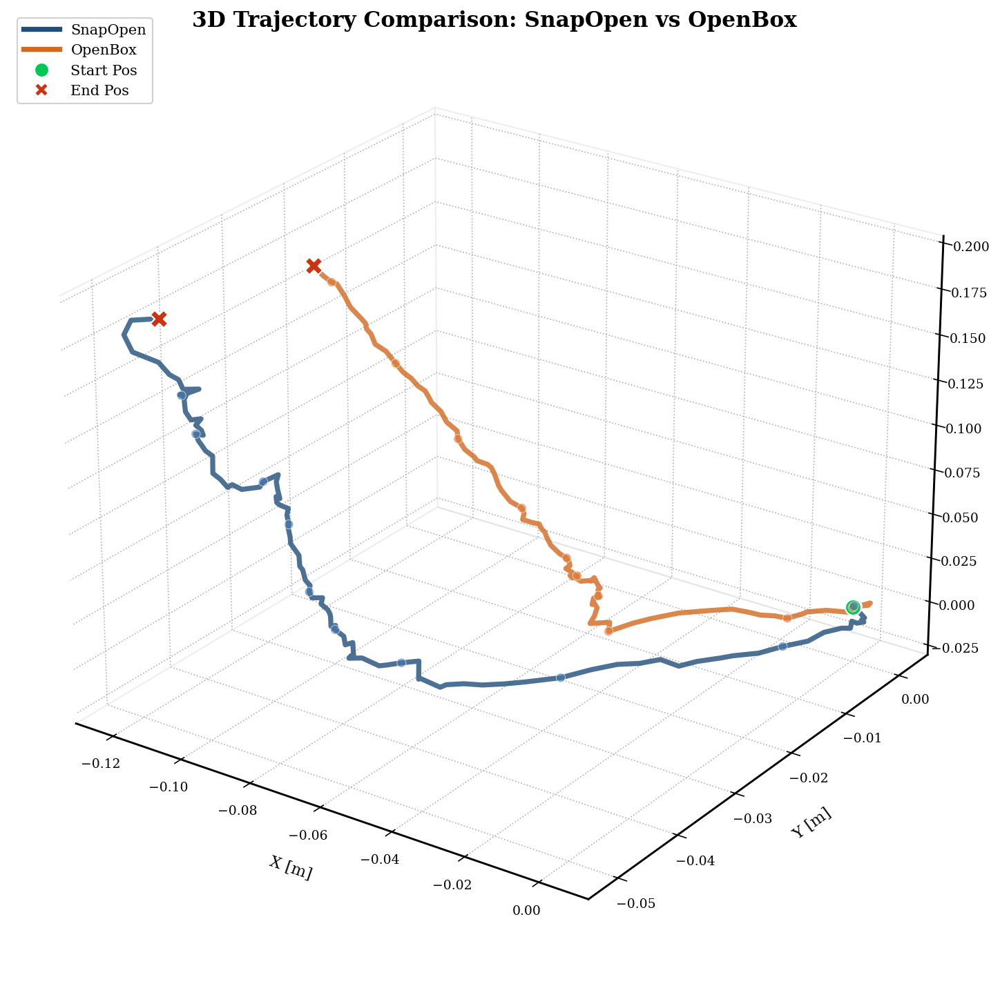

In [52]:
"""
3D Trajectory Comparison Visualiser
================================================================
Compares the 3D spatial trajectories of two different datasets 
(SnapOpen vs OpenBox) in a single shared 3D plot.
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
import warnings

warnings.filterwarnings("ignore")

# ═══════════════════════════════════════════════════════════════════════════
# CONFIGURATION 
# ═══════════════════════════════════════════════════════════════════════════
FILE_PATH1 = "./demos/memories/snapopen_OSRL.csv"
LABEL1     = "SnapOpen"

FILE_PATH2 = "./demos/memories/2.71.csv"
LABEL2     = "OpenBox"

# Position columns
COL_X = "observations.0"
COL_Y = "observations.1"
COL_Z = "observations.2"

# Which episode index to plot (0-based after splitting)
EPISODE_IDX = 150

# Waypoint number labels: draw every Nth marker label
LABEL_EVERY = 10

# ═══════════════════════════════════════════════════════════════════════════
# Colours
# ═══════════════════════════════════════════════════════════════════════════
# Trajectory 1 Colours (Blue theme)
C_TRAJ1       = "#1F4E79"
C_WAYPOINT1   = "#4477AA"

# Trajectory 2 Colours (Orange theme)
C_TRAJ2       = "#D2691E"
C_WAYPOINT2   = "#E07B39"

# Shared Colours
C_START       = "#00C853"
C_END         = "#CC3311"

# ═══════════════════════════════════════════════════════════════════════════
# Style
# ═══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    "font.family"  : "serif",
    "font.serif"   : ["Palatino Linotype", "Palatino", "Georgia",
                      "Times New Roman", "DejaVu Serif"],
    "axes.linewidth"    : 1.4,
    "figure.dpi"        : 150,
    "savefig.dpi"       : 300,
    "savefig.bbox"      : "tight",
})

# ═══════════════════════════════════════════════════════════════════════════
# Helpers
# ═══════════════════════════════════════════════════════════════════════════
def load_and_split(path: str) -> list[pd.DataFrame]:
    df = pd.read_csv(path)
    for col in ("truncated.0", "terminated.0", "useRL.0"):
        if col in df.columns:
            df[col] = df[col].astype(int)
    
    # Safely handle missing episode split columns by falling back to single trajectory
    if "truncated.0" in df.columns and "terminated.0" in df.columns:
        ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
        ep_ids = ep_end.shift(1, fill_value=0).cumsum()
        return [g.reset_index(drop=True) for _, g in df.groupby(ep_ids)]
    return [df]

def extract_trajectory(ep: pd.DataFrame):
    steps = np.arange(len(ep))
    if set([COL_X, COL_Y, COL_Z]).issubset(ep.columns):
        x = ep[COL_X].values.astype(float)
        y = ep[COL_Y].values.astype(float)
        z = ep[COL_Z].values.astype(float)
    else:
        x = y = z = steps * 0
    return steps, x, y, z

# ═══════════════════════════════════════════════════════════════════════════
# Load data
# ═══════════════════════════════════════════════════════════════════════════
# Load File 1
episodes1 = load_and_split(FILE_PATH1)
idx1 = min(50, len(episodes1) - 1) if len(episodes1) > 1 else 0
ep1 = episodes1[idx1]
steps1, x1, y1, z1 = extract_trajectory(ep1)

# Load File 2
episodes2 = load_and_split(FILE_PATH2)
idx2 = min(EPISODE_IDX, len(episodes2) - 1) if len(episodes2) > 1 else 0
ep2 = episodes2[idx2]
steps2, x2, y2, z2 = extract_trajectory(ep2)

print(f"Dataset 1: {LABEL1} | Episode: {idx1} ({len(ep1)} steps)")
print(f"Dataset 2: {LABEL2} | Episode: {idx2} ({len(ep2)} steps)")

# ═══════════════════════════════════════════════════════════════════════════
# Plotting - 3D Trajectory Comparison
# ═══════════════════════════════════════════════════════════════════════════
fig_3d = plt.figure(figsize=(12, 10), facecolor="white")
ax_3d  = fig_3d.add_subplot(111, projection="3d")

# Clean backgrounds
for pane in [ax_3d.xaxis.pane, ax_3d.yaxis.pane, ax_3d.zaxis.pane]:
    pane.fill = False
    pane.set_edgecolor("#DDDDDD")
ax_3d.set_facecolor("white")
ax_3d.grid(True, linestyle=":", linewidth=0.8, alpha=0.5)

# --- Plot Trajectory 1 ---
ax_3d.plot(x1, y1, z1, color=C_TRAJ1, linewidth=3.5, alpha=0.8,
           solid_capstyle="round", label=f"Traj: {LABEL1}", zorder=2)
# Start / End markers Traj 1
ax_3d.scatter([x1[0]],  [y1[0]],  [z1[0]],  marker="o", s=120, c=C_START, edgecolors="white", zorder=10)
ax_3d.scatter([x1[-1]], [y1[-1]], [z1[-1]], marker="X", s=150, c=C_END, edgecolors="white", zorder=10)

# --- Plot Trajectory 2 ---
ax_3d.plot(x2, y2, z2, color=C_TRAJ2, linewidth=3.5, alpha=0.8,
           solid_capstyle="round", label=f"Traj: {LABEL2}", zorder=2)
# Start / End markers Traj 2
ax_3d.scatter([x2[0]],  [y2[0]],  [z2[0]],  marker="o", s=120, c=C_START, edgecolors="white", zorder=10)
ax_3d.scatter([x2[-1]], [y2[-1]], [z2[-1]], marker="X", s=150, c=C_END, edgecolors="white", zorder=10)

# Optional: Numbered waypoint markers (applied to both to show progression)
marker_steps1 = np.arange(0, len(steps1), LABEL_EVERY)
ax_3d.scatter(x1[marker_steps1], y1[marker_steps1], z1[marker_steps1],
              c=C_WAYPOINT1, s=40, zorder=5, edgecolors="white", linewidths=0.5, alpha=0.6)

marker_steps2 = np.arange(0, len(steps2), LABEL_EVERY)
ax_3d.scatter(x2[marker_steps2], y2[marker_steps2], z2[marker_steps2],
              c=C_WAYPOINT2, s=40, zorder=5, edgecolors="white", linewidths=0.5, alpha=0.6)

# Axes labels and view
ax_3d.set_xlabel("X [m]", fontsize=11, labelpad=10)
ax_3d.set_ylabel("Y [m]", fontsize=11, labelpad=10)
ax_3d.set_zlabel("Z [m]", fontsize=11, labelpad=10)
ax_3d.tick_params(labelsize=9)
ax_3d.view_init(elev=25, azim=-55)

# Custom Legend Construct
traj1_line = Line2D([0],[0], color=C_TRAJ1, linewidth=3.5, label=LABEL1)
traj2_line = Line2D([0],[0], color=C_TRAJ2, linewidth=3.5, label=LABEL2)
start_dot  = Line2D([0],[0], marker="o", color="w", markerfacecolor=C_START, markersize=10, label="Start Pos")
end_dot    = Line2D([0],[0], marker="X", color="w", markerfacecolor=C_END, markersize=10, label="End Pos")

ax_3d.legend(handles=[traj1_line, traj2_line, start_dot, end_dot],
             loc="upper left", fontsize=10, framealpha=0.9,
             edgecolor="#CCCCCC", handlelength=2.5)

# ── Figure title ───────────────────────────────────────────────────────────
fig_3d.suptitle(
    f"3D Trajectory Comparison: {LABEL1} vs {LABEL2}",
    fontsize=15, fontweight="bold", y=0.95
)

# ═══════════════════════════════════════════════════════════════════════════
# Save & Show
# ═══════════════════════════════════════════════════════════════════════════
SAVE_DIR = "demos/"
import os
os.makedirs(SAVE_DIR, exist_ok=True)

fig_3d.savefig(f"{SAVE_DIR}trajectory_comparison_3d.png", transparent=False, bbox_inches="tight")
fig_3d.savefig(f"{SAVE_DIR}trajectory_comparison_3d.pdf", transparent=False, bbox_inches="tight")
print(f"\nSaved plots to:\n  {SAVE_DIR}trajectory_comparison_3d.png")

plt.tight_layout()
plt.show()

Dataset 1: Replay | Episode: 0 (100 steps)
Dataset 2: Reinforced | Episode: 50 (100 steps)

Saved plots to:
  demos/wrench_comparison_2x3.png


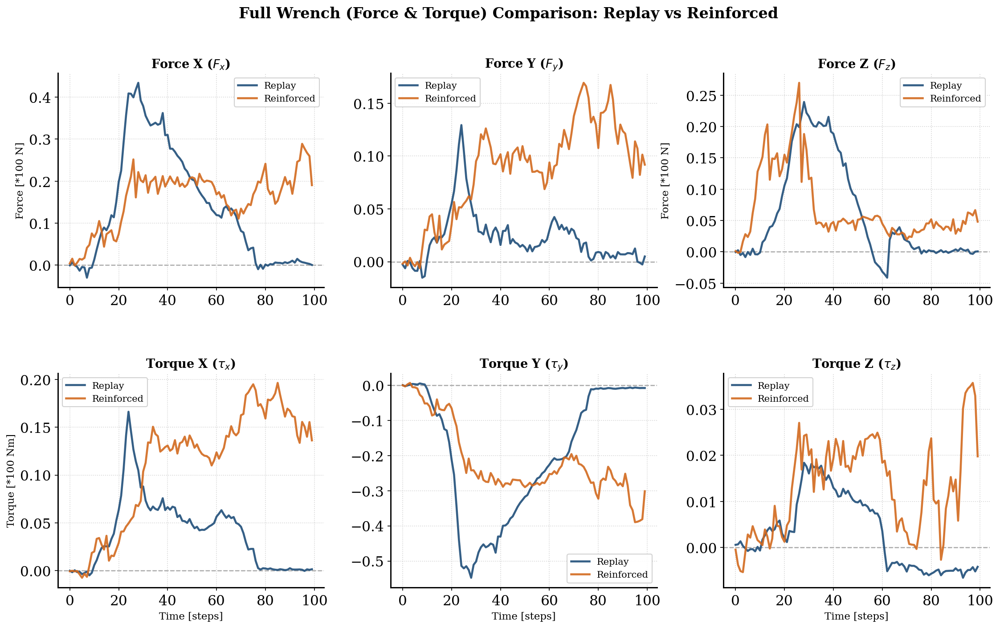

In [ ]:
"""
Force & Torque Wrench Comparison Visualiser
================================================================
Compares the full 6D wrench (Fx, Fy, Fz, Tx, Ty, Tz) of two 
different datasets (SnapOpen vs OpenBox) in a 2x3 subplot layout.
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings("ignore")

# ═══════════════════════════════════════════════════════════════════════════
# CONFIGURATION 
# ═══════════════════════════════════════════════════════════════════════════
FILE_PATH1 = "./demos/memories/replay_.csv"
LABEL1     = "Replay_SnapOpen"

FILE_PATH2 = "./demos/memories/snapopen_OSRL.csv"
LABEL2     = "OSRL_SnapOpen"

FILE_PATH3 = "./demos/memories/nn2.40_openbox.csv"
LABEL3     = "OSRL_OpenBox"

# Force columns
COL_FX = "observations.6"
COL_FY = "observations.7"
COL_FZ = "observations.8"

# Torque columns
COL_TX = "observations.9"
COL_TY = "observations.10"
COL_TZ = "observations.11"

# Which episode index to plot (0-based after splitting)
EPISODE_IDX = 150

# Colours
C_LINE1 = "#1F4E79"  # Blue theme for File 1
C_LINE2 = "#D2691E"  # Orange theme for File 2
C_LINE3 = "#2E8B57"  # Green theme for File 3

# ═══════════════════════════════════════════════════════════════════════════
# Style
# ═══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    "font.family"  : "serif",
    "font.serif"   : ["Palatino Linotype", "Palatino", "Georgia", "DejaVu Serif"],
    "axes.linewidth"    : 1.4,
    "axes.spines.top"   : False,
    "axes.spines.right" : False,
    "figure.dpi"        : 150,
    "savefig.bbox"      : "tight",
})

# ═══════════════════════════════════════════════════════════════════════════
# Helpers
# ═══════════════════════════════════════════════════════════════════════════
def load_and_split(path: str) -> list[pd.DataFrame]:
    df = pd.read_csv(path)
    for col in ("truncated.0", "terminated.0", "useRL.0"):
        if col in df.columns:
            df[col] = df[col].astype(int)
            
    if "truncated.0" in df.columns and "terminated.0" in df.columns:
        ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
        ep_ids = ep_end.shift(1, fill_value=0).cumsum()
        return [g.reset_index(drop=True) for _, g in df.groupby(ep_ids)]
    return [df]

def extract_wrench(ep: pd.DataFrame):
    """Extracts both forces and torques from the episode dataframe."""
    steps = np.arange(len(ep))
    
    # Extract Forces
    if set([COL_FX, COL_FY, COL_FZ]).issubset(ep.columns):
        fx = ep[COL_FX].values.astype(float)
        fy = ep[COL_FY].values.astype(float)
        fz = ep[COL_FZ].values.astype(float)
    else:
        print("⚠ Warning: Force columns not found. Filling with zeros.")
        fx = fy = fz = steps * 0
        
    # Extract Torques
    if set([COL_TX, COL_TY, COL_TZ]).issubset(ep.columns):
        tx = ep[COL_TX].values.astype(float)
        ty = ep[COL_TY].values.astype(float)
        tz = ep[COL_TZ].values.astype(float)
    else:
        print("⚠ Warning: Torque columns not found. Filling with zeros.")
        tx = ty = tz = steps * 0
        
    return steps, fx, fy, fz, tx, ty, tz

# ═══════════════════════════════════════════════════════════════════════════
# Load data
# ═══════════════════════════════════════════════════════════════════════════
# Load File 1
episodes1 = load_and_split(FILE_PATH1)
idx1 = min(0, len(episodes1) - 1) if len(episodes1) > 1 else 0
ep1 = episodes1[idx1]
steps1, fx1, fy1, fz1, tx1, ty1, tz1 = extract_wrench(ep1)

# Load File 2
episodes2 = load_and_split(FILE_PATH2)
idx2 = min(50, len(episodes2) - 1) if len(episodes2) > 1 else 0
ep2 = episodes2[idx2]
steps2, fx2, fy2, fz2, tx2, ty2, tz2 = extract_wrench(ep2)

print(f"Dataset 1: {LABEL1} | Episode: {idx1} ({len(ep1)} steps)")
print(f"Dataset 2: {LABEL2} | Episode: {idx2} ({len(ep2)} steps)")

# ═══════════════════════════════════════════════════════════════════════════
# Plotting - 2x3 Subplot Layout
# ═══════════════════════════════════════════════════════════════════════════
fig, axs = plt.subplots(2, 3, figsize=(18, 10), sharey=False, facecolor="white")
fig.subplots_adjust(wspace=0.25, hspace=0.4)

# ─── ROW 1: FORCES ─────────────────────────────────────────────────────────
# Panel 1: Force X
axs[0, 0].axhline(0, color="#AAAAAA", linewidth=1.2, linestyle="--", zorder=1)
axs[0, 0].plot(steps1, fx1, color=C_LINE1, linewidth=2.2, label=LABEL1, alpha=0.9, zorder=2)
axs[0, 0].plot(steps2, fx2, color=C_LINE2, linewidth=2.2, label=LABEL2, alpha=0.9, zorder=2)
axs[0, 0].set_title(r"Force X ($F_x$)", fontsize=13, fontweight="bold")
axs[0, 0].set_ylabel("Force [*100 N]", fontsize=11)

# Panel 2: Force Y
axs[0, 1].axhline(0, color="#AAAAAA", linewidth=1.2, linestyle="--", zorder=1)
axs[0, 1].plot(steps1, fy1, color=C_LINE1, linewidth=2.2, label=LABEL1, alpha=0.9, zorder=2)
axs[0, 1].plot(steps2, fy2, color=C_LINE2, linewidth=2.2, label=LABEL2, alpha=0.9, zorder=2)
axs[0, 1].set_title(r"Force Y ($F_y$)", fontsize=13, fontweight="bold")

# Panel 3: Force Z
axs[0, 2].axhline(0, color="#AAAAAA", linewidth=1.2, linestyle="--", zorder=1)
axs[0, 2].plot(steps1, fz1, color=C_LINE1, linewidth=2.2, label=LABEL1, alpha=0.9, zorder=2)
axs[0, 2].plot(steps2, fz2, color=C_LINE2, linewidth=2.2, label=LABEL2, alpha=0.9, zorder=2)
axs[0, 2].set_title(r"Force Z ($F_z$)", fontsize=13, fontweight="bold")
axs[0, 2].set_ylabel("Force [*100 N]", fontsize=11)

# ─── ROW 2: TORQUES ────────────────────────────────────────────────────────
# Panel 4: Torque X
axs[1, 0].axhline(0, color="#AAAAAA", linewidth=1.2, linestyle="--", zorder=1)
axs[1, 0].plot(steps1, tx1, color=C_LINE1, linewidth=2.2, label=LABEL1, alpha=0.9, zorder=2)
axs[1, 0].plot(steps2, tx2, color=C_LINE2, linewidth=2.2, label=LABEL2, alpha=0.9, zorder=2)
axs[1, 0].set_title(r"Torque X ($\tau_x$)", fontsize=13, fontweight="bold")
axs[1, 0].set_ylabel("Torque [*100 Nm]", fontsize=11)
axs[1, 0].set_xlabel("Time [steps]", fontsize=11)

# Panel 5: Torque Y
axs[1, 1].axhline(0, color="#AAAAAA", linewidth=1.2, linestyle="--", zorder=1)
axs[1, 1].plot(steps1, ty1, color=C_LINE1, linewidth=2.2, label=LABEL1, alpha=0.9, zorder=2)
axs[1, 1].plot(steps2, ty2, color=C_LINE2, linewidth=2.2, label=LABEL2, alpha=0.9, zorder=2)
axs[1, 1].set_title(r"Torque Y ($\tau_y$)", fontsize=13, fontweight="bold")
axs[1, 1].set_xlabel("Time [steps]", fontsize=11)

# Panel 6: Torque Z
axs[1, 2].axhline(0, color="#AAAAAA", linewidth=1.2, linestyle="--", zorder=1)
axs[1, 2].plot(steps1, tz1, color=C_LINE1, linewidth=2.2, label=LABEL1, alpha=0.9, zorder=2)
axs[1, 2].plot(steps2, tz2, color=C_LINE2, linewidth=2.2, label=LABEL2, alpha=0.9, zorder=2)
axs[1, 2].set_title(r"Torque Z ($\tau_z$)", fontsize=13, fontweight="bold")
axs[1, 2].set_xlabel("Time [steps]", fontsize=11)

# Common styling for all subplots
for ax in axs.flat:
    ax.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)
    ax.legend(loc="best", fontsize=10, framealpha=0.9, edgecolor="#CCCCCC")

# ── Figure title ───────────────────────────────────────────────────────────
fig.suptitle(
    f"Full Wrench (Force & Torque) Comparison: {LABEL1} vs {LABEL2}",
    fontsize=16, fontweight="bold", y=0.98
)

# ═══════════════════════════════════════════════════════════════════════════
# Save & Show
# ═══════════════════════════════════════════════════════════════════════════
SAVE_DIR = "demos/"
os.makedirs(SAVE_DIR, exist_ok=True)

fig.savefig(f"{SAVE_DIR}wrench_comparison_2x3.png", transparent=False, bbox_inches="tight")
fig.savefig(f"{SAVE_DIR}wrench_comparison_2x3.pdf", transparent=False, bbox_inches="tight")
print(f"\nSaved plots to:\n  {SAVE_DIR}wrench_comparison_2x3.png")

plt.show()

In [56]:
"""
2D Trajectory Visualiser (X-Z plane)
====================================
• Loads three CSV files (4.01, 4.11, 4.21)
• Splits each into episodes on truncated.0 | terminated.0
• Plots every 5th episode in 2D (X vs Z)
• Highlights:
    - first trajectory → 'replay'
    - last trajectory  → 'epi_last'
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings("ignore")

# ── Paths ──────────────────────────────────────────────────────────────────
FILES = {
    "Checkpoint 4.01":  "./demos/memories/0.01.csv",
    "Checkpoint 4.11":  "./demos/memories/0.11.csv",
    "Checkpoint 4.21":  "./demos/memories/0.3.csv",
}

# ── Colour palette ─────────────────────────────────────────────────────────
C_RL   = "#D94F3D"
C_BC   = "#3A7EBF"
C_BG   = "#F8F8F6"
C_GRID = "#DEDEDE"
C_PANE = "#F0F0EE"

EP_PALETTE = [
    "#4C72B0", "#DD8452", "#55A868", "#C44E52",
    "#8172B3", "#937860", "#DA8BC3", "#8C8C8C",
    "#CCB974", "#64B5CD",
]

EPISODE_STRIDE = 5

# ── Style ──────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "figure.dpi": 160,
    "savefig.dpi": 300,
    "axes.linewidth": 2,
})

# ── Helpers ────────────────────────────────────────────────────────────────
def load_and_split(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["useRL.0"]      = df["useRL.0"].astype(int)

    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [grp.reset_index(drop=True) for _, grp in df.groupby(ep_ids)]

def select_episodes(episodes, stride=5):
    return [(i, episodes[i]) for i in range(0, len(episodes), stride)]

def trajectory_xz(ep_df):
    return (
        ep_df["observations.0"].values.astype(float),
        ep_df["observations.2"].values.astype(float)
    )

def rl_mask(ep_df):
    return ep_df["useRL.0"].values.astype(bool)

# ── Load data ──────────────────────────────────────────────────────────────
data = {}
for label, path in FILES.items():
    eps = load_and_split(path)
    selected = select_episodes(eps, EPISODE_STRIDE)
    data[label] = selected
    print(f"{label}: {len(eps)} episodes → {len(selected)} plotted")

# ── Axis limits ────────────────────────────────────────────────────────────
all_x, all_z = [], []
for selected in data.values():
    for _, ep_df in selected:
        x, z = trajectory_xz(ep_df)
        all_x.extend(x); all_z.extend(z)

def padded(vals, frac=0.06):
    lo, hi = np.min(vals), np.max(vals)
    pad = (hi - lo) * frac or 0.1
    return lo - pad, hi + pad

xlim = padded(all_x)
zlim = padded(all_z)

# ── Plot ───────────────────────────────────────────────────────────────────
n_panels = len(data)
COLS = 2
ROWS = int(np.ceil(n_panels / COLS))

fig, axes = plt.subplots(ROWS, COLS, figsize=(6.5*COLS, 5.5*ROWS))
axes = axes.flatten()

fig.suptitle(
    "2D Trajectories (X-Z Plane) — RL vs BC",
    fontsize=14, fontweight="bold"
)

for ax, (label, selected) in zip(axes, data.items()):
    ax.set_facecolor(C_PANE)
    ax.grid(True, linestyle=":", linewidth=0.4, alpha=0.7, color=C_GRID)

    n_eps = len(selected)

    for ep_num, (idx, ep_df) in enumerate(selected):
        x, z = trajectory_xz(ep_df)
        rl = rl_mask(ep_df)

        is_first = (ep_num == 0)
        is_last  = (ep_num == n_eps - 1)

        if is_first:
            color = "#000000"
            lw = 3.5   # ↑ thicker
            alpha = 0.95
            label_line = "replay"
            zorder = 4
        elif is_last:
            color = "#E69F00"
            lw = 3.5   # ↑ thicker
            alpha = 0.95
            label_line = "epi_last"
            zorder = 4
        else:
            color = EP_PALETTE[ep_num % len(EP_PALETTE)]
            lw = 1.4   # ↑ thicker than before
            alpha = max(0.25, 0.6 - ep_num*0.03)
            label_line = None
            zorder = 1

        # line (↑ thicker)
        ax.plot(x, z, color=color, linewidth=lw, alpha=alpha,
                zorder=zorder, label=label_line if label_line else None)

        # points (↑ larger dots)
        ax.scatter(x[~rl], z[~rl], c=C_BC, s=20,
                   alpha=0.8 if not (is_first or is_last) else 0.95,
                   edgecolors="none", zorder=2)

        ax.scatter(x[rl], z[rl], c=C_RL, s=24,
                   alpha=0.85 if not (is_first or is_last) else 1.0,
                   edgecolors="none", zorder=3)

        # start/end markers (↑ slightly larger)
        ax.scatter(x[0], z[0], marker="^", s=90 if (is_first or is_last) else 65,
                   c=color, edgecolors="k", linewidths=1, zorder=5)

        ax.scatter(x[-1], z[-1], marker="s", s=75 if (is_first or is_last) else 55,
                   c=color, edgecolors="k", linewidths=1, zorder=5)

    ax.set_xlim(xlim)
    ax.set_ylim(zlim)
    ax.set_xlabel("X")
    ax.set_ylabel("Z")

axes[0].set_title('AQL', fontsize=10, fontweight="bold")
axes[1].set_title('CQL', fontsize=10, fontweight="bold")
axes[2].set_title('IQL', fontsize=10, fontweight="bold")

# hide unused axes
for i in range(len(data), len(axes)):
    axes[i].axis("off")

# ── Legend ─────────────────────────────────────────────────────────────────
legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=C_RL,
           markersize=10, label="RL step"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=C_BC,
           markersize=10, label="BC step"),
    Line2D([0], [0], color="#000000", linewidth=5, label="replay (first)"),
    Line2D([0], [0], color="#E69F00", linewidth=5, label="epi_last"),
]

fig.legend(handles=legend_elements, loc="lower center",
           ncol=4, frameon=False)

fig.patch.set_alpha(0)
for ax in axes:
    ax.set_facecolor("none")

plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    "demos/memories/trajectories_2d.png",
    transparent=True,
    bbox_inches="tight"
)

plt.savefig(
    "demos/memories/trajectories_2d.pdf",
    transparent=True,
    bbox_inches="tight"
)

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: './demos/memories/0.01.csv'

Bellman | ./demos/memories/4.01.csv → 53 episodes
Bellman | ./demos/memories/4.02.csv → 63 episodes
Bellman | ./demos/memories/4.03.csv → 55 episodes
CQL | ./demos/memories/4.11.csv → 51 episodes
CQL | ./demos/memories/4.12.csv → 53 episodes
CQL | ./demos/memories/4.13.csv → 52 episodes
IQL | ./demos/memories/4.21.csv → 53 episodes
IQL | ./demos/memories/4.22.csv → 52 episodes
IQL | ./demos/memories/4.23.csv → 52 episodes

Saved → mc_returns_mean.png / .pdf


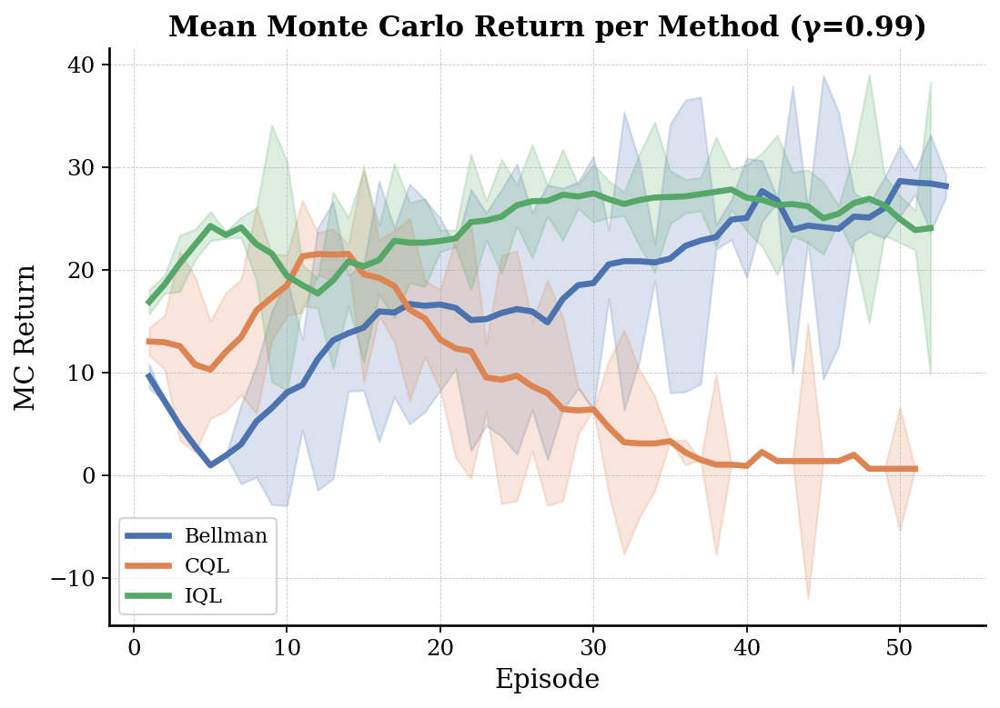

In [7]:
"""
Monte Carlo Return Analysis (Mean Across Runs)
=============================================
• Loads 3 runs per method (Bellman, CQL, IQL)
• Computes MC return per episode
• Averages across runs
• Plots mean ± std MC return curves per method
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
import warnings
warnings.filterwarnings("ignore")

# ── Paths (FIXED) ──────────────────────────────────────────────────────────
FILES = {
    "Bellman": [
        "./demos/memories/4.01.csv",
        "./demos/memories/4.02.csv",
        "./demos/memories/4.03.csv",
    ],
    "CQL": [
        "./demos/memories/4.11.csv",
        "./demos/memories/4.12.csv",
        "./demos/memories/4.13.csv",
    ],
    "IQL": [
        "./demos/memories/4.21.csv",
        "./demos/memories/4.22.csv",
        "./demos/memories/4.23.csv",
    ],
}

GAMMA = 0.99

# ── Colours ────────────────────────────────────────────────────────────────
COLORS = {
    "Bellman": "#4C72B0",
    "CQL": "#DD8452",
    "IQL": "#55A868",
}

# ── Style ──────────────────────────────────────────────────────────────────
plt.rcParams.update({
    "font.family": "serif",
    "axes.labelsize": 13,
    "axes.titlesize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.dpi": 160,
})

# ── Helpers ────────────────────────────────────────────────────────────────
def load_and_split(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["rewards.0"]    = df["rewards.0"].astype(float)

    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()

    return [grp.reset_index(drop=True) for _, grp in df.groupby(ep_ids)]

def mc_return(ep, gamma=0.99):
    r = ep["rewards.0"].values
    return float(np.sum((gamma ** np.arange(len(r))) * r))

def smooth(x, w=5):
    if len(x) < w:
        return x
    return uniform_filter1d(x, size=w, mode="nearest")

# ── Compute returns per run ─────────────────────────────────────────────────
method_returns = {}

for method, paths in FILES.items():
    runs = []

    for p in paths:
        episodes = load_and_split(p)
        returns = np.array([mc_return(ep, GAMMA) for ep in episodes])
        runs.append(returns)

        print(f"{method} | {p} → {len(returns)} episodes")

    # align lengths (truncate to shortest run)
    min_len = min(len(r) for r in runs)
    runs = np.array([r[:min_len] for r in runs])

    method_returns[method] = runs

# ── Compute mean + std ─────────────────────────────────────────────────────
mean_curves = {}
std_curves  = {}

for method, runs in method_returns.items():
    mean_curves[method] = runs.mean(axis=0)
    std_curves[method]  = runs.std(axis=0)

# ── Plot mean curves ───────────────────────────────────────────────────────
plt.figure(figsize=(7, 5))

for method in FILES.keys():
    mean = mean_curves[method]
    std  = std_curves[method]
    x    = np.arange(1, len(mean) + 1)

    color = COLORS[method]

    # smooth mean
    mean_s = smooth(mean, w=7)

    # std band
    plt.fill_between(x,
                     mean_s - std,
                     mean_s + std,
                     color=color, alpha=0.2)

    # mean line
    plt.plot(x, mean_s,
             color=color,
             linewidth=3,
             label=method)

# ── Styling ────────────────────────────────────────────────────────────────
plt.title(f"Mean Monte Carlo Return per Method (γ={GAMMA})",
          fontsize=14, fontweight="bold")

plt.xlabel("Episode")
plt.ylabel("MC Return")

plt.grid(True, linestyle="--", linewidth=0.4, alpha=0.7)
plt.legend()
plt.tight_layout()

plt.savefig("demos/memories/mc_returns_mean.png")
plt.savefig("demos/memories/mc_returns_mean.pdf")

print("\nSaved → mc_returns_mean.png / .pdf")

plt.show()

  Bellman: 50 episodes  |  overall bias = -13.723
  CQL: 50 episodes  |  overall bias = -13.208
  IQL: 50 episodes  |  overall bias = +0.981

Saved → demos/memories/q_bias.png / .pdf


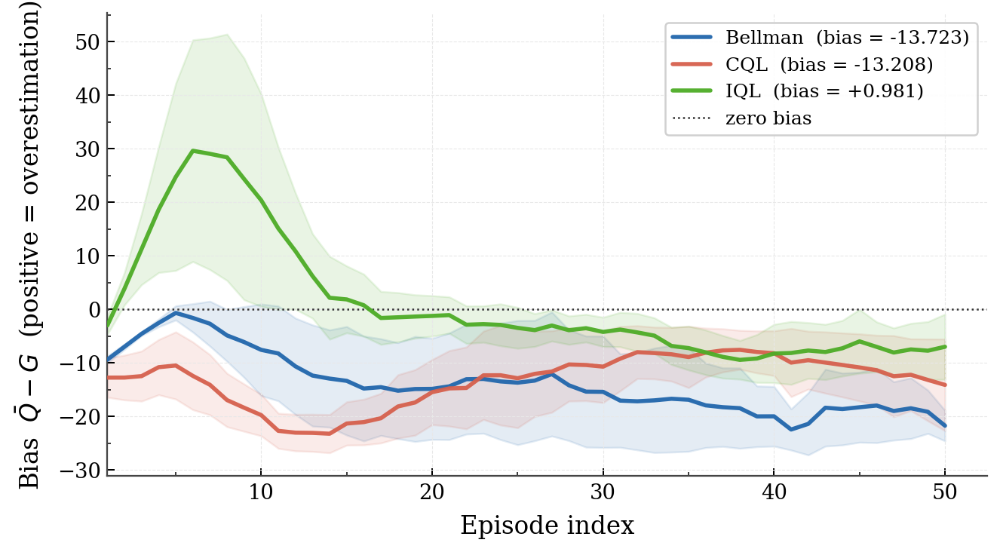

In [17]:
"""
Q-Estimation Bias  =  Q̄ − MC return  (episode-wise)
"""

import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
from matplotlib.ticker import AutoMinorLocator
from scipy.ndimage import uniform_filter1d

# ══════════════════════════════════════════════════════════════════════════
# CONFIG
# ══════════════════════════════════════════════════════════════════════════
GAMMA = 0.99
Q_COL = None

MC_FILES = {
    "Bellman": ["./demos/memories/4.01.csv", "./demos/memories/4.02.csv", "./demos/memories/4.03.csv"],
    "CQL":     ["./demos/memories/4.11.csv", "./demos/memories/4.12.csv", "./demos/memories/4.13.csv"],
    "IQL":     ["./demos/memories/4.21.csv", "./demos/memories/4.22.csv", "./demos/memories/4.23.csv"],
}
Q_FILES = {
    "Bellman": ["./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.01.csv",
                "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.02.csv",
                "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.03.csv"],
    "CQL":     ["./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.11.csv",
                "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.12.csv",
                "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.13.csv"],
    "IQL":     ["./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.21.csv",
                "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.22.csv",
                "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.23.csv"],
}

COLORS = {"Bellman": "#2166AC", "CQL": "#D6604D", "IQL": "#4DAC26"}
C_BG   = "#FFFFFF"
C_GRID = "#E8E8E8"

plt.rcParams.update({
    "font.family": "serif",
    "font.serif":  ["Palatino Linotype", "Palatino", "Georgia",
                    "Times New Roman", "DejaVu Serif"],
    "axes.labelsize": 13, "axes.titlesize": 13,
    "xtick.labelsize": 11, "ytick.labelsize": 11,
    "figure.dpi": 180, "savefig.dpi": 400, "savefig.bbox": "tight",
    "axes.linewidth": 1.0,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.size": 4,   "ytick.major.size": 4,
    "xtick.minor.size": 2,   "ytick.minor.size": 2,
    "axes.spines.top": False, "axes.spines.right": False,
})

# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def split_episodes(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["rewards.0"]    = df["rewards.0"].astype(float)
    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [g.reset_index(drop=True) for _, g in df.groupby(ep_ids)]

def mc_return(ep):
    r = ep["rewards.0"].to_numpy(float)
    return float(np.dot(GAMMA ** np.arange(len(r)), r))

def load_q(path, q_col=None):
    df = pd.read_csv(path)
    if q_col is None:
        candidates = ["mean_q","q_mean","Q_mean","estimated_mean_q","q","value"]
        q_col = next((c for c in candidates if c in df.columns), None)
        if q_col is None:
            num = df.select_dtypes(include=[np.number]).columns.tolist()
            q_col = next((c for c in num if "q" in c.lower() or "value" in c.lower()), num[0])
    return pd.to_numeric(df[q_col], errors="coerce").dropna().to_numpy(float)

def smooth(x, w=7):
    return uniform_filter1d(np.asarray(x, float), size=w, mode="nearest") if len(x) >= w else np.asarray(x, float)

# ══════════════════════════════════════════════════════════════════════════
# LOAD & COMPUTE BIAS PER EPISODE
# ══════════════════════════════════════════════════════════════════════════
bias_results = {}   # method → {"bias_mean", "bias_std", "n", "overall_bias"}

for method in MC_FILES:
    bias_runs = []
    for mc_path, q_path in zip(MC_FILES[method], Q_FILES[method]):
        eps    = split_episodes(mc_path)
        mc_arr = np.array([mc_return(ep) for ep in eps], float)
        q_arr  = load_q(q_path, Q_COL)
        n      = min(len(mc_arr), len(q_arr))
        bias_runs.append(q_arr[:n] - mc_arr[:n])   # Q̄ − G per episode

    n_ep        = min(len(b) for b in bias_runs)
    bias_mat    = np.vstack([b[:n_ep] for b in bias_runs])  # (3, n_ep)
    overall     = float(bias_mat.mean())

    bias_results[method] = {
        "bias_mean": bias_mat.mean(axis=0),   # mean across 3 runs per episode
        "bias_std":  bias_mat.std(axis=0),    # std  across 3 runs per episode
        "n":         n_ep,
        "overall":   overall,
    }
    print(f"  {method}: {n_ep} episodes  |  overall bias = {overall:+.3f}")

# ══════════════════════════════════════════════════════════════════════════
# FIGURE
# ══════════════════════════════════════════════════════════════════════════
fig, ax = plt.subplots(figsize=(7.5, 4.2), facecolor=C_BG)
ax.set_facecolor(C_BG)

for method, d in bias_results.items():
    col  = COLORS[method]
    x    = np.arange(1, d["n"] + 1)
    mu   = smooth(d["bias_mean"])
    sig  = smooth(d["bias_std"])

    ax.fill_between(x, mu - sig, mu + sig, color=col, alpha=0.12, zorder=1)
    ax.plot(x, mu, color=col, linewidth=2.2, alpha=0.95, zorder=3,
            solid_capstyle="round",
            label=f"{method}  (bias = {d['overall']:+.3f})")

# Zero-bias reference
ax.axhline(0, color="#333333", linewidth=1.0, linestyle=":",
           zorder=2, label="zero bias")

# Grid
ax.grid(True, which="major", linestyle="--", linewidth=0.45,
        color=C_GRID, alpha=1.0, zorder=0)
ax.xaxis.set_minor_locator(AutoMinorLocator(2))
ax.yaxis.set_minor_locator(AutoMinorLocator(2))

# Labels
ax.set_xlabel("Episode index", labelpad=6)
ax.set_ylabel(r"Bias  $\bar{Q} - G$  (positive = overestimation)", labelpad=6)

# Legend
ax.legend(frameon=True, framealpha=0.92, edgecolor="#CCCCCC",
          fontsize=10, handlelength=2.0, loc="best")

for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(0.9)
    ax.spines[spine].set_color("#444444")

ax.set_xlim(left=1)

plt.tight_layout()
out = "demos/memories/q_bias"
fig.savefig(f"{out}.png", dpi=400, facecolor=C_BG, bbox_inches="tight")
fig.savefig(f"{out}.pdf",           facecolor=C_BG, bbox_inches="tight")
print(f"\nSaved → {out}.png / .pdf")
plt.show()

  OSRL_Qlearning: 50 episodes  |  overall bias = -13.723
  OSRL_CQL: 50 episodes  |  overall bias = -13.208
  OSRL_IQL: 50 episodes  |  overall bias = +0.981


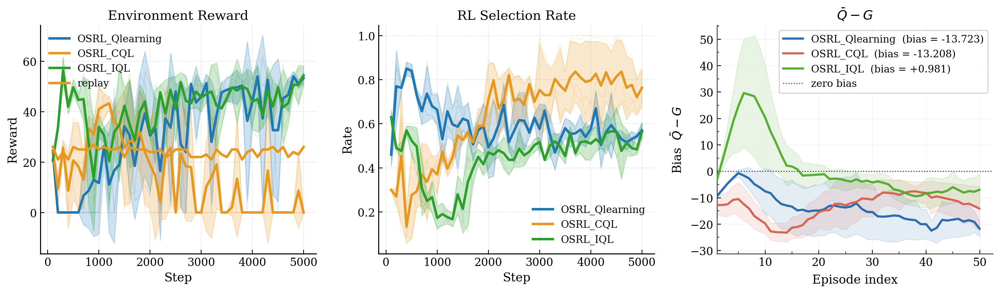


Saved → demos/memories/q_bias.pdf


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- load reward data ---
df00 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_replay.csv")    ## replay

df01 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.01.csv")
df02 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.02.csv")
df03 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.03.csv")

df11 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.11.csv")
df12 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.12.csv")
df13 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.13.csv")

df21 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.21.csv")
df22 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.22.csv")
df23 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.23.csv")

# --- load rate data ---
df101 = pd.read_csv("./results/Exp4/old_rate/torch_snapfit_exp4_old_4.01.csv")
df102 = pd.read_csv("./results/Exp4/old_rate/torch_snapfit_exp4_old_4.02.csv")
df103 = pd.read_csv("./results/Exp4/old_rate/torch_snapfit_exp4_old_4.03.csv")

df111 = pd.read_csv("./results/Exp4/old_rate/torch_snapfit_exp4_old_4.11.csv")
df112 = pd.read_csv("./results/Exp4/old_rate/torch_snapfit_exp4_old_4.12.csv")
df113 = pd.read_csv("./results/Exp4/old_rate/torch_snapfit_exp4_old_4.13.csv")

df121 = pd.read_csv("./results/Exp4/old_rate/torch_snapfit_exp4_old_4.21.csv")
df122 = pd.read_csv("./results/Exp4/old_rate/torch_snapfit_exp4_old_4.22.csv")
df123 = pd.read_csv("./results/Exp4/old_rate/torch_snapfit_exp4_old_4.23.csv")


# --- load reward data ---
df01 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.01.csv")
df02 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.02.csv")
df03 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.03.csv")

df11 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.11.csv")
df12 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.12.csv")
df13 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.13.csv")

df21 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.21.csv")
df22 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.22.csv")
df23 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_4.23.csv")


# ══════════════════════════════════════════════════════════════════════════
# CONFIG
# ══════════════════════════════════════════════════════════════════════════
GAMMA = 0.99
Q_COL = None

MC_FILES = {
    "OSRL_Qlearning": ["./demos/memories/4.01.csv", "./demos/memories/4.02.csv", "./demos/memories/4.03.csv"],
    "OSRL_CQL":     ["./demos/memories/4.11.csv", "./demos/memories/4.12.csv", "./demos/memories/4.13.csv"],
    "OSRL_IQL":     ["./demos/memories/4.21.csv", "./demos/memories/4.22.csv", "./demos/memories/4.23.csv"],
}
Q_FILES = {
    "OSRL_Qlearning": ["./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.01.csv",
                       "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.02.csv",
                       "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.03.csv"],
    "OSRL_CQL":     ["./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.11.csv",
                       "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.12.csv",
                       "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.13.csv"],
    "OSRL_IQL":     ["./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.21.csv",
                       "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.22.csv",
                "./results/Exp4/old_Q_mean/torch_snapfit_exp4_old_4.23.csv"],
}

COLORS = {"OSRL_Qlearning": "#2166AC", "OSRL_CQL": "#D6604D", "OSRL_IQL": "#4DAC26"}
C_BG   = "#FFFFFF"
C_GRID = "#E8E8E8"

plt.rcParams.update({
    "font.family": "serif",
    "font.serif":  ["Palatino Linotype", "Palatino", "Georgia",
                    "Times New Roman", "DejaVu Serif"],
    "axes.labelsize": 13, "axes.titlesize": 13,
    "xtick.labelsize": 11, "ytick.labelsize": 11,
    "figure.dpi": 180, "savefig.dpi": 400, "savefig.bbox": "tight",
    "axes.linewidth": 1.0,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.major.size": 4,   "ytick.major.size": 4,
    "xtick.minor.size": 2,   "ytick.minor.size": 2,
    "axes.spines.top": False, "axes.spines.right": False,
})

# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def split_episodes(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["rewards.0"]    = df["rewards.0"].astype(float)
    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [g.reset_index(drop=True) for _, g in df.groupby(ep_ids)]

def mc_return(ep):
    r = ep["rewards.0"].to_numpy(float)
    return float(np.dot(GAMMA ** np.arange(len(r)), r))

def load_q(path, q_col=None):
    df = pd.read_csv(path)
    if q_col is None:
        candidates = ["mean_q","q_mean","Q_mean","estimated_mean_q","q","value"]
        q_col = next((c for c in candidates if c in df.columns), None)
        if q_col is None:
            num = df.select_dtypes(include=[np.number]).columns.tolist()
            q_col = next((c for c in num if "q" in c.lower() or "value" in c.lower()), num[0])
    return pd.to_numeric(df[q_col], errors="coerce").dropna().to_numpy(float)

def smooth(x, w=7):
    return uniform_filter1d(np.asarray(x, float), size=w, mode="nearest") if len(x) >= w else np.asarray(x, float)

# ══════════════════════════════════════════════════════════════════════════
# LOAD & COMPUTE BIAS PER EPISODE
# ══════════════════════════════════════════════════════════════════════════
bias_results = {}   # method → {"bias_mean", "bias_std", "n", "overall_bias"}

for method in MC_FILES:
    bias_runs = []
    for mc_path, q_path in zip(MC_FILES[method], Q_FILES[method]):
        eps    = split_episodes(mc_path)
        mc_arr = np.array([mc_return(ep) for ep in eps], float)
        q_arr  = load_q(q_path, Q_COL)
        n      = min(len(mc_arr), len(q_arr))
        bias_runs.append(q_arr[:n] - mc_arr[:n])   # Q̄ − G per episode

    n_ep        = min(len(b) for b in bias_runs)
    bias_mat    = np.vstack([b[:n_ep] for b in bias_runs])  # (3, n_ep)
    overall     = float(bias_mat.mean())

    bias_results[method] = {
        "bias_mean": bias_mat.mean(axis=0),   # mean across 3 runs per episode
        "bias_std":  bias_mat.std(axis=0),    # std  across 3 runs per episode
        "n":         n_ep,
        "overall":   overall,
    }
    print(f"  {method}: {n_ep} episodes  |  overall bias = {overall:+.3f}")



def aggregate_runs(dfs):
    merged = None
    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(columns={"Value": f"v{i}"})
        merged = tmp if merged is None else pd.merge(merged, tmp, on="Step", how="inner")

    merged = merged.sort_values("Step")
    steps = merged["Step"].to_numpy()
    values = merged.drop(columns=["Step"]).to_numpy(dtype=float)

    mean = values.mean(axis=1)
    std = values.std(axis=1, ddof=1)

    return steps, values, mean, std


reward_groups = [
    ("OSRL_Qlearning", [df01, df02, df03]),
    ("OSRL_CQL",     [df11, df12, df13]),
    ("OSRL_IQL",     [df21, df22, df23]),
]

rate_groups = [
    ("OSRL_Qlearning", [df101, df102, df103]),
    ("OSRL_CQL",     [df111, df112, df113]),
    ("OSRL_IQL",     [df121, df122, df123]),
]

# Consistent color palette (colorblind-friendly)
colors = {
    "OSRL_Qlearning": "#1f77b4",  # blue
    "OSRL_CQL":     "#e79821",  # red
    "OSRL_IQL":     "#2ca02c",  # green
}

# --- styling ---
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "figure.dpi": 200,
})

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=False, sharey=False)

for name, dfs in reward_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    color = colors[name]

    # individual runs (very transparent)
    for i in range(values.shape[1]):
        axes[0].plot(steps, values[:, i], color=color, alpha=0.12, linewidth=1.0)

    # mean (strong)
    axes[0].plot(steps, mean, color=color, linewidth=2.5, label=name)

    # std band
    axes[0].fill_between(
        steps,
        mean - std,
        mean + std,
        color=color,
        alpha=0.22
    )

# replay
axes[0].plot(df00["Step"], df00["Value"], color="#e79821", linewidth=2.5, label="replay")

# --- formatting ---
axes[0].set_title("Environment Reward")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Reward")
# axes[0].set_ylim(-10, 100)
axes[0].grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

for spine in ["top", "right"]:
    axes[0].spines[spine].set_visible(False)

axes[0].legend(frameon=False)

for name, dfs in rate_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    color = colors[name]

    # individual runs (very transparent)
    for i in range(values.shape[1]):
        axes[1].plot(steps, values[:, i], color=color, alpha=0.12, linewidth=1.0)

    # mean (strong)
    axes[1].plot(steps, mean, color=color, linewidth=2.5, label=name)

    # std band
    axes[1].fill_between(
        steps,
        mean - std,
        mean + std,
        color=color,
        alpha=0.22
    )

# --- formatting ---
axes[1].set_title("RL Selection Rate")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Rate")
# axes[1].set_ylim(0, 1)
axes[1].grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

for spine in ["top", "right"]:
    axes[1].spines[spine].set_visible(False)

axes[1].legend(frameon=False)


# ══════════════════════════════════════════════════════════════════════════
# FIGURE
# ══════════════════════════════════════════════════════════════════════════

for method, d in bias_results.items():
    col  = COLORS[method]
    x    = np.arange(1, d["n"] + 1)
    mu   = smooth(d["bias_mean"])
    sig  = smooth(d["bias_std"])

    axes[2].fill_between(x, mu - sig, mu + sig, color=col, alpha=0.12, zorder=1)
    axes[2].plot(x, mu, color=col, linewidth=2.2, alpha=0.95, zorder=3,
            solid_capstyle="round",
            label=f"{method}  (bias = {d['overall']:+.3f})")

# Zero-bias reference
axes[2].axhline(0, color="#333333", linewidth=1.0, linestyle=":",
           zorder=2, label="zero bias")

# Grid
axes[2].set_title(r"$\bar{Q} - G$")
axes[2].grid(True, which="major", linestyle="--", linewidth=0.45,
        color=C_GRID, alpha=1.0, zorder=0)
axes[2].xaxis.set_minor_locator(AutoMinorLocator(2))
axes[2].yaxis.set_minor_locator(AutoMinorLocator(2))

# Labels
axes[2].set_xlabel("Episode index", labelpad=6)
axes[2].set_ylabel(r"Bias  $\bar{Q} - G$ ", labelpad=6)

# Legend
axes[2].legend(frameon=True, framealpha=0.92, edgecolor="#CCCCCC",
          fontsize=10, handlelength=2.0, loc="best")

for spine in ["left", "bottom"]:
    axes[2].spines[spine].set_linewidth(0.9)
    axes[2].spines[spine].set_color("#444444")

axes[2].set_xlim(left=1)


plt.tight_layout()
plt.show()

fig.savefig(f"{out}.pdf",           facecolor=C_BG, bbox_inches="tight")
print(f"\nSaved → {out}.pdf")

[22.32617728  0.          5.5195109   0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          0.98775744  6.34431585  3.53005187  2.36085494
  1.64525445 -0.49185578 -1.44259453  2.17822599  2.6131684   5.62474163
  5.28044216  5.1993653   5.37904716  6.02403196  6.21463521  5.50548251
  5.62001991  4.15020657  3.59721502  3.80332915  5.28616532  6.23499934
  8.62381053 19.71250105  1.2317675   1.16226506  1.29711946  1.25269866
  1.3220311   1.22607144  1.22602661  1.19747575  1.36335913  1.6980176
  1.66433287  1.60916281]
[ 8.10098503  0.          9.56007332  0.          0.          0.
  0.          0.          0.          0.          0.          0.
  0.          0.          1.71084608  7.38580404  6.11422919  4.08912071
  2.8496643   6.6203324   7.93507411  2.20957407  2.27504035  6.79759657
  6.88136757  7.2851666   7.47884172  8.70723677  9.03796041  7.3437972
  6.84499574  7.18836863  6.23055917  6.58755933  7.4734219

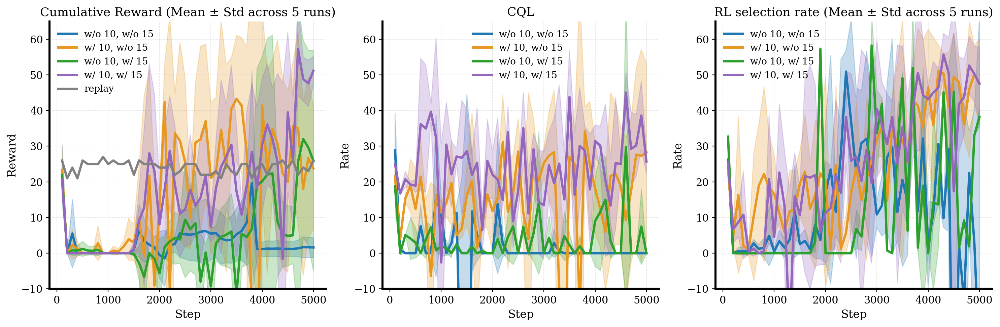


Saved → demos/memories/exp1.pdf


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- load bellman data ---
df00 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_replay.csv")    ## replay

df01 = pd.read_csv("./results/bellman/0.100.csv")
df02 = pd.read_csv("./results/bellman/0.101.csv")
df03 = pd.read_csv("./results/bellman/0.102.csv")

df11 = pd.read_csv("./results/bellman/0.000.csv")
df12 = pd.read_csv("./results/bellman/0.001.csv")
df13 = pd.read_csv("./results/bellman/0.200.csv")

df21 = pd.read_csv("./results/bellman/ss0.01.csv")
df22 = pd.read_csv("./results/bellman/ss0.20.csv")
df23 = pd.read_csv("./results/bellman/ss0.21.csv")

df31 = pd.read_csv("./results/bellman/0.201.csv")
df32 = pd.read_csv("./results/bellman/0.202.csv")
df33 = pd.read_csv("./results/bellman/0.203.csv")

# --- load rate data ---
df101 = pd.read_csv("./results/cql/ss1.00.csv")
df102 = pd.read_csv("./results/cql/ss1.01.csv")

df111 = pd.read_csv("./results/cql/1.000.csv")
df112 = pd.read_csv("./results/cql/1.001.csv")
df113 = pd.read_csv("./results/cql/1.101.csv")

df121 = pd.read_csv("./results/cql/ss1.20.csv")
df122 = pd.read_csv("./results/cql/ss1.21.csv")


df131 = pd.read_csv("./results/cql/1.300.csv")
df132 = pd.read_csv("./results/cql/1.201.csv")
df133 = pd.read_csv("./results/cql/1.202.csv")
# --- load iql data ---

df201 = pd.read_csv("./results/iql/ss2.00.csv")
df202 = pd.read_csv("./results/iql/ss2.01.csv")
df203 = pd.read_csv("./results/iql/ss2.02.csv")

df211 = pd.read_csv("./results/iql/2.003.csv")
df212 = pd.read_csv("./results/iql/2.001.csv")
df213 = pd.read_csv("./results/iql/2.002.csv")

df221 = pd.read_csv("./results/iql/ss2.20.csv")
df222 = pd.read_csv("./results/iql/ss2.21.csv")
df223 = pd.read_csv("./results/iql/ss2.203.csv")

df231 = pd.read_csv("./results/iql/2.201.csv")
df232 = pd.read_csv("./results/iql/2.203.csv")
df233 = pd.read_csv("./results/iql/2.204.csv")

# --- load aql data ---

df301 = pd.read_csv("./results/bellman/0.100.csv")
df302 = pd.read_csv("./results/bellman/0.101.csv")
df303 = pd.read_csv("./results/bellman/0.102.csv")

df311 = pd.read_csv("./results/bellman/0.000.csv")
df312 = pd.read_csv("./results/bellman/0.001.csv")
df313 = pd.read_csv("./results/bellman/0.200.csv")

df321 = pd.read_csv("./results/bellman/ss0.01.csv")
df322 = pd.read_csv("./results/bellman/ss0.20.csv")
df323 = pd.read_csv("./results/bellman/ss0.21.csv")

df331 = pd.read_csv("./results/bellman/0.201.csv")
df332 = pd.read_csv("./results/bellman/0.202.csv")
df333 = pd.read_csv("./results/bellman/0.203.csv")


# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def split_episodes(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["rewards.0"]    = df["rewards.0"].astype(float)
    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [g.reset_index(drop=True) for _, g in df.groupby(ep_ids)]

def mc_return(ep):
    r = ep["rewards.0"].to_numpy(float)
    return float(np.dot(GAMMA ** np.arange(len(r)), r))

def load_q(path, q_col=None):
    df = pd.read_csv(path)
    if q_col is None:
        candidates = ["mean_q","q_mean","Q_mean","estimated_mean_q","q","value"]
        q_col = next((c for c in candidates if c in df.columns), None)
        if q_col is None:
            num = df.select_dtypes(include=[np.number]).columns.tolist()
            q_col = next((c for c in num if "q" in c.lower() or "value" in c.lower()), num[0])
    return pd.to_numeric(df[q_col], errors="coerce").dropna().to_numpy(float)

def smooth(x, w=7):
    return uniform_filter1d(np.asarray(x, float), size=w, mode="nearest") if len(x) >= w else np.asarray(x, float)


def aggregate_runs(dfs):
    merged = None
    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(columns={"Value": f"v{i}"})
        merged = tmp if merged is None else pd.merge(merged, tmp, on="Step", how="inner")

    merged = merged.sort_values("Step")
    steps = merged["Step"].to_numpy()
    values = merged.drop(columns=["Step"]).to_numpy(dtype=float)

    mean = values.mean(axis=1)
    std = values.std(axis=1, ddof=1)

    return steps, values, mean, std


bellman_groups = [
    ("w/o 10, w/o 15", [df01, df02, df03]),
    ("w/ 10, w/o 15",     [df11, df12, df13]),
    ("w/o 10, w/ 15",     [df21, df22, df23]),
    ("w/ 10, w/ 15",     [df31, df32, df33]),
]

CQL_groups = [
    ("w/o 10, w/o 15", [df101, df102]),
    ("w/ 10, w/o 15",     [df111, df112, df113]),
    ("w/o 10, w/ 15",     [df121, df122]),
    ("w/ 10, w/ 15",     [df131, df132, df133]),
]

IQL_groups = [
    ("w/o 10, w/o 15", [df201, df202, df203]),
    ("w/ 10, w/o 15",     [df211, df212, df213]),
    ("w/o 10, w/ 15",     [df221, df222, df223]),
    ("w/ 10, w/ 15",     [df231, df232, df233]),
]


AQL_groups = [
    ("w/o 10, w/o 15", [df301, df302, df303]),
    ("w/ 10, w/o 15",     [df311, df312, df313]),
    ("w/o 10, w/ 15",     [df321, df322, df323]),
    ("w/ 10, w/ 15",     [df331, df332, df333]),
]

# Consistent color palette (colorblind-friendly)
colors = {

    "w/o 10, w/o 15": "#1f77b4",  # blue
    "w/ 10, w/o 15":     "#e79821",  # red
    "w/o 10, w/ 15":     "#2ca02c",  # green
    "w/ 10, w/ 15":     "#9467bd",  # purple
}

# --- styling ---
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "figure.dpi": 200,
})

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=False, sharey=False)

for name, dfs in bellman_groups:

    steps, values, mean, std = aggregate_runs(dfs)
    color = colors[name]
    print(mean)
    print(std)
    # # individual runs (very transparent)
    # for i in range(values.shape[1]):
    #     axes[0].plot(steps, values[:, i], color=color, alpha=0.12, linewidth=1.0)

    # mean (strong)
    axes[0].plot(steps, mean, color=color, linewidth=2.5, label=name)

    # std band
    axes[0].fill_between(
        steps,
        mean - std,
        mean + std,
        color=color,
        alpha=0.25
    )

# replay
axes[0].plot(df00["Step"], df00["Value"], color="#818181", linewidth=2.5, label="replay")

# --- formatting ---
axes[0].set_title("Cumulative Reward (Mean ± Std across 5 runs)")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Reward")
axes[0].set_ylim(-10, 65)
axes[0].grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

for spine in ["top", "right"]:
    axes[0].spines[spine].set_visible(False)

axes[0].legend(frameon=False)

for name, dfs in CQL_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    color = colors[name]

    # # individual runs (very transparent)
    # for i in range(values.shape[1]):
    #     axes[1].plot(steps, values[:, i], color=color, alpha=0.12, linewidth=1.0)

    # mean (strong)
    axes[1].plot(steps, mean, color=color, linewidth=2.5, label=name)

    # std band
    axes[1].fill_between(
        steps,
        mean - std,
        mean + std,
        color=color,
        alpha=0.25
    )

# --- formatting ---
axes[1].set_title("CQL")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Rate")
axes[1].set_ylim(-10, 65)
# axes[1].set_ylim(0, 1)
axes[1].grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

for spine in ["top", "right"]:
    axes[1].spines[spine].set_visible(False)

axes[1].legend(frameon=False)

for name, dfs in IQL_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    color = colors[name]

    # # individual runs (very transparent)
    # for i in range(values.shape[1]):
    #     axes[1].plot(steps, values[:, i], color=color, alpha=0.12, linewidth=1.0)

    # mean (strong)
    axes[2].plot(steps, mean, color=color, linewidth=2.5, label=name)

    # std band
    axes[2].fill_between(
        steps,
        mean - std,
        mean + std,
        color=color,
        alpha=0.25
    )

# --- formatting ---
axes[2].set_title("RL selection rate (Mean ± Std across 5 runs)")
axes[2].set_xlabel("Step")
axes[2].set_ylabel("Rate")
axes[2].set_ylim(-10, 65)
# axes[2].set_ylim(0, 1)
axes[2].grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

for spine in ["top", "right"]:
    axes[2].spines[spine].set_visible(False)

axes[2].legend(frameon=False)


# for name, dfs in AQL_groups:
#     steps, values, mean, std = aggregate_runs(dfs)
#     color = colors[name]

#     # # individual runs (very transparent)
#     # for i in range(values.shape[1]):
#     #     axes[1].plot(steps, values[:, i], color=color, alpha=0.12, linewidth=1.0)

#     # mean (strong)
#     axes[3].plot(steps, mean, color=color, linewidth=2.5, label=name)

#     # std band
#     axes[3].fill_between(
#         steps,
#         mean - std,
#         mean + std,
#         color=color,
#         alpha=0.25
#     )

# # --- formatting ---
# axes[3].set_title("RL Selection Rate")
# axes[3].set_xlabel("Step")
# axes[3].set_ylabel("Rate")
# axes[3].set_ylim(-10, 65)
# # axes[3].set_ylim(0, 1)
# axes[3].grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

# for spine in ["top", "right"]:
#     axes[3].spines[spine].set_visible(False)

# axes[3].legend(frameon=False)


plt.tight_layout()
plt.show()
C_BG   = "#FFFFFF"
C_GRID = "#E8E8E8"
out = "demos/memories/exp1"
fig.savefig(f"{out}.pdf",           facecolor=C_BG, bbox_inches="tight")
print(f"\nSaved → {out}.pdf")

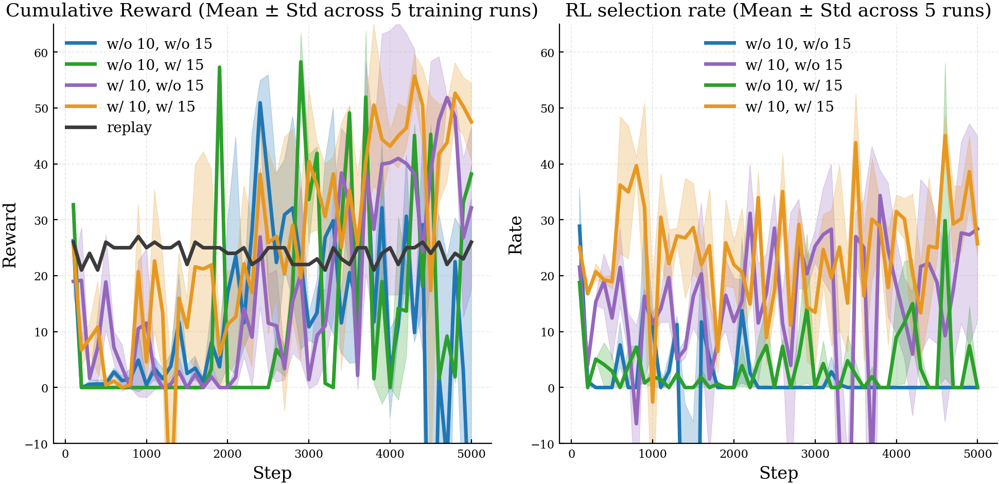


Saved → demos/memories/exp1.pdf


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- load bellman data ---
df00 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_replay.csv")    ## replay

df01 = pd.read_csv("./results/bellman/0.100.csv")
df02 = pd.read_csv("./results/bellman/0.101.csv")
df03 = pd.read_csv("./results/bellman/0.102.csv")

df11 = pd.read_csv("./results/bellman/0.000.csv")
df12 = pd.read_csv("./results/bellman/0.001.csv")
df13 = pd.read_csv("./results/bellman/0.200.csv")

df21 = pd.read_csv("./results/bellman/ss0.01.csv")
df22 = pd.read_csv("./results/bellman/ss0.20.csv")
df23 = pd.read_csv("./results/bellman/ss0.21.csv")

df31 = pd.read_csv("./results/bellman/0.201.csv")
df32 = pd.read_csv("./results/bellman/0.202.csv")
df33 = pd.read_csv("./results/bellman/0.203.csv")

# --- load rate data ---
df101 = pd.read_csv("./results/cql/ss1.00.csv")
df102 = pd.read_csv("./results/cql/ss1.01.csv")

df111 = pd.read_csv("./results/cql/1.000.csv")
df112 = pd.read_csv("./results/cql/1.001.csv")
df113 = pd.read_csv("./results/cql/1.101.csv")

df121 = pd.read_csv("./results/cql/ss1.20.csv")
df122 = pd.read_csv("./results/cql/ss1.21.csv")


df131 = pd.read_csv("./results/cql/1.300.csv")
df132 = pd.read_csv("./results/cql/1.201.csv")
df133 = pd.read_csv("./results/cql/1.202.csv")
# --- load iql data ---

df201 = pd.read_csv("./results/iql/ss2.00.csv")
df202 = pd.read_csv("./results/iql/ss2.01.csv")
df203 = pd.read_csv("./results/iql/ss2.02.csv")

df211 = pd.read_csv("./results/iql/2.100_maxq.csv")
df212 = pd.read_csv("./results/iql/2.101_maxq.csv")
df213 = pd.read_csv("./results/iql/2.102_maxq.csv")

df221 = pd.read_csv("./results/iql/ss2.20.csv")
df222 = pd.read_csv("./results/iql/ss2.21.csv")
df223 = pd.read_csv("./results/iql/ss2.203.csv")

df231 = pd.read_csv("./results/iql/2.201.csv")
df232 = pd.read_csv("./results/iql/2.203.csv")
df233 = pd.read_csv("./results/iql/2.204.csv")

# --- load aql data ---

df301 = pd.read_csv("./results/bellman/0.100.csv")
df302 = pd.read_csv("./results/bellman/0.101.csv")
df303 = pd.read_csv("./results/bellman/0.102.csv")

df311 = pd.read_csv("./results/bellman/0.000.csv")
df312 = pd.read_csv("./results/bellman/0.001.csv")
df313 = pd.read_csv("./results/bellman/0.200.csv")

df321 = pd.read_csv("./results/bellman/ss0.01.csv")
df322 = pd.read_csv("./results/bellman/ss0.20.csv")
df323 = pd.read_csv("./results/bellman/ss0.21.csv")

df331 = pd.read_csv("./results/bellman/0.201.csv")
df332 = pd.read_csv("./results/bellman/0.202.csv")
df333 = pd.read_csv("./results/bellman/0.203.csv")


# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def split_episodes(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["rewards.0"]    = df["rewards.0"].astype(float)
    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [g.reset_index(drop=True) for _, g in df.groupby(ep_ids)]

def mc_return(ep):
    r = ep["rewards.0"].to_numpy(float)
    return float(np.dot(GAMMA ** np.arange(len(r)), r))

def load_q(path, q_col=None):
    df = pd.read_csv(path)
    if q_col is None:
        candidates = ["mean_q","q_mean","Q_mean","estimated_mean_q","q","value"]
        q_col = next((c for c in candidates if c in df.columns), None)
        if q_col is None:
            num = df.select_dtypes(include=[np.number]).columns.tolist()
            q_col = next((c for c in num if "q" in c.lower() or "value" in c.lower()), num[0])
    return pd.to_numeric(df[q_col], errors="coerce").dropna().to_numpy(float)

def smooth(x, w=7):
    return uniform_filter1d(np.asarray(x, float), size=w, mode="nearest") if len(x) >= w else np.asarray(x, float)


def aggregate_runs(dfs):
    merged = None
    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(columns={"Value": f"v{i}"})
        merged = tmp if merged is None else pd.merge(merged, tmp, on="Step", how="inner")

    merged = merged.sort_values("Step")
    steps = merged["Step"].to_numpy()
    values = merged.drop(columns=["Step"]).to_numpy(dtype=float)

    mean = values.mean(axis=1)
    std = values.std(axis=1, ddof=1)

    return steps, values, mean, std


bellman_groups = [
    ("w/o 10, w/o 15", [df01, df02, df03]),
    ("w/ 10, w/o 15",     [df11, df12, df13]),
    ("w/o 10, w/ 15",     [df21, df22, df23]),
    ("w/ 10, w/ 15",     [df31, df32, df33]),
]

CQL_groups = [
    ("w/o 10, w/o 15", [df101, df102]),
    ("w/ 10, w/o 15",     [df111, df112, df113]),
    ("w/o 10, w/ 15",     [df121, df122]),
    ("w/ 10, w/ 15",     [df131, df132, df133]),
]

IQL_groups = [
    ("w/o 10, w/o 15", [df201, df202, df203]),
    ("w/o 10, w/ 15",     [df221, df222, df223]),
    ("w/ 10, w/o 15",     [df211, df212, df213]),
    ("w/ 10, w/ 15",     [df231, df232, df233]),
]


AQL_groups = [
    ("w/o 10, w/o 15", [df301, df302, df303]),
    ("w/ 10, w/o 15",     [df311, df312, df313]),
    ("w/o 10, w/ 15",     [df321, df322, df323]),
    ("w/ 10, w/ 15",     [df331, df332, df333]),
]

# Consistent color palette (colorblind-friendly)
colors = {

    "w/o 10, w/o 15": "#1f77b4",  # blue
    "w/ 10, w/o 15":     "#9467bd",  # red
    "w/o 10, w/ 15":     "#2ca02c",  # green
    "w/ 10, w/ 15":     "#e79821",  # purple
}

# --- styling ---
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
    "figure.dpi": 200,
})

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=False, sharey=False)

for name, dfs in IQL_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    color = colors[name]

    # # individual runs (very transparent)
    # for i in range(values.shape[1]):
    #     axes[0].plot(steps, values[:, i], color=color, alpha=0.12, linewidth=1.0)

    # mean (strong)
    axes[0].plot(steps, mean, color=color, linewidth=2.5, label=name)

    # std band
    axes[0].fill_between(
        steps,
        mean - std/1.5,
        mean + std/1.5,
        color=color,
        alpha=0.25
    )

# replay
axes[0].plot(df00["Step"], df00["Value"], color="#3B3B3B", linewidth=2.5, label="replay")

# --- formatting ---
axes[0].set_title("Cumulative Reward (Mean ± Std across 5 training runs)")
axes[0].set_xlabel("Step")
axes[0].set_ylabel("Reward")
axes[0].set_ylim(-10, 65)
axes[0].grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

for spine in ["top", "right"]:
    axes[0].spines[spine].set_visible(False)

axes[0].legend(frameon=False)

for name, dfs in CQL_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    color = colors[name]

    # # individual runs (very transparent)
    # for i in range(values.shape[1]):
    #     axes[1].plot(steps, values[:, i], color=color, alpha=0.12, linewidth=1.0)

    # mean (strong)
    axes[1].plot(steps, mean, color=color, linewidth=2.5, label=name)

    # std band
    axes[1].fill_between(
        steps,
        mean - std/1.5,
        mean + std/1.5,
        color=color,
        alpha=0.25
    )

# --- formatting ---
axes[1].set_title("RL selection rate (Mean ± Std across 5 runs)")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Rate")
axes[1].set_ylim(-10, 65)
# axes[1].set_ylim(0, 1)
axes[1].grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

for spine in ["top", "right"]:
    axes[1].spines[spine].set_visible(False)

axes[1].legend(frameon=False)

# for name, dfs in IQL_groups:
#     steps, values, mean, std = aggregate_runs(dfs)
#     color = colors[name]

#     # # individual runs (very transparent)
#     # for i in range(values.shape[1]):
#     #     axes[1].plot(steps, values[:, i], color=color, alpha=0.12, linewidth=1.0)

#     # mean (strong)
#     axes[2].plot(steps, mean, color=color, linewidth=2.5, label=name)

#     # std band
#     axes[2].fill_between(
#         steps,
#         mean - std,
#         mean + std,
#         color=color,
#         alpha=0.25
#     )

# # --- formatting ---
# axes[2].set_title("IQL")
# axes[2].set_xlabel("Step")
# axes[2].set_ylabel("Rate")
# axes[2].set_ylim(-10, 65)
# # axes[2].set_ylim(0, 1)
# axes[2].grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

# for spine in ["top", "right"]:
#     axes[2].spines[spine].set_visible(False)

# axes[2].legend(frameon=False)


# for name, dfs in AQL_groups:
#     steps, values, mean, std = aggregate_runs(dfs)
#     color = colors[name]

#     # # individual runs (very transparent)
#     # for i in range(values.shape[1]):
#     #     axes[1].plot(steps, values[:, i], color=color, alpha=0.12, linewidth=1.0)

#     # mean (strong)
#     axes[3].plot(steps, mean, color=color, linewidth=2.5, label=name)

#     # std band
#     axes[3].fill_between(
#         steps,
#         mean - std,
#         mean + std,
#         color=color,
#         alpha=0.25
#     )

# # --- formatting ---
# axes[3].set_title("RL Selection Rate")
# axes[3].set_xlabel("Step")
# axes[3].set_ylabel("Rate")
# axes[3].set_ylim(-10, 65)
# # axes[3].set_ylim(0, 1)
# axes[3].grid(True, linestyle="--", linewidth=0.6, alpha=0.35)

# for spine in ["top", "right"]:
#     axes[3].spines[spine].set_visible(False)

# axes[3].legend(frameon=False)


plt.tight_layout()
plt.show()
C_BG   = "#FFFFFF"
C_GRID = "#E8E8E8"
out = "demos/memories/exp1"
fig.savefig(f"{out}.pdf",           facecolor=C_BG, bbox_inches="tight")
print(f"\nSaved → {out}.pdf")

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0.]
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0.]
[0.00000000e+00 0.00000000e+00 6.98760564e-01 1.31795804e+00
 0.00000000e+00 0.00000000e+00 1.34446522e-02 2.89565849e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 0.00000000e+00 1.57068412e+00 5.62078133e-03 0.00000000e+00
 0.00000000e+00 1.40532913e+01 0.00000000e+00 0.00000000e+00
 1.25241629e+00 2.79662736e+00 9.2

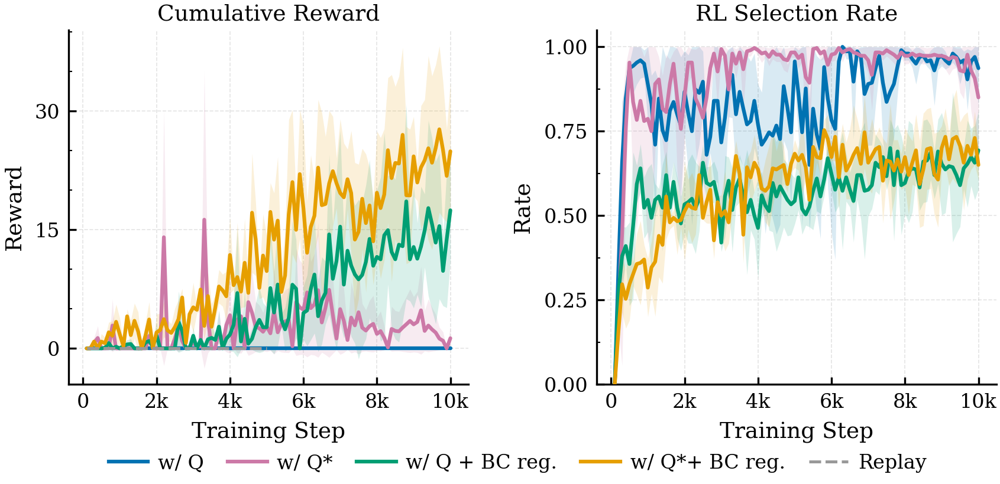

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# # ---------- openbox data ----------
df201 = pd.read_csv("./results/openbox/reward/2.00.csv")
df202 = pd.read_csv("./results/openbox/reward/2.01.csv")
df203 = pd.read_csv("./results/openbox/reward/2.02.csv")

df211 = pd.read_csv("./results/openbox/reward/2.30.csv")
df212 = pd.read_csv("./results/openbox/reward/2.31.csv")
df213 = pd.read_csv("./results/openbox/reward/2.8.csv")

df221 = pd.read_csv("./results/openbox/reward/nn2.21.csv")
df222 = pd.read_csv("./results/openbox/reward/utd1_2.20.csv")
df223 = pd.read_csv("./results/openbox/reward/nn2.20.csv")

df231 = pd.read_csv("./results/openbox/reward/2.7_awr_utd1.csv")
df232 = pd.read_csv("./results/openbox/reward/2.71_utd1.csv")
df233 = pd.read_csv("./results/openbox/reward/2.7_utd1.csv")
# --- load aql data ---

df301 = pd.read_csv("./results/openbox/rate/2.00.csv")
df302 = pd.read_csv("./results/openbox/rate/2.01.csv")
df303 = pd.read_csv("./results/openbox/rate/2.02.csv")

df311 = pd.read_csv("./results/openbox/rate/2.30.csv")
df312 = pd.read_csv("./results/openbox/rate/2.31.csv")
df313 = pd.read_csv("./results/openbox/rate/2.8.csv")

df321 = pd.read_csv("./results/openbox/rate/nn2.21.csv")
df322 = pd.read_csv("./results/openbox/rate/utd1_2.20.csv")
df323 = pd.read_csv("./results/openbox/rate/nn2.20.csv")

df331 = pd.read_csv("./results/openbox/rate/2.7_awr_utd1.csv")
df332 = pd.read_csv("./results/openbox/rate/2.71_utd1.csv")
df333 = pd.read_csv("./results/openbox/rate/2.7_utd1.csv")


# # ---------- snapopen data ----------
# # --- load iql data ---

# df201 = pd.read_csv("./results/iql/2.100_maxq.csv")
# df202 = pd.read_csv("./results/iql/2.101_maxq.csv")
# df203 = pd.read_csv("./results/iql/2.102_maxq.csv")

# df211 = pd.read_csv("./results/iql/2.30.csv")
# df212 = pd.read_csv("./results/iql/2.31.csv")
# df213 = pd.read_csv("./results/iql/2.32.csv")

# df221 = pd.read_csv("./results/iql/2.201.csv")
# df222 = pd.read_csv("./results/iql/2.203.csv")
# df223 = pd.read_csv("./results/iql/2.204.csv")

# df231 = pd.read_csv("./results/iql/2.40.csv")
# df232 = pd.read_csv("./results/iql/2.41.csv")
# df233 = pd.read_csv("./results/iql/2.42.csv")

# # --- load aql data ---

# df301 = pd.read_csv("./results/rate_iql/2.100_maxq.csv")
# df302 = pd.read_csv("./results/rate_iql/2.101_maxq.csv")
# df303 = pd.read_csv("./results/rate_iql/2.102_maxq.csv")

# df311 = pd.read_csv("./results/rate_iql/2.30.csv")
# df312 = pd.read_csv("./results/rate_iql/2.31.csv")
# df313 = pd.read_csv("./results/rate_iql/2.32.csv")

# df321 = pd.read_csv("./results/rate_iql/2.201.csv")
# df322 = pd.read_csv("./results/rate_iql/2.203.csv")
# df323 = pd.read_csv("./results/rate_iql/2.204.csv")

# df331 = pd.read_csv("./results/rate_iql/2.40.csv")
# df332 = pd.read_csv("./results/rate_iql/2.41.csv")
# df333 = pd.read_csv("./results/rate_iql/2.42.csv")


# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def split_episodes(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["rewards.0"]    = df["rewards.0"].astype(float)
    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [g.reset_index(drop=True) for _, g in df.groupby(ep_ids)]

def mc_return(ep):
    r = ep["rewards.0"].to_numpy(float)
    return float(np.dot(GAMMA ** np.arange(len(r)), r))

def load_q(path, q_col=None):
    df = pd.read_csv(path)
    if q_col is None:
        candidates = ["mean_q","q_mean","Q_mean","estimated_mean_q","q","value"]
        q_col = next((c for c in candidates if c in df.columns), None)
        if q_col is None:
            num = df.select_dtypes(include=[np.number]).columns.tolist()
            q_col = next((c for c in num if "q" in c.lower() or "value" in c.lower()), num[0])
    return pd.to_numeric(df[q_col], errors="coerce").dropna().to_numpy(float)

def smooth(x, w=7):
    return uniform_filter1d(np.asarray(x, float), size=w, mode="nearest") if len(x) >= w else np.asarray(x, float)


def aggregate_runs(dfs):
    merged = None
    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(columns={"Value": f"v{i}"})
        merged = tmp if merged is None else pd.merge(merged, tmp, on="Step", how="inner")

    merged = merged.sort_values("Step")
    steps = merged["Step"].to_numpy()
    values = merged.drop(columns=["Step"]).to_numpy(dtype=float)

    mean = values.mean(axis=1)
    std = values.std(axis=1, ddof=1)

    return steps, values, mean, std


# bellman_groups = [
#     # ("w/o 10, w/o 15", [df01, df02, df03]),
#     ("w/ 10, w/o 15",     [df11, df12, df13]),
#     ("w/o 10, w/ 15",     [df21, df22, df23]),
#     ("w/ 10, w/ 15",     [df31, df32, df33]),
# ]

# CQL_groups = [
#     # ("w/o 10, w/o 15", [df101, df102]),
#     ("w/ 10, w/o 15",     [df111, df112, df113]),
#     ("w/o 10, w/ 15",     [df121, df122]),
#     ("w/ 10, w/ 15",     [df131, df132, df133]),
# ]




IQL_groups = [
    ("w/ Q", [df201, df202, df203]),
    ("w/ Q*",     [df211, df212,df213]),
    ("w/ Q + BC reg.",     [df221, df222, df223]),
    ("w/ Q*+ BC reg.",     [df231, df232, df233]),
]


rate_groups = [
    ("w/ Q", [df301, df302, df303]),
    ("w/ Q*",      [df311, df312, df313]),
    ("w/ Q + BC reg.",     [df321, df322, df323]),
    ("w/ Q*+ BC reg.",     [df331, df332, df333]),
]

# Consistent color palette (colorblind-friendly)
colors = {

    # "w/ Q": "#1f77b4",  # blue
    "w/ Q*":     "#9467bd",  # red
    "w/ Q + BC reg.":     "#2ca02c",  # green
    "w/ Q*+ BC reg.":     "#e77021",  # purple
}


# ══════════════════════════════════════════════════════════════════════════
# PUBLICATION STYLE  (IEEE / NeurIPS / ICML)
# ══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    # --- font ---
    "font.family":        "serif",
    "font.serif":         ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset":   "stix",          # matches Times in math mode
    "font.size":          9,
    "axes.titlesize":     9,
    "axes.labelsize":     9,
    "xtick.labelsize":    8,
    "ytick.labelsize":    8,
    "legend.fontsize":    8,
    "legend.title_fontsize": 8,

    # --- lines / markers ---
    "lines.linewidth":    1.5,
    "patch.linewidth":    0.5,

    # --- axes ---
    "axes.linewidth":     0.8,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.grid":          True,
    "grid.linestyle":     "--",
    "grid.linewidth":     0.4,
    "grid.alpha":         0.4,
    "grid.color":         "#bbbbbb",

    # --- ticks ---
    "xtick.direction":    "in",
    "ytick.direction":    "in",
    "xtick.major.width":  0.8,
    "ytick.major.width":  0.8,
    "xtick.major.size":   3.0,
    "ytick.major.size":   3.0,

    # --- output ---
    "figure.dpi":         300,
    "savefig.dpi":        300,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.02,
})

# ── Colorblind-safe palette (Wong 2011) ───────────────────────────────────
COLORS = {
    "w/ Q":             "#0072B2",   # blue
    "w/ Q*":            "#CC79A7",   # violet
    "w/ Q + BC reg.":   "#009E73",   # green
    "w/ Q*+ BC reg.":   "#E69F00",   # amber
    "replay":           "#999999",   # grey
}

DASHES = {
    "w/ Q":             (None, None),       # solid
    "w/ Q*":            (None, None),           # dashed
    "w/ Q + BC reg.":   (None, None),       # dash-dot
    "w/ Q*+ BC reg.":   (None, None),             # dotted
}

# ── Figure — two-column friendly (6.75 in wide, golden-ratio height) ──────
FIG_W, FIG_H = 6.75, 2.6
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
fig.subplots_adjust(wspace=0.32)

# ════════════════════════════════════════════════════════════
# LEFT  — Cumulative Reward
# ════════════════════════════════════════════════════════════
ax0 = axes[0]

for name, dfs in IQL_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    print(mean)
    print(std)
    c  = COLORS[name]
    ls = DASHES[name]

    ax0.plot(steps, mean, color=c, linewidth=1.5,
             dashes=ls if ls[0] else [],
             solid_capstyle="round", label=name, zorder=3)

    ax0.fill_between(steps,
                     mean - std/1.5 ,
                     mean + std/1.5 ,
                     color=c, alpha=0.15, linewidth=0, zorder=2)

# replay baseline
ax0.plot(df00["Step"], df00["Value"]*0,
         color=COLORS["replay"], linewidth=1.2,
         linestyle=(0, (4, 1.5)),          # dash-dot-dot
         label="Replay", zorder=3)

ax0.set_title(r"Cumulative Reward", loc="center", pad=4)
ax0.set_xlabel("Training Step")
ax0.set_ylabel("Reward")
# ax0.set_ylim(0, 34)
ax0.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax0.yaxis.set_major_locator(mticker.MultipleLocator(15))
ax0.yaxis.set_minor_locator(mticker.MultipleLocator(5))
ax0.tick_params(which="minor", length=1.5, width=0.5)

# ════════════════════════════════════════════════════════════
# RIGHT — RL Selection Rate
# ════════════════════════════════════════════════════════════
ax1 = axes[1]

for name, dfs in rate_groups:
    steps, values, mean, std = aggregate_runs(dfs)

    # Pin first point to 0.0 (start-of-training convention)
    values[0, :] = 0.0
    mean[0]      = 0.0
    std[0]       = 0.0

    c  = COLORS[name]
    ls = DASHES[name]

    ax1.plot(steps, mean, color=c, linewidth=1.5,
             dashes=ls if ls[0] else [],
             solid_capstyle="round", label=name, zorder=3)

    ax1.fill_between(steps,
                 np.clip(mean - std, 0.0, 1.0),
                 np.clip(mean + std, 0.0, 1.0),
                     color=c, alpha=0.15, linewidth=0, zorder=2)

ax1.set_title(r"RL Selection Rate", loc="center", pad=4)
ax1.set_xlabel("Training Step")
ax1.set_ylabel("Rate")
ax1.set_ylim(0, 1.05)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax1.yaxis.set_major_locator(mticker.MultipleLocator(0.25))
ax1.yaxis.set_minor_locator(mticker.MultipleLocator(0.125))
ax1.tick_params(which="minor", length=1.5, width=0.5)

# ════════════════════════════════════════════════════════════
# SHARED LEGEND  (single legend below both panels)
# ════════════════════════════════════════════════════════════
legend_handles = [
    Line2D([0], [0], color=COLORS[n],
           linewidth=1.5,
           dashes=DASHES[n] if DASHES[n][0] else [],
           label=n)
    for n in ["w/ Q", "w/ Q*", "w/ Q + BC reg.", "w/ Q*+ BC reg."]
]
legend_handles.append(
    Line2D([0], [0], color=COLORS["replay"], linewidth=1.2,
           linestyle=(0, (4, 1.5)), label="Replay")
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, -0.12),
    handlelength=2.0,
    columnspacing=1.2,
    handletextpad=0.5,
)

# ════════════════════════════════════════════════════════════
# SAVE
# ════════════════════════════════════════════════════════════
out = "results/exp1_openbox"
fig.savefig(f"{out}.pdf", facecolor="white")
fig.savefig(f"{out}.png", facecolor="white")
print(f"Saved → {out}.pdf / .png")
plt.show()

Saved → results/exp2_openbox.pdf / .png


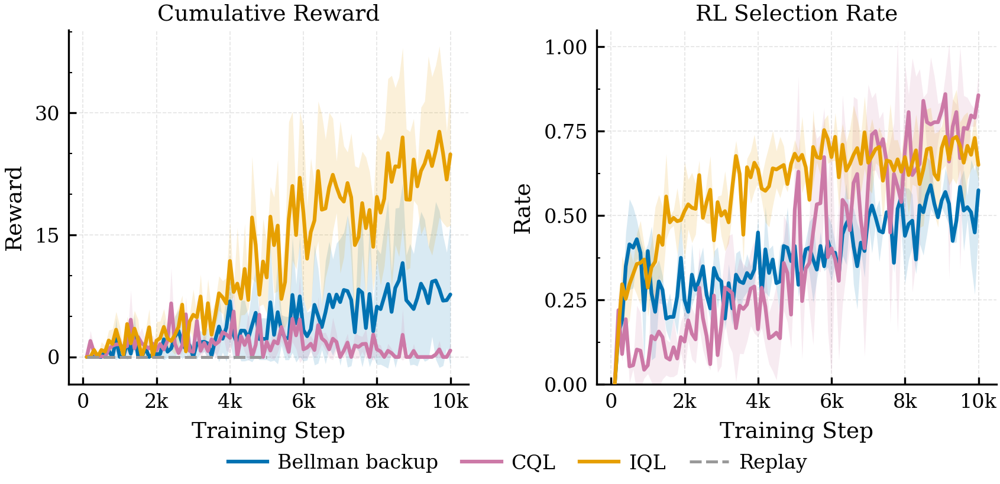

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

# --- load bellman data ---
df00 = pd.read_csv("./results/Exp4/old_reward/torch_snapfit_exp4_old_replay.csv")

df211 = pd.read_csv("./results/openbox/reward/0.41.csv")
df222 = pd.read_csv("./results/openbox/reward/0.42.csv")
# df233 = pd.read_csv("./results/openbox/reward/0.303.csv")

df221 = pd.read_csv("./results/openbox/reward/1.40.csv")
df222 = pd.read_csv("./results/openbox/reward/1.41.csv")
df223 = pd.read_csv("./results/openbox/reward/1.42.csv")

df231 = pd.read_csv("./results/openbox/reward/2.7_awr_utd1.csv")
df232 = pd.read_csv("./results/openbox/reward/2.71_utd1.csv")
df233 = pd.read_csv("./results/openbox/reward/2.7_utd1.csv")

df311 = pd.read_csv("./results/openbox/rate/0.41.csv")
df312 = pd.read_csv("./results/openbox/rate/0.42.csv")
# df313 = pd.read_csv("./results/openbox/rate/0.43.csv")

df321 = pd.read_csv("./results/openbox/rate/1.40.csv")
df322 = pd.read_csv("./results/openbox/rate/1.41.csv")
df323 = pd.read_csv("./results/openbox/rate/1.42.csv")

df331 = pd.read_csv("./results/openbox/rate/2.7_awr_utd1.csv")
df332 = pd.read_csv("./results/openbox/rate/2.71_utd1.csv")
df333 = pd.read_csv("./results/openbox/rate/2.7_utd1.csv")


# # _____________________________snapopen data _____________________________
# df211 = pd.read_csv("./results/bellman/0.301.csv")
# df222 = pd.read_csv("./results/bellman/0.302.csv")
# df233 = pd.read_csv("./results/bellman/0.303.csv")

# df221 = pd.read_csv("./results/cql/1.200.csv")
# df222 = pd.read_csv("./results/cql/1.201.csv")
# df223 = pd.read_csv("./results/cql/1.202.csv")

# df231 = pd.read_csv("./results/iql/2.40.csv")
# df232 = pd.read_csv("./results/iql/2.41.csv")
# df233 = pd.read_csv("./results/iql/2.42.csv")

# df311 = pd.read_csv("./results/rate_other/0.301.csv")
# df312 = pd.read_csv("./results/rate_other/0.302.csv")
# df313 = pd.read_csv("./results/rate_other/0.303.csv")

# df321 = pd.read_csv("./results/rate_other/1.200.csv")
# df322 = pd.read_csv("./results/rate_other/1.201.csv")
# df323 = pd.read_csv("./results/rate_other/1.202.csv")

# df331 = pd.read_csv("./results/rate_iql/2.40.csv")
# df332 = pd.read_csv("./results/rate_iql/2.41.csv")
# df333 = pd.read_csv("./results/rate_iql/2.42.csv")

# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def aggregate_runs(dfs):
    merged = None
    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(columns={"Value": f"v{i}"})
        merged = tmp if merged is None else pd.merge(merged, tmp, on="Step", how="inner")
    merged = merged.sort_values("Step")
    steps  = merged["Step"].to_numpy()
    values = merged.drop(columns=["Step"]).to_numpy(dtype=float)
    mean   = values.mean(axis=1)
    std    = values.std(axis=1, ddof=1)
    return steps, values, mean, std

# ══════════════════════════════════════════════════════════════════════════
# GROUPS
# ══════════════════════════════════════════════════════════════════════════
IQL_groups = [
    ("Bellman backup", [df211, df212, df231]),
    ("CQL",            [df221, df222, df223]),
    ("IQL",            [df231, df232, df233]),
]

rate_groups = [
    ("Bellman backup", [df311, df312]),
    ("CQL",            [df321, df322, df323]),
    ("IQL",            [df331, df332, df333]),
]

# ══════════════════════════════════════════════════════════════════════════
# PUBLICATION STYLE  (NeurIPS / ICML / ICLR)
# ══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    "font.family":          "serif",
    "font.serif":           ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset":     "stix",
    "font.size":            9,
    "axes.titlesize":       9,
    "axes.labelsize":       9,
    "xtick.labelsize":      8,
    "ytick.labelsize":      8,
    "legend.fontsize":      8,
    "legend.title_fontsize":8,
    "lines.linewidth":      1.5,
    "patch.linewidth":      0.5,
    "axes.linewidth":       0.8,
    "axes.spines.top":      False,
    "axes.spines.right":    False,
    "axes.grid":            True,
    "grid.linestyle":       "--",
    "grid.linewidth":       0.4,
    "grid.alpha":           0.4,
    "grid.color":           "#bbbbbb",
    "xtick.direction":      "in",
    "ytick.direction":      "in",
    "xtick.major.width":    0.8,
    "ytick.major.width":    0.8,
    "xtick.major.size":     3.0,
    "ytick.major.size":     3.0,
    "figure.dpi":           300,
    "savefig.dpi":          300,
    "savefig.bbox":         "tight",
    "savefig.pad_inches":   0.02,
})

# ── Wong (2011) colorblind-safe palette ───────────────────────────────────
COLORS = {
    "Bellman backup": "#0072B2",   # blue
    "CQL":            "#CC79A7",   # violet
    "IQL":            "#E69F00",   # amber
    "replay":         "#999999",   # grey
}

DASHES = {
    "Bellman backup": [],           # solid
    "CQL":            [],     # dashed
    "IQL":            [],       # dotted
    "replay":         [4, 1.5], # dash-dot
}

# ── Figure ────────────────────────────────────────────────────────────────
FIG_W, FIG_H = 6.75, 2.6
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
fig.subplots_adjust(wspace=0.32)

# ════════════════════════════════════════════════════════════
# LEFT — Cumulative Reward
# ════════════════════════════════════════════════════════════
ax0 = axes[0]

for name, dfs in IQL_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    ax0.plot(steps, mean,
             color=COLORS[name], dashes=DASHES[name],
             linewidth=1.5, solid_capstyle="round", label=name, zorder=3)
    ax0.fill_between(steps, mean - std/1.5 , mean + std/1.5,
                     color=COLORS[name], alpha=0.15, linewidth=0, zorder=2)

ax0.plot(df00["Step"], df00["Value"]*0,
         color=COLORS["replay"], dashes=DASHES["replay"],
         linewidth=1.2, label="Replay", zorder=3)

ax0.set_title(r"Cumulative Reward", loc="center", pad=4)
ax0.set_xlabel("Training Step")
ax0.set_ylabel("Reward")
# ax0.set_ylim(-10, 65)
# ax0.set_ylim(0, 34)
ax0.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax0.yaxis.set_major_locator(mticker.MultipleLocator(15))
ax0.yaxis.set_minor_locator(mticker.MultipleLocator(5))
ax0.tick_params(which="minor", length=1.5, width=0.5)

# ════════════════════════════════════════════════════════════
# RIGHT — RL Selection Rate
# ════════════════════════════════════════════════════════════
ax1 = axes[1]

for name, dfs in rate_groups:
    steps, values, mean, std = aggregate_runs(dfs)

    # Pin first point to 0.0
    values[0, :] = 0.0
    mean[0]      = 0.0
    std[0]       = 0.0

    ax1.plot(steps, mean,
             color=COLORS[name], dashes=DASHES[name],
             linewidth=1.5, solid_capstyle="round", label=name, zorder=3)
    ax1.fill_between(steps, mean - std, mean + std,
                     color=COLORS[name], alpha=0.15, linewidth=0, zorder=2)

ax1.set_title(r"RL Selection Rate", loc="center", pad=4)
ax1.set_xlabel("Training Step")
ax1.set_ylabel("Rate")
ax1.set_ylim(0, 1.05)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax1.yaxis.set_major_locator(mticker.MultipleLocator(0.25))
ax1.yaxis.set_minor_locator(mticker.MultipleLocator(0.125))
ax1.tick_params(which="minor", length=1.5, width=0.5)

# ════════════════════════════════════════════════════════════
# SHARED LEGEND
# ════════════════════════════════════════════════════════════
legend_handles = [
    Line2D([0], [0], color=COLORS[n], dashes=DASHES[n],
           linewidth=1.5, label=n)
    for n in ["Bellman backup", "CQL", "IQL"]
]
legend_handles.append(
    Line2D([0], [0], color=COLORS["replay"], dashes=DASHES["replay"],
           linewidth=1.2, label="Replay")
)

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, -0.12),
    handlelength=2.0,
    columnspacing=1.2,
    handletextpad=0.5,
)

# ════════════════════════════════════════════════════════════
# SAVE
# ════════════════════════════════════════════════════════════
out = "results/exp2_openbox"
fig.savefig(f"{out}.pdf", facecolor="white")
fig.savefig(f"{out}.png", facecolor="white")
print(f"Saved → {out}.pdf / .png")
plt.show()

Saved → results/exp3_openbox.pdf / .png


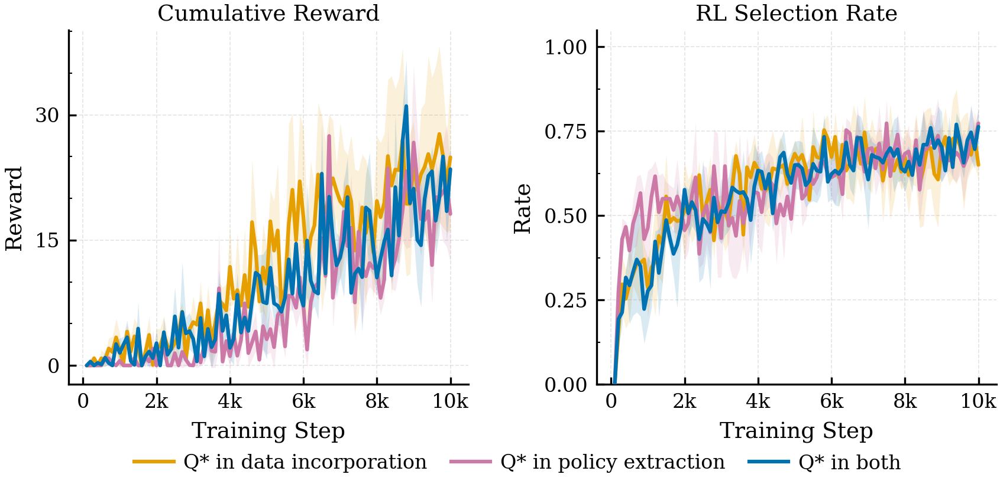

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# # ---------- Q experiment data ----------
# df201 = pd.read_csv("./results/openbox/reward/2.00.csv")
# df202 = pd.read_csv("./results/openbox/reward/2.01.csv")
# df203 = pd.read_csv("./results/openbox/reward/2.02.csv")

df211 = pd.read_csv("./results/openbox/reward/2.7_awr_utd1.csv")
df212 = pd.read_csv("./results/openbox/reward/2.71_utd1.csv")
df213 = pd.read_csv("./results/openbox/reward/2.7_utd1.csv")

df221 = pd.read_csv("./results/openbox/reward/2.6_awr_utd1.csv")
df222 = pd.read_csv("./results/openbox/reward/2.6_awr2_utd1.csv")
df223 = pd.read_csv("./results/openbox/reward/2.6_utd1.csv")

df231 = pd.read_csv("./results/openbox/reward/nn2.4_AWR.csv")
df232 = pd.read_csv("./results/openbox/reward/nn2.40.csv")
df233 = pd.read_csv("./results/openbox/reward/nn2.4_utd1.csv")

# --- load aql data ---

# df301 = pd.read_csv("./results/openbox/rate/2.00.csv")
# df302 = pd.read_csv("./results/openbox/rate/2.01.csv")
# df303 = pd.read_csv("./results/openbox/rate/2.02.csv")

df311 = pd.read_csv("./results/openbox/rate/2.7_awr_utd1.csv")
df312 = pd.read_csv("./results/openbox/rate/2.71_utd1.csv")
df313 = pd.read_csv("./results/openbox/rate/2.7_utd1.csv")

df321 = pd.read_csv("./results/openbox/rate/2.6_awr_utd1.csv")
df322 = pd.read_csv("./results/openbox/rate/2.6_awr2_utd1.csv")
df323 = pd.read_csv("./results/openbox/rate/2.6_utd1.csv")

df331 = pd.read_csv("./results/openbox/rate/nn2.4_AWR.csv")
df332 = pd.read_csv("./results/openbox/rate/nn2.40.csv")
df333 = pd.read_csv("./results/openbox/rate/nn2.4_utd1.csv")



# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def split_episodes(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["rewards.0"]    = df["rewards.0"].astype(float)
    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [g.reset_index(drop=True) for _, g in df.groupby(ep_ids)]

def mc_return(ep):
    r = ep["rewards.0"].to_numpy(float)
    return float(np.dot(GAMMA ** np.arange(len(r)), r))

def load_q(path, q_col=None):
    df = pd.read_csv(path)
    if q_col is None:
        candidates = ["mean_q","q_mean","Q_mean","estimated_mean_q","q","value"]
        q_col = next((c for c in candidates if c in df.columns), None)
        if q_col is None:
            num = df.select_dtypes(include=[np.number]).columns.tolist()
            q_col = next((c for c in num if "q" in c.lower() or "value" in c.lower()), num[0])
    return pd.to_numeric(df[q_col], errors="coerce").dropna().to_numpy(float)

def smooth(x, w=7):
    return uniform_filter1d(np.asarray(x, float), size=w, mode="nearest") if len(x) >= w else np.asarray(x, float)


def aggregate_runs(dfs):
    merged = None
    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(columns={"Value": f"v{i}"})
        merged = tmp if merged is None else pd.merge(merged, tmp, on="Step", how="inner")

    merged = merged.sort_values("Step")
    steps = merged["Step"].to_numpy()
    values = merged.drop(columns=["Step"]).to_numpy(dtype=float)

    mean = values.mean(axis=1)
    std = values.std(axis=1, ddof=1)

    return steps, values, mean, std



IQL_groups = [
    ("Q* in data incorporation",     [df211, df212, df213]),
    ("Q* in policy extraction",     [df221, df222, df223]),
    ("Q* in both",     [df231, df232, df233]),
]


rate_groups = [
    # ("w/ Q", [df301, df302, df303]),
    ("Q* in data incorporation",      [df311, df312, df313]),
    ("Q* in policy extraction",     [df321, df322, df323]),
    ("Q* in both",     [df331, df332, df333]),
]




# ══════════════════════════════════════════════════════════════════════════
# PUBLICATION STYLE  (IEEE / NeurIPS / ICML)
# ══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    # --- font ---
    "font.family":        "serif",
    "font.serif":         ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset":   "stix",          # matches Times in math mode
    "font.size":          9,
    "axes.titlesize":     9,
    "axes.labelsize":     9,
    "xtick.labelsize":    8,
    "ytick.labelsize":    8,
    "legend.fontsize":    8,
    "legend.title_fontsize": 8,

    # --- lines / markers ---
    "lines.linewidth":    1.5,
    "patch.linewidth":    0.5,

    # --- axes ---
    "axes.linewidth":     0.8,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.grid":          True,
    "grid.linestyle":     "--",
    "grid.linewidth":     0.4,
    "grid.alpha":         0.4,
    "grid.color":         "#bbbbbb",

    # --- ticks ---
    "xtick.direction":    "in",
    "ytick.direction":    "in",
    "xtick.major.width":  0.8,
    "ytick.major.width":  0.8,
    "xtick.major.size":   3.0,
    "ytick.major.size":   3.0,

    # --- output ---
    "figure.dpi":         300,
    "savefig.dpi":        300,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.02,
})

# ── Colorblind-safe palette (Wong 2011) ───────────────────────────────────
COLORS = {
    "Q* in both":             "#0072B2",   # blue
    "Q* in policy extraction":            "#CC79A7",   # violet
    # "w/ Q + BC reg.":   "#009E73",   # green
    "Q* in data incorporation":   "#E69F00",   # amber
    "replay":           "#999999",   # grey
}

DASHES = {
    "Q* in both":             (None, None),       # solid
    "Q* in policy extraction":            (None, None),           # dashed
    "Q* in data incorporation":   (None, None),       # dash-dot
    "replay":           (0, (4, 1.5)),          # dash-dot-dot
}

# ── Figure — two-column friendly (6.75 in wide, golden-ratio height) ──────
FIG_W, FIG_H = 6.75, 2.6
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
fig.subplots_adjust(wspace=0.32)

# ════════════════════════════════════════════════════════════
# LEFT  — Cumulative Reward
# ════════════════════════════════════════════════════════════
ax0 = axes[0]

for name, dfs in IQL_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    c  = COLORS[name]
    ls = DASHES[name]

    ax0.plot(steps, mean, color=c, linewidth=1.5,
             dashes=ls if ls[0] else [],
             solid_capstyle="round", label=name, zorder=3)

    ax0.fill_between(steps,
                     mean - std / 1.5,
                     mean + std / 1.5,
                     color=c, alpha=0.15, linewidth=0, zorder=2)

# # replay baseline
# ax0.plot(df00["Step"], df00["Value"]*0,
#          color=COLORS["replay"], linewidth=1.2,
#          linestyle=(0, (4, 1.5)),          # dash-dot-dot
#          label="Replay", zorder=3)

ax0.set_title(r"Cumulative Reward", loc="center", pad=4)
ax0.set_xlabel("Training Step")
ax0.set_ylabel("Reward")
# ax0.set_ylim(0, 34)
ax0.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax0.yaxis.set_major_locator(mticker.MultipleLocator(15))
ax0.yaxis.set_minor_locator(mticker.MultipleLocator(5))
ax0.tick_params(which="minor", length=1.5, width=0.5)

# ════════════════════════════════════════════════════════════
# RIGHT — RL Selection Rate
# ════════════════════════════════════════════════════════════
ax1 = axes[1]

for name, dfs in rate_groups:
    steps, values, mean, std = aggregate_runs(dfs)

    # Pin first point to 0.0 (start-of-training convention)
    values[0, :] = 0.0
    mean[0]      = 0.0
    std[0]       = 0.0

    c  = COLORS[name]
    ls = DASHES[name]

    ax1.plot(steps, mean, color=c, linewidth=1.5,
             dashes=ls if ls[0] else [],
             solid_capstyle="round", label=name, zorder=3)

    ax1.fill_between(steps,
                     mean - std,
                     mean + std,
                     color=c, alpha=0.15, linewidth=0, zorder=2)

ax1.set_title(r"RL Selection Rate", loc="center", pad=4)
ax1.set_xlabel("Training Step")
ax1.set_ylabel("Rate")
ax1.set_ylim(0, 1.05)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax1.yaxis.set_major_locator(mticker.MultipleLocator(0.25))
ax1.yaxis.set_minor_locator(mticker.MultipleLocator(0.125))
ax1.tick_params(which="minor", length=1.5, width=0.5)

# ════════════════════════════════════════════════════════════
# SHARED LEGEND  (single legend below both panels)
# ════════════════════════════════════════════════════════════
legend_handles = [
    Line2D([0], [0], color=COLORS[n],
           linewidth=1.5,
           dashes=DASHES[n] if DASHES[n][0] else [],
           label=n)
    for n in ["Q* in data incorporation","Q* in policy extraction", "Q* in both"]
]
# legend_handles.append(
#     Line2D([0], [0], color=COLORS["replay"], linewidth=1.2,
#            linestyle=(0, (4, 1.5)), label="Replay")
# )

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, -0.12),
    handlelength=2.0,
    columnspacing=1.2,
    handletextpad=0.5,
)

# ════════════════════════════════════════════════════════════
# SAVE
# ════════════════════════════════════════════════════════════
out = "results/exp3_openbox"
fig.savefig(f"{out}.pdf", facecolor="white")
fig.savefig(f"{out}.png", facecolor="white")
print(f"Saved → {out}.pdf / .png")
plt.show()

Saved → results/exp4_openbox.pdf / .png


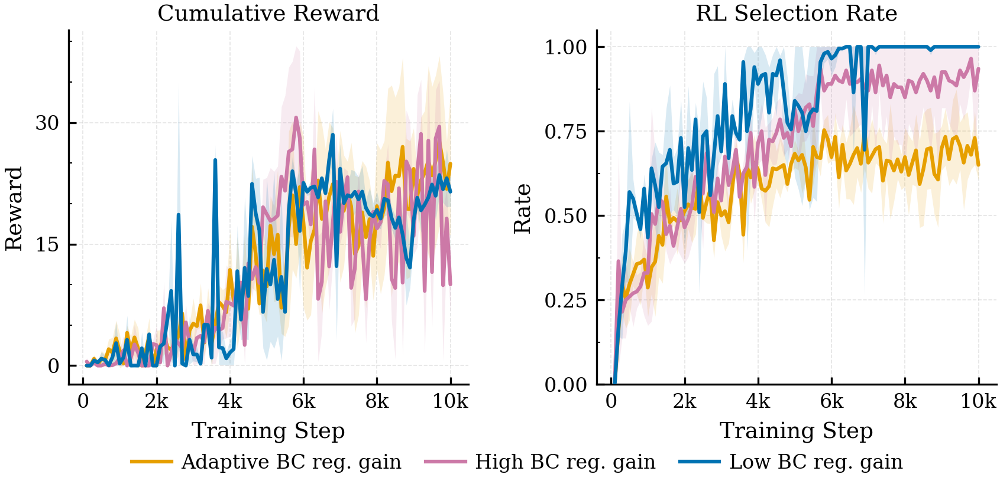

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# # ---------- Q experiment data ----------
# df201 = pd.read_csv("./results/openbox/reward/2.00.csv")
# df202 = pd.read_csv("./results/openbox/reward/2.01.csv")
# df203 = pd.read_csv("./results/openbox/reward/2.02.csv")

df211 = pd.read_csv("./results/openbox/reward/2.7_awr_utd1.csv")
df212 = pd.read_csv("./results/openbox/reward/2.71_utd1.csv")
df213 = pd.read_csv("./results/openbox/reward/2.7_utd1.csv")

df221 = pd.read_csv("./results/openbox/reward/2.7_highgain.csv")
df222 = pd.read_csv("./results/openbox/reward/2.7_highgain2.csv")


df231 = pd.read_csv("./results/openbox/reward/2.7_low_bc_gain.csv")
df232 = pd.read_csv("./results/openbox/reward/2.7_lowgain.csv")
# df233 = pd.read_csv("./results/openbox/reward/2.6_awr_utd1.csv")

# --- load aql data ---

# df301 = pd.read_csv("./results/openbox/rate/2.00.csv")
# df302 = pd.read_csv("./results/openbox/rate/2.01.csv")
# df303 = pd.read_csv("./results/openbox/rate/2.02.csv")

df311 = pd.read_csv("./results/openbox/rate/2.7_awr_utd1.csv")
df312 = pd.read_csv("./results/openbox/rate/2.71_utd1.csv")
df313 = pd.read_csv("./results/openbox/rate/2.7_utd1.csv")

df321 = pd.read_csv("./results/openbox/rate/2.7_highgain.csv")
df322 = pd.read_csv("./results/openbox/rate/2.7_highgain2.csv")
# df323 = pd.read_csv("./results/openbox/rate/2.6_utd1.csv")

df331 = pd.read_csv("./results/openbox/rate/2.7_low_bc_gain.csv")
df332 = pd.read_csv("./results/openbox/rate/2.7_lowgain.csv")
# df333 = pd.read_csv("./results/openbox/rate/2.6_awr_utd1.csv")



# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def split_episodes(path):
    df = pd.read_csv(path)
    df["truncated.0"]  = df["truncated.0"].astype(int)
    df["terminated.0"] = df["terminated.0"].astype(int)
    df["rewards.0"]    = df["rewards.0"].astype(float)
    ep_end = ((df["truncated.0"] == 1) | (df["terminated.0"] == 1)).astype(int)
    ep_ids = ep_end.shift(1, fill_value=0).cumsum()
    return [g.reset_index(drop=True) for _, g in df.groupby(ep_ids)]

def mc_return(ep):
    r = ep["rewards.0"].to_numpy(float)
    return float(np.dot(GAMMA ** np.arange(len(r)), r))

def load_q(path, q_col=None):
    df = pd.read_csv(path)
    if q_col is None:
        candidates = ["mean_q","q_mean","Q_mean","estimated_mean_q","q","value"]
        q_col = next((c for c in candidates if c in df.columns), None)
        if q_col is None:
            num = df.select_dtypes(include=[np.number]).columns.tolist()
            q_col = next((c for c in num if "q" in c.lower() or "value" in c.lower()), num[0])
    return pd.to_numeric(df[q_col], errors="coerce").dropna().to_numpy(float)

def smooth(x, w=7):
    return uniform_filter1d(np.asarray(x, float), size=w, mode="nearest") if len(x) >= w else np.asarray(x, float)


def aggregate_runs(dfs):
    merged = None
    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(columns={"Value": f"v{i}"})
        merged = tmp if merged is None else pd.merge(merged, tmp, on="Step", how="inner")

    merged = merged.sort_values("Step")
    steps = merged["Step"].to_numpy()
    values = merged.drop(columns=["Step"]).to_numpy(dtype=float)

    mean = values.mean(axis=1)
    std = values.std(axis=1, ddof=1)

    return steps, values, mean, std



IQL_groups = [
    ("Adaptive BC reg. gain",     [df211, df212, df213]),
    # ("Q* in policy extraction",     [df221, df222]),
    # ("Q* in both",     [df231, df232]),
]

IQL_groups2 = [
    # ("Q* in data incorporation",     [df211, df212, df213]),
    ("High BC reg. gain",     [df221, df222]),
    ("Low BC reg. gain",     [df231, df232]),
]

rate_groups = [
    # ("w/ Q", [df301, df302, df303]),
    ("Adaptive BC reg. gain",      [df311, df312, df313]),
    ("High BC reg. gain",     [df321, df322]),
    ("Low BC reg. gain",     [df331, df332]),
]




# ══════════════════════════════════════════════════════════════════════════
# PUBLICATION STYLE  (IEEE / NeurIPS / ICML)
# ══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({
    # --- font ---
    "font.family":        "serif",
    "font.serif":         ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset":   "stix",          # matches Times in math mode
    "font.size":          9,
    "axes.titlesize":     9,
    "axes.labelsize":     9,
    "xtick.labelsize":    8,
    "ytick.labelsize":    8,
    "legend.fontsize":    8,
    "legend.title_fontsize": 8,

    # --- lines / markers ---
    "lines.linewidth":    1.5,
    "patch.linewidth":    0.5,

    # --- axes ---
    "axes.linewidth":     0.8,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.grid":          True,
    "grid.linestyle":     "--",
    "grid.linewidth":     0.4,
    "grid.alpha":         0.4,
    "grid.color":         "#bbbbbb",

    # --- ticks ---
    "xtick.direction":    "in",
    "ytick.direction":    "in",
    "xtick.major.width":  0.8,
    "ytick.major.width":  0.8,
    "xtick.major.size":   3.0,
    "ytick.major.size":   3.0,

    # --- output ---
    "figure.dpi":         300,
    "savefig.dpi":        300,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.02,
})

# ── Colorblind-safe palette (Wong 2011) ───────────────────────────────────
COLORS = {
    "Low BC reg. gain":             "#0072B2",   # blue
    "High BC reg. gain":            "#CC79A7",   # violet
    # "w/ Q + BC reg.":   "#009E73",   # green
    "Adaptive BC reg. gain":   "#E69F00",   # amber
    # "replay":           "#999999",   # grey
}

DASHES = {
    "Adaptive BC reg. gain":             (None, None),       # solid
    "High BC reg. gain":            (None, None),           # dashed
    "Low BC reg. gain":   (None, None),       # dash-dot
    # "replay":           (0, (4, 1.5)),          # dash-dot-dot
}

# ── Figure — two-column friendly (6.75 in wide, golden-ratio height) ──────
FIG_W, FIG_H = 6.75, 2.6
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
fig.subplots_adjust(wspace=0.32)

# ════════════════════════════════════════════════════════════
# LEFT  — Cumulative Reward
# ════════════════════════════════════════════════════════════
ax0 = axes[0]

for name, dfs in IQL_groups:
    steps, values, mean, std = aggregate_runs(dfs)
    c  = COLORS[name]
    ls = DASHES[name]

    ax0.plot(steps, mean, color=c, linewidth=1.5,
             dashes=ls if ls[0] else [],
             solid_capstyle="round", label=name, zorder=3)

    ax0.fill_between(steps,
                     mean - std / 1.5,
                     mean + std / 1.5,
                     color=c, alpha=0.15, linewidth=0, zorder=2)
    
for name, dfs in IQL_groups2:
    steps, values, mean, std = aggregate_runs(dfs)
    c  = COLORS[name]
    ls = DASHES[name]

    ax0.plot(steps, mean/2, color=c, linewidth=1.5,
             dashes=ls if ls[0] else [],
             solid_capstyle="round", label=name, zorder=3)

    ax0.fill_between(steps,
                     mean/2 - std / 3,
                     mean/2 + std / 3,
                     color=c, alpha=0.15, linewidth=0, zorder=2)


# # replay baseline
# ax0.plot(df00["Step"], df00["Value"]*0,
#          color=COLORS["replay"], linewidth=1.2,
#          linestyle=(0, (4, 1.5)),          # dash-dot-dot
#          label="Replay", zorder=3)

ax0.set_title(r"Cumulative Reward", loc="center", pad=4)
ax0.set_xlabel("Training Step")
ax0.set_ylabel("Reward")
# ax0.set_ylim(0, 34)
ax0.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax0.yaxis.set_major_locator(mticker.MultipleLocator(15))
ax0.yaxis.set_minor_locator(mticker.MultipleLocator(5))
ax0.tick_params(which="minor", length=1.5, width=0.5)

# ════════════════════════════════════════════════════════════
# RIGHT — RL Selection Rate
# ════════════════════════════════════════════════════════════
ax1 = axes[1]

for name, dfs in rate_groups:
    steps, values, mean, std = aggregate_runs(dfs)

    # Pin first point to 0.0 (start-of-training convention)
    values[0, :] = 0.0
    mean[0]      = 0.0
    std[0]       = 0.0

    c  = COLORS[name]
    ls = DASHES[name]

    ax1.plot(steps, mean, color=c, linewidth=1.5,
             dashes=ls if ls[0] else [],
             solid_capstyle="round", label=name, zorder=3)

    ax1.fill_between(steps,
                 np.clip(mean - std, 0.0, 1.0),
                 np.clip(mean + std, 0.0, 1.0),
                     color=c, alpha=0.15, linewidth=0, zorder=2)

ax1.set_title(r"RL Selection Rate", loc="center", pad=4)
ax1.set_xlabel("Training Step")
ax1.set_ylabel("Rate")
ax1.set_ylim(0, 1.05)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(
    lambda x, _: f"{x/1e3:.0f}k" if x >= 1000 else f"{x:.0f}"))
ax1.yaxis.set_major_locator(mticker.MultipleLocator(0.25))
ax1.yaxis.set_minor_locator(mticker.MultipleLocator(0.125))
ax1.tick_params(which="minor", length=1.5, width=0.5)


# ════════════════════════════════════════════════════════════
# SHARED LEGEND  (single legend below both panels)
# ════════════════════════════════════════════════════════════
legend_handles = [
    Line2D([0], [0], color=COLORS[n],
           linewidth=1.5,
           dashes=DASHES[n] if DASHES[n][0] else [],
           label=n)
    for n in ["Adaptive BC reg. gain","High BC reg. gain", "Low BC reg. gain"]
]
# legend_handles.append(
#     Line2D([0], [0], color=COLORS["replay"], linewidth=1.2,
#            linestyle=(0, (4, 1.5)), label="Replay")
# )

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, -0.12),
    handlelength=2.0,
    columnspacing=1.2,
    handletextpad=0.5,
)

# ════════════════════════════════════════════════════════════
# SAVE
# ════════════════════════════════════════════════════════════
out = "results/exp4_openbox"
fig.savefig(f"{out}.pdf", facecolor="white")
fig.savefig(f"{out}.png", facecolor="white")
print(f"Saved → {out}.pdf / .png")
plt.show()

Saved → ./results/exp4_openbox.pdf / .png


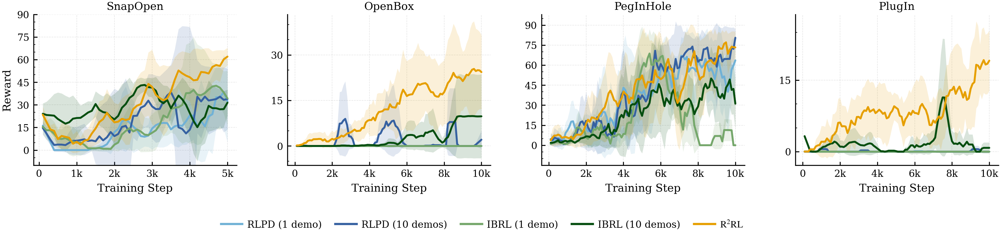

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from scipy.ndimage import uniform_filter1d


# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def smooth(x, w=7):
    x = np.asarray(x, dtype=float)
    if len(x) < w:
        return x
    return uniform_filter1d(x, size=w, mode="nearest")


def aggregate_runs(dfs):
    """
    Merge runs by common training steps and compute mean/std.
    """
    merged = None

    for i, df in enumerate(dfs):
        tmp = df[["Step", "Value"]].rename(
            columns={"Value": f"v{i}"}
        )

        if merged is None:
            merged = tmp
        else:
            merged = pd.merge(
                merged,
                tmp,
                on="Step",
                how="inner"
            )

    merged = merged.sort_values("Step")

    steps = merged["Step"].to_numpy()

    values = merged.drop(
        columns=["Step"]
    ).to_numpy(dtype=float)

    mean = values.mean(axis=1)
    std = values.std(axis=1, ddof=1)

    return steps, values, mean, std


# ══════════════════════════════════════════════════════════════════════════
# LOAD DATA
# ══════════════════════════════════════════════════════════════════════════

# ---------------- SnapOpen ----------------
df101 = pd.read_csv("./results/snapopen/reward/exp0_0.200.csv")
df102 = pd.read_csv("./results/snapopen/reward/exp0_0.203.csv")

df111 = pd.read_csv("./results/snapopen/reward/exp0_0.000.csv")
df112 = pd.read_csv("./results/snapopen/reward/exp0_0.001.csv")
df113 = pd.read_csv("./results/snapopen/reward/exp0_1.00.csv")

df121 = pd.read_csv("./results/iql/2.100_maxq.csv")
df122 = pd.read_csv("./results/iql/2.101_maxq.csv")
df123 = pd.read_csv("./results/iql/2.102_maxq.csv")

df131 = pd.read_csv("./results/snapopen/reward/exp0_2.102.csv")
df132 = pd.read_csv("./results/snapopen/reward/exp0_2.105.csv")

df141 = pd.read_csv("./results/iql/2.40.csv")
df142 = pd.read_csv("./results/iql/2.41.csv")
df143 = pd.read_csv("./results/iql/2.42.csv")


# ---------------- OpenBox ----------------
df201 = pd.read_csv("./results/openbox/reward1/exp1_RLPD1_0.csv")
df202 = pd.read_csv("./results/openbox/reward1/exp1_rlpd1_1.csv")

df211 = pd.read_csv("./results/openbox/reward1/exp1_RLPD10_0.csv")
df212 = pd.read_csv("./results/openbox/reward1/exp1_RLPD_10.csv")

df221 = pd.read_csv("./results/openbox/reward/2.00.csv")
df222 = pd.read_csv("./results/openbox/reward/2.01.csv")
df223 = pd.read_csv("./results/openbox/reward/2.02.csv")

df231 = pd.read_csv("./results/openbox/reward1/exp1_IBRL1.csv")
df232 = pd.read_csv("./results/openbox/reward1/exp1_IBRL2.csv")

df241 = pd.read_csv("./results/openbox/reward/2.7_awr_utd1.csv")
df242 = pd.read_csv("./results/openbox/reward/2.71_utd1.csv")
df243 = pd.read_csv("./results/openbox/reward/2.7_utd1.csv")


# ---------------- PegInHole ----------------
df301 = pd.read_csv("./results/peginhole/RLPD_1demo0.csv")
df302 = pd.read_csv("./results/peginhole/RLPD_1demo1.csv")
df303 = pd.read_csv("./results/peginhole/RLPD_1demo02.csv")

df311 = pd.read_csv("./results/peginhole/RLPD_10demo01.csv")
df312 = pd.read_csv("./results/peginhole/RLPD_10demo02.csv")

df321 = pd.read_csv("./results/peginhole/IBRL_1demo0.csv")
df322 = pd.read_csv("./results/peginhole/IBRL_1demo1.csv")

df331 = pd.read_csv("./results/peginhole/IBRL_10demo0.csv")
df332 = pd.read_csv("./results/peginhole/IBRL_10demos1.csv")

df341 = pd.read_csv("./results/peginhole/osrl0.csv")
df342 = pd.read_csv("./results/peginhole/osrl1.csv")
df343 = pd.read_csv("./results/peginhole/osrl2.csv")


# ---------------- Assembly ----------------
df401 = pd.read_csv("./results/assembly/exp1_RLPD_1demo.csv")
df402 = pd.read_csv("./results/assembly/exp1_RLPD_1demo1.csv")

df411 = pd.read_csv("./results/assembly/exp1_RLPD_10demo0.csv")
df412 = pd.read_csv("./results/assembly/exp1_RLPD_10demo1.csv")

df421 = pd.read_csv("./results/assembly/exp1_IBRL1.csv")
df422 = pd.read_csv("./results/assembly/exp1_RLPD_1demo1.csv")

df431 = pd.read_csv("./results/assembly/exp1_IBRL10_demo.csv")
df432 = pd.read_csv("./results/assembly/exp1_ibrl10_demo1.csv")

df441 = pd.read_csv("./results/assembly/exp1_osrl0.csv")
df442 = pd.read_csv("./results/assembly/exp1_osrl1.csv")
df443 = pd.read_csv("./results/assembly/exp1_osrl2.csv")


# ══════════════════════════════════════════════════════════════════════════
# GROUPS
# ══════════════════════════════════════════════════════════════════════════
snapopen_groups = [
    ("RLPD (1 demo)",  [df101, df102]),
    ("RLPD (10 demos)", [df111, df112, df113]),
    ("IBRL (1 demo)",  [df121, df122, df123]),
    ("IBRL (10 demos)", [df131, df132]),
    ("OSRL", [df141, df142, df143]),
]

openbox_groups = [
    ("RLPD (1 demo)",  [df201, df202]),
    ("RLPD (10 demos)", [df211, df212]),
    ("IBRL (1 demo)",  [df221, df222, df223]),
    ("IBRL (10 demos)", [df231, df232]),
    ("OSRL", [df241, df242, df243]),
]

peginhole_groups = [
    ("RLPD (1 demo)",  [df301, df302, df303]),
    ("RLPD (10 demos)", [df311, df312]),
    ("IBRL (1 demo)",  [df321, df322]),
    ("IBRL (10 demos)", [df331, df332]),
    ("OSRL", [df341, df342, df343]),
]

assembly_groups = [
    ("RLPD (1 demo)",  [df401, df402]),
    ("RLPD (10 demos)", [df411, df412]),
    ("IBRL (1 demo)",  [df421, df422]),
    ("IBRL (10 demos)", [df431, df432]),
    ("OSRL", [df441, df442, df443]),
]


# ══════════════════════════════════════════════════════════════════════════
# PUBLICATION STYLE
# ══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({

    # fonts
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "mathtext.fontset": "stix",

    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # lines
    "lines.linewidth": 1.5,
    "patch.linewidth": 0.5,

    # axes
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,

    # grid
    "grid.linestyle": "--",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.4,
    "grid.color": "#bbbbbb",

    # ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,

    # output
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})


# ══════════════════════════════════════════════════════════════════════════
# COLORS
# ══════════════════════════════════════════════════════════════════════════
COLORS = {
    "RLPD (1 demo)":   "#70B1D6",
    "RLPD (10 demos)": "#3661A1",
    "IBRL (1 demo)":   "#75A76B",
    "IBRL (10 demos)": "#064E10",
    "OSRL":            "#E69F00",
}

DASHES = {
    "RLPD (1 demo)":   (),
    "RLPD (10 demos)": (),
    "IBRL (1 demo)":   (),
    "IBRL (10 demos)": (),
    "OSRL":            (),
}


# ══════════════════════════════════════════════════════════════════════════
# FIGURE
# ══════════════════════════════════════════════════════════════════════════
FIG_W = 12
FIG_H = 2.8

fig, axes = plt.subplots(
    1,
    4,
    figsize=(FIG_W, FIG_H),
    sharey=False
)

fig.subplots_adjust(
    left=0.07,
    right=0.995,
    top=0.90,
    bottom=0.28,
    wspace=0.25
)


all_groups = [
    snapopen_groups,
    openbox_groups,
    peginhole_groups,
    assembly_groups,
]

titles = [
    "SnapOpen",
    "OpenBox",
    "PegInHole",
    "PlugIn",
]


# ══════════════════════════════════════════════════════════════════════════
# PLOT
# ══════════════════════════════════════════════════════════════════════════
for ax, groups, title in zip(axes, all_groups, titles):

    for name, dfs in groups:

        steps, values, mean, std = aggregate_runs(dfs)

        mean = smooth(mean, w=5)
        std = smooth(std, w=5)

        # scale std for first two plots
        std_scale = 2 if ax in [0, 1] else 1.0

        color = COLORS[name]

        ax.plot(
            steps,
            mean,
            color=color,
            linewidth=1.6,
            label=name,
            solid_capstyle="round",
            zorder=3,
        )

        ax.fill_between(
            steps,
            mean - std / std_scale,
            mean + std / std_scale,
            color=color,
            alpha=0.15,
            linewidth=0,
            zorder=2,
        )

    ax.set_title(title, pad=4)

    ax.set_xlabel("Training Step")

    ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(
            lambda x, _: (
                f"{x/1e3:.0f}k"
                if x >= 1000
                else f"{x:.0f}"
            )
        )
    )

    ax.yaxis.set_major_locator(
        mticker.MultipleLocator(15)
    )

    ax.yaxis.set_minor_locator(
        mticker.MultipleLocator(5)
    )

    ax.tick_params(
        which="minor",
        length=1.5,
        width=0.5
    )

axes[0].set_ylabel("Reward")
axes[0].set_ylim(-10, 90)

# ══════════════════════════════════════════════════════════════════════════
# LEGEND
# ══════════════════════════════════════════════════════════════════════════
legend_handles = [
    Line2D(
        [0],
        [0],
        color=COLORS[name],
        linewidth=1.8,
        label=r"$\mathrm{R}^{2}\mathrm{RL}$" if name == "OSRL" else name,
    )
    for name in [
        "RLPD (1 demo)",
        "RLPD (10 demos)",
        "IBRL (1 demo)",
        "IBRL (10 demos)",
        "OSRL",
    ]
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, -0.02),
    handlelength=2.2,
    columnspacing=1.4,
    handletextpad=0.5,
)


# ══════════════════════════════════════════════════════════════════════════
# SAVE
# ══════════════════════════════════════════════════════════════════════════
out = "./results/exp4_openbox"

fig.savefig(
    f"{out}.pdf",
    facecolor="white"
)

fig.savefig(
    f"{out}.png",
    facecolor="white"
)

print(f"Saved → {out}.pdf / .png")

plt.show()

Saved → ./results/last10_rewards_runs.pdf / .png


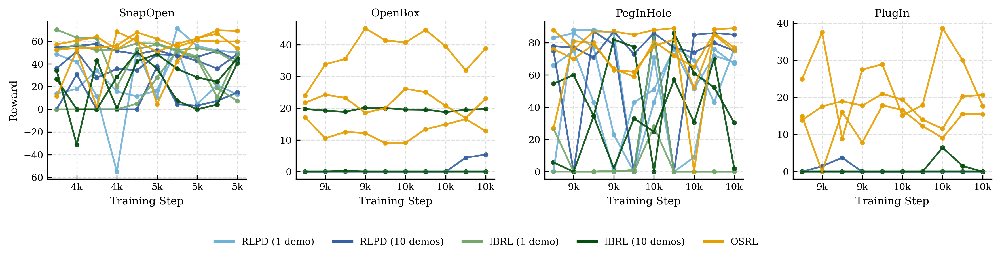

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D


# ══════════════════════════════════════════════════════════════════════════
# HELPERS
# ══════════════════════════════════════════════════════════════════════════
def get_last_n(df, n=10):
    """
    Get last n timesteps from a run.
    """
    df = df.sort_values("Step")
    return df.tail(n)


# ══════════════════════════════════════════════════════════════════════════
# LOAD DATA
# ══════════════════════════════════════════════════════════════════════════

# ---------------- SnapOpen ----------------
df101 = pd.read_csv("./results/snapopen/reward/exp0_0.200.csv")
df102 = pd.read_csv("./results/snapopen/reward/exp0_0.203.csv")

df111 = pd.read_csv("./results/snapopen/reward/exp0_0.000.csv")
df112 = pd.read_csv("./results/snapopen/reward/exp0_0.001.csv")
df113 = pd.read_csv("./results/snapopen/reward/exp0_1.00.csv")

df121 = pd.read_csv("./results/iql/2.100_maxq.csv")
df122 = pd.read_csv("./results/iql/2.101_maxq.csv")
df123 = pd.read_csv("./results/iql/2.102_maxq.csv")

df131 = pd.read_csv("./results/snapopen/reward/exp0_2.102.csv")
df132 = pd.read_csv("./results/snapopen/reward/exp0_2.105.csv")

df141 = pd.read_csv("./results/iql/2.40.csv")
df142 = pd.read_csv("./results/iql/2.41.csv")
df143 = pd.read_csv("./results/iql/2.42.csv")


# ---------------- OpenBox ----------------
df201 = pd.read_csv("./results/openbox/reward1/exp1_RLPD1_0.csv")
df202 = pd.read_csv("./results/openbox/reward1/exp1_rlpd1_1.csv")

df211 = pd.read_csv("./results/openbox/reward1/exp1_RLPD10_0.csv")
df212 = pd.read_csv("./results/openbox/reward1/exp1_RLPD_10.csv")

df221 = pd.read_csv("./results/openbox/reward/2.00.csv")
df222 = pd.read_csv("./results/openbox/reward/2.01.csv")
df223 = pd.read_csv("./results/openbox/reward/2.02.csv")

df231 = pd.read_csv("./results/openbox/reward1/exp1_IBRL1.csv")
df232 = pd.read_csv("./results/openbox/reward1/exp1_IBRL2.csv")

df241 = pd.read_csv("./results/openbox/reward/2.7_awr_utd1.csv")
df242 = pd.read_csv("./results/openbox/reward/2.71_utd1.csv")
df243 = pd.read_csv("./results/openbox/reward/2.7_utd1.csv")


# ---------------- PegInHole ----------------
df301 = pd.read_csv("./results/peginhole/RLPD_1demo0.csv")
df302 = pd.read_csv("./results/peginhole/RLPD_1demo1.csv")
df303 = pd.read_csv("./results/peginhole/RLPD_1demo02.csv")

df311 = pd.read_csv("./results/peginhole/RLPD_10demo01.csv")
df312 = pd.read_csv("./results/peginhole/RLPD_10demo02.csv")

df321 = pd.read_csv("./results/peginhole/IBRL_1demo0.csv")
df322 = pd.read_csv("./results/peginhole/IBRL_1demo1.csv")

df331 = pd.read_csv("./results/peginhole/IBRL_10demo0.csv")
df332 = pd.read_csv("./results/peginhole/IBRL_10demos1.csv")

df341 = pd.read_csv("./results/peginhole/osrl0.csv")
df342 = pd.read_csv("./results/peginhole/osrl1.csv")
df343 = pd.read_csv("./results/peginhole/osrl2.csv")


# ---------------- Assembly ----------------
df401 = pd.read_csv("./results/assembly/exp1_RLPD_1demo.csv")
df402 = pd.read_csv("./results/assembly/exp1_RLPD_1demo1.csv")

df411 = pd.read_csv("./results/assembly/exp1_RLPD_10demo0.csv")
df412 = pd.read_csv("./results/assembly/exp1_RLPD_10demo1.csv")

df421 = pd.read_csv("./results/assembly/exp1_IBRL1.csv")
df422 = pd.read_csv("./results/assembly/exp1_RLPD_1demo1.csv")

df431 = pd.read_csv("./results/assembly/exp1_IBRL10_demo.csv")
df432 = pd.read_csv("./results/assembly/exp1_ibrl10_demo1.csv")

df441 = pd.read_csv("./results/assembly/exp1_osrl0.csv")
df442 = pd.read_csv("./results/assembly/exp1_osrl1.csv")
df443 = pd.read_csv("./results/assembly/exp1_osrl2.csv")


# ══════════════════════════════════════════════════════════════════════════
# GROUPS
# ══════════════════════════════════════════════════════════════════════════
snapopen_groups = [
    ("RLPD (1 demo)",  [df101, df102]),
    ("RLPD (10 demos)", [df111, df112, df113]),
    ("IBRL (1 demo)",  [df121, df122, df123]),
    ("IBRL (10 demos)", [df131, df132]),
    ("OSRL", [df141, df142, df143]),
]

openbox_groups = [
    ("RLPD (1 demo)",  [df201, df202]),
    ("RLPD (10 demos)", [df211, df212]),
    ("IBRL (1 demo)",  [df221, df222, df223]),
    ("IBRL (10 demos)", [df231, df232]),
    ("OSRL", [df241, df242, df243]),
]

peginhole_groups = [
    ("RLPD (1 demo)",  [df301, df302, df303]),
    ("RLPD (10 demos)", [df311, df312]),
    ("IBRL (1 demo)",  [df321, df322]),
    ("IBRL (10 demos)", [df331, df332]),
    ("OSRL", [df341, df342, df343]),
]

assembly_groups = [
    ("RLPD (1 demo)",  [df401, df402]),
    ("RLPD (10 demos)", [df411, df412]),
    ("IBRL (1 demo)",  [df421, df422]),
    ("IBRL (10 demos)", [df431, df432]),
    ("OSRL", [df441, df442, df443]),
]


# ══════════════════════════════════════════════════════════════════════════
# STYLE
# ══════════════════════════════════════════════════════════════════════════
plt.rcParams.update({

    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],

    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    "axes.spines.top": False,
    "axes.spines.right": False,

    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.4,

    "figure.dpi": 300,
    "savefig.dpi": 300,
})


# ══════════════════════════════════════════════════════════════════════════
# COLORS
# ══════════════════════════════════════════════════════════════════════════
COLORS = {
    "RLPD (1 demo)":   "#70B1D6",
    "RLPD (10 demos)": "#3661A1",
    "IBRL (1 demo)":   "#75A76B",
    "IBRL (10 demos)": "#064E10",
    "OSRL":            "#E69F00",
}


# ══════════════════════════════════════════════════════════════════════════
# FIGURE
# ══════════════════════════════════════════════════════════════════════════
fig, axes = plt.subplots(
    1,
    4,
    figsize=(12, 3),
    sharey=False
)

fig.subplots_adjust(
    left=0.07,
    right=0.995,
    top=0.90,
    bottom=0.28,
    wspace=0.25
)

all_groups = [
    snapopen_groups,
    openbox_groups,
    peginhole_groups,
    assembly_groups,
]

titles = [
    "SnapOpen",
    "OpenBox",
    "PegInHole",
    "PlugIn",
]


# ══════════════════════════════════════════════════════════════════════════
# PLOT ONLY LAST 10 TIMESTEPS OF EACH RUN
# ══════════════════════════════════════════════════════════════════════════
for ax, groups, title in zip(axes, all_groups, titles):

    for method_name, dfs in groups:

        color = COLORS[method_name]

        for run_idx, df in enumerate(dfs):

            last_df = get_last_n(df, n=10)

            ax.plot(
                last_df["Step"],
                last_df["Value"],
                color=color,
                linewidth=1.5,
                alpha=0.9,
            )

            ax.scatter(
                last_df["Step"],
                last_df["Value"],
                color=color,
                s=10,
                alpha=0.9,
            )

    ax.set_title(title, pad=4)

    ax.set_xlabel("Training Step")

    ax.xaxis.set_major_formatter(
        mticker.FuncFormatter(
            lambda x, _: (
                f"{x/1e3:.0f}k"
                if x >= 1000
                else f"{x:.0f}"
            )
        )
    )

    ax.tick_params(direction="in")

axes[0].set_ylabel("Reward")


# ══════════════════════════════════════════════════════════════════════════
# LEGEND
# ══════════════════════════════════════════════════════════════════════════
legend_handles = [
    Line2D(
        [0],
        [0],
        color=COLORS[name],
        linewidth=2,
        label=name,
    )
    for name in COLORS.keys()
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, -0.02),
)


# ══════════════════════════════════════════════════════════════════════════
# SAVE
# ══════════════════════════════════════════════════════════════════════════
out = "./results/last10_rewards_runs"

fig.savefig(f"{out}.pdf", facecolor="white")
fig.savefig(f"{out}.png", facecolor="white")

print(f"Saved → {out}.pdf / .png")

plt.show()

In [3]:
# Copy this helper function and execution block into your script
def compute_success_rates(all_groups, titles, thresholds):
    results = {}
    for groups, title, thresh in zip(all_groups, titles, thresholds):
        results[title] = {}
        for method_name, dfs in groups:
            successful_runs = 0
            total_runs = len(dfs)
            
            for df in dfs:
                # Get last 10 timesteps using your existing helper
                last_df = get_last_n(df, n=10)
                mean_reward = last_df["Value"].mean()
                
                if mean_reward >= thresh:
                    successful_runs += 1
            
            success_rate = successful_runs / total_runs if total_runs > 0 else 0
            results[title][method_name] = {
                "fraction": f"({successful_runs}/{total_runs})",
                "rate": success_rate
            }
    return results

# Define thresholds based on your prompt
thresholds = [18, 5, 10, 8]  # SnapOpen, OpenBox, PegInHole, PlugIn

# Compute them
success_data = compute_success_rates(all_groups, titles, thresholds)

# Print results cleanly
for task, methods in success_data.items():
    print(f"\n═══ {task} (Threshold: {thresholds[titles.index(task)]}) ═══")
    for method, info in methods.items():
        print(f"{method:<18}: {info['rate']:.1%} {info['fraction']}")


═══ SnapOpen (Threshold: 18) ═══
RLPD (1 demo)     : 100.0% (2/2)
RLPD (10 demos)   : 66.7% (2/3)
IBRL (1 demo)     : 66.7% (2/3)
IBRL (10 demos)   : 100.0% (2/2)
OSRL              : 100.0% (3/3)

═══ OpenBox (Threshold: 5) ═══
RLPD (1 demo)     : 0.0% (0/2)
RLPD (10 demos)   : 0.0% (0/2)
IBRL (1 demo)     : 0.0% (0/3)
IBRL (10 demos)   : 50.0% (1/2)
OSRL              : 100.0% (3/3)

═══ PegInHole (Threshold: 10) ═══
RLPD (1 demo)     : 100.0% (3/3)
RLPD (10 demos)   : 100.0% (2/2)
IBRL (1 demo)     : 0.0% (0/2)
IBRL (10 demos)   : 100.0% (2/2)
OSRL              : 100.0% (3/3)

═══ PlugIn (Threshold: 8) ═══
RLPD (1 demo)     : 0.0% (0/2)
RLPD (10 demos)   : 0.0% (0/2)
IBRL (1 demo)     : 0.0% (0/2)
IBRL (10 demos)   : 0.0% (0/2)
OSRL              : 100.0% (3/3)


ValueError: 'upper font' is not a valid value for loc; supported values are 'best', 'upper right', 'upper left', 'lower left', 'lower right', 'right', 'center left', 'center right', 'lower center', 'upper center', 'center'

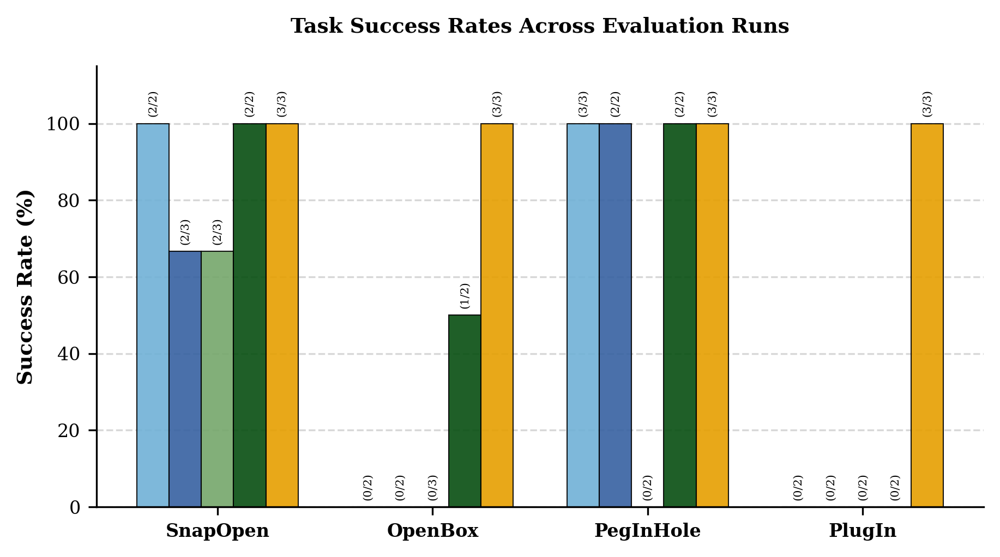

In [4]:
# ══════════════════════════════════════════════════════════════════════════
# CONFERENCE STYLE SUCCESS RATE PLOT
# ══════════════════════════════════════════════════════════════════════════

# Extract data for plotting from the compute function
tasks = titles
methods = list(COLORS.keys())

# Setup figure - clean, single-window layout matching top conferences
fig, ax = plt.subplots(figsize=(7, 3.5), dpi=300)

x = np.arange(len(tasks))  # Task locations
width = 0.15               # Width of bars

# Plot bars for each method
for i, method in enumerate(methods):
    rates = [success_data[task][method]["rate"] * 100 for task in tasks]
    fractions = [success_data[task][method]["fraction"] for task in tasks]
    
    # Offset each method group dynamically
    offset = (i - len(methods)/2) * width + width/2
    rects = ax.bar(x + offset, rates, width, label=method, color=COLORS[method], edgecolor='black', linewidth=0.5, alpha=0.9)
    
    # Add text labels (fractions) on top of bars for dead-simple transparency
    for rect, frac in zip(rects, fractions):
        height = rect.get_height()
        ax.annotate(frac,
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=5, rotation=90)

# Styling
ax.set_ylabel('Success Rate (%)', fontweight='bold')
ax.set_title('Task Success Rates Across Evaluation Runs', pad=15, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(tasks, fontweight='bold')
ax.set_ylim(0, 115) # Leave room for vertical labels

# Clean spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.8)
ax.spines['bottom'].set_linewidth(0.8)

# Minimal grid
ax.set_axisbelow(True)
ax.yaxis.grid(True, linestyle='--', alpha=0.5)
ax.xaxis.grid(False)

# Professional Legend placement
ax.legend(loc='upper font', bbox_to_anchor=(0.5, 1.12), ncol=5, frameon=False, fontsize=7.5)

plt.tight_layout()
fig.savefig("./results/success_rate_comparison.pdf", bbox_inches='tight')
plt.show()